In [ ]:
# ==============================================================================
# Purpose:
#   B-cell CNA + gene-program interpretation (race effect; NHB vs NHW):
#     (1) Run CNA neighborhood association for race within each B subtype × disease state,
#     (2) Correlate per-cell neighborhood race coefficient (race_coef) with gene expression
#         using a fast Spearman implementation,
#     (3) Run preranked GSEA (Hallmark + ImmPort) on gene-wise rho,
#     (4) Generate Figure 7.2 panels:
#         - B UMAPs: subtype, race, and significant neighborhood race_coef
#         - GSEA summaries: multi-panel barh NES across subtypes/states + bubble plots
#           per disease state for selected ImmPort sets.
#
# Steps:
#   1) Configure plotting defaults (Nature Immunology-ish), vector-friendly Scanpy.
#   2) Load sample metadata (meta_pt.csv) and define race-stage categories.
#   3) Load full AnnData (ft_all.h5ad) and map sample-level covariates into dat.obs
#      using dataset_name.
#   4) Encode covariates:
#        - diabetes/obesity: 'Y'->1 else 0
#        - group: HRL->0, DCIS->1, BC->2
#        - race: NHW->0, NHB->1
#   5) Subset major compartment (celltype_major='B') and attach precomputed UMAP coords.
#      Create disease_state labels from encoded group.
#   6) For each (B subtype × disease_state):
#        - subset cells
#        - compute neighbors (required by CNA)
#        - build sample-level design matrix (samplem) with covariates
#        - add batch label from sample name prefix (Pool137 vs Pool138)
#        - run cna.tl.association with race as exposure (key_added='race_coef')
#        - correlate race_coef vs genes (fast_spearman_ann) -> rho
#        - prerank GSEA on rho for Hallmark and ImmPort; save CSVs
#   7) Repeat CNA + Spearman + GSEA for "all B cells" within each disease_state
#      (ignores subtype stratification).
#   8) Load precomputed CNA object overall_B.pkl to plot UMAP panels:
#        - B subtypes (ordered categorical + palette)
#        - race (NHW/NHB)
#        - neighborhood coefficient map (race_coef shown only if FDR<0.1; else gray)
#      Summarize subtype composition among significant +/− coefficients.
#   9) Aggregate per-(subtype × state × db) GSEA CSVs into a single table `out`
#      and reformat columns:
#        - Tag % parsed -> percent
#        - log_p = -log10(FDR q-val)
#        - Term cleaned (strip HALLMARK_ and uppercase)
#  10) Plot GSEA summaries:
#        - Barh NES panels for selected terms across subtypes/states (multi-panel figure)
#        - Bubble plots per disease state (NES vs pathway; size=Tag%; color=-log10 q)

# Header

In [3]:
from utils import *

In [4]:
import sys
sys.path.insert(0, '/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src')
import cna

In [5]:
import gseapy as gp
import scanpy as sc
from itertools import product
from matplotlib.patches import Patch
from textwrap import fill

In [6]:
os.chdir('../')

In [7]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [8]:
cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}

In [9]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from scipy import sparse
from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests

def fast_spearman_ann(adata, obs_key, genes=None, chunk_size=2000, eps=1e-12):
    """
    Fast Spearman correlation between a per-cell variable (obs_key)
    and expression of each gene in adata.
    Returns a DataFrame with columns: rho, pval, fdr.
    """
    if genes is None:
        genes = adata.var_names
    X = adata[:, genes].X
    n_cells, n_genes = X.shape

    # rank-transform the covariate
    c = pd.to_numeric(adata.obs[obs_key], errors='coerce').to_numpy()
    r_c = rankdata(c, method='average')
    r_c0 = r_c - r_c.mean()
    norm_rc0 = np.linalg.norm(r_c0) + eps

    rho = np.empty(n_genes, dtype=float)

    for start in range(0, n_genes, chunk_size):
        end = min(start + chunk_size, n_genes)
        Xi = X[:, start:end]

        if sparse.issparse(Xi):
            Xi = Xi.toarray()

        # rank each gene (column) across cells
        R = np.apply_along_axis(rankdata, 0, Xi, method='average')
        R0 = R - R.mean(axis=0, keepdims=True)
        denomX = np.linalg.norm(R0, axis=0) + eps

        # Pearson on ranks = Spearman
        rho[start:end] = (R0.T @ r_c0) / (norm_rc0 * denomX)

    # --- p-values (two-sided) via t-approximation ---
    df = n_cells - 2
    # Clamp |rho| to < 1 to avoid division by zero
    rho_clamped = np.clip(rho, -1 + 1e-15, 1 - 1e-15)
    t_stat = rho_clamped * np.sqrt(df / (1 - rho_clamped**2))
    pval = 2 * student_t.sf(np.abs(t_stat), df=df)

    # --- FDR (Benjamini–Hochberg) ---
    fdr = multipletests(pval, method='fdr_bh')[1]

    out = pd.DataFrame(
        {'rho': rho, 'pval': pval, 'fdr': fdr},
        index=pd.Index(genes, name='gene')
    )
    out.name = f'spearman_{obs_key}'
    return out

# Load data

In [8]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', index_col=0)
#meta.index = [x.replace('_','-') for x in meta.index]

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL', 'NHW-DCIS', 'NHW-BC','NHB-HRL', 'NHB-DCIS', 'NHB-BC'],
    ordered=True
    )

meta

,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
sampleid,,,,,,,,,
9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS
30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,N,NHB-DCIS
119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,N,NHB-DCIS
28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [9]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)

dat.obs

,nFeaturess_RNA,nFeaturess_RNA_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublets_score,nCount_RNA,nFeature_RNA,percent.mt,predicted.celltype.l1.score,...,predicted.celltype.l3,mapping.score,RNA_snn_res.0.8,seurat_clusters,dataset_name,RNA_snn_res.0.1,S.Score,G2M.Score,Phase,celltype_level3
Pool137_10_AAACCTGAGACTCGGA-1,1095.0,1095,2669.0,80.0,2.997377,0.039230,2669.0,1095.0,2.997377,0.987477,...,CD4 TCM_1,0.827455,0,0,Pool137_10,0,-0.035611,-0.030749,G1,Naive CD4T
Pool137_10_AAACCTGAGATCTGCT-1,2474.0,2472,6188.0,178.0,2.876535,0.021953,6188.0,2472.0,2.876535,1.000000,...,CD16 Mono,0.740965,5,5,Pool137_10,5,0.004613,0.004461,S,Nonclassical Monocyte
Pool137_10_AAACCTGAGATTACCC-1,1436.0,1436,3504.0,100.0,2.853881,0.039230,3504.0,1436.0,2.853881,0.996618,...,CD8 Naive,0.874696,6,6,Pool137_10,6,0.027257,-0.066766,S,Naive CD8T
Pool137_10_AAACCTGAGCTGCGAA-1,1033.0,1033,2685.0,104.0,3.873371,0.053408,2685.0,1033.0,3.873371,0.990250,...,CD4 TCM_1,0.842401,0,0,Pool137_10,0,-0.049705,0.004598,G2M,Naive CD4T
Pool137_10_AAACCTGAGGACACCA-1,2518.0,2515,6370.0,189.0,2.967033,0.012493,6370.0,2515.0,2.967033,1.000000,...,CD16 Mono,0.836383,5,5,Pool137_10,5,0.003770,-0.014496,S,Nonclassical Monocyte
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pool138_9_TTTGTCATCCATGAAC-1,1309.0,1308,2604.0,43.0,1.651306,0.026204,2604.0,1308.0,1.651306,1.000000,...,CD14 Mono,0.925401,2,1,Pool138_9,1,0.128049,0.014490,S,Classical Monocyte
Pool138_9_TTTGTCATCCTAGGGC-1,1464.0,1464,3533.0,41.0,1.160487,0.105614,3533.0,1464.0,1.160487,1.000000,...,CD4 TCM_3,0.890462,5,0,Pool138_9,0,0.020027,-0.014519,S,Effector Memory CD4T
Pool138_9_TTTGTCATCGCACTCT-1,1310.0,1310,3125.0,56.0,1.792000,0.020296,3125.0,1310.0,1.792000,1.000000,...,CD4 TCM_1,0.842334,1,0,Pool138_9,0,-0.052514,-0.009035,G1,Naive CD4T
Pool138_9_TTTGTCATCTAACTGG-1,1774.0,1774,5072.0,107.0,2.109622,0.085158,5072.0,1774.0,2.109621,1.000000,...,CD4 TCM_1,0.824522,1,0,Pool138_9,0,-0.042068,0.002366,G2M,Naive CD4T


In [10]:
for col in ['age', 'race-stage', 'race', 'group', 'diabetes', 'obesity']:
    dat.obs[col] = dat.obs['dataset_name'].map(meta.set_index('dataset_name')[col])
    
for xcol in ['diabetes','obesity']:
    dat.obs[xcol] = [1 if x=='Y' else 0 for x in dat.obs[xcol]]

xcol = 'group'
dat.obs[xcol] = [0 if x=='HRL' else 1 if x=='DCIS' else 2 for x in dat.obs[xcol]]

xcol = 'race'
dat.obs[xcol] = [0 if x=='NHW' else 1 if x=='NHB' else None for x in dat.obs[xcol]]

dat.obs.columns

Index(['nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts',
       'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA',
       'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score',
       'predicted.celltype.l1', 'predicted.celltype.l2.score',
       'predicted.celltype.l2', 'predicted.celltype.l3.score',
       'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8',
       'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score',
       'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race',
       'group', 'diabetes', 'obesity'],
      dtype='object')

In [11]:
celltype_major = 'B'

In [12]:
d = dat[
    dat.obs['predicted.celltype.l1'] == celltype_major
]
d

View of AnnData object with n_obs × n_vars = 49158 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race', 'group', 'diabetes', 'obesity'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_counts.Pool137_11_variance.standa

In [13]:
umap = pd.read_csv(f"data/03_cleandata/ft_{celltype_major}_UmapCoords.csv",
                   index_col=2
                  ).loc[d.obs.index,:]

d.obsm['X_umap'] = umap.values

/tmp/ipykernel_996364/3805644948.py:5: ImplicitModificationWarning: Setting element `.obsm['X_umap']` of view, initializing view as actual.
  d.obsm['X_umap'] = umap.values


# Calc

## Celltype + DzState

In [18]:
# change back
xcol = 'group'
d.obs['disease_state'] = ['HRL' if x==0 else 'DCIS' if x==1 else 'BC' for x in d.obs[xcol]]


In [ ]:
for celltype in [
'Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'
]:
    for group in ['HRL','DCIS','BC']:
        
        d_sub = d[
        (d.obs['celltype_level3']==celltype) &
        (d.obs['disease_state']==group)
        ]
    
        sc.pp.neighbors(d_sub)

        covars = ['race', 'age']
        for v in ['obesity', 'diabetes']:
            if v in d_sub.obs and d_sub.obs[v].dropna().nunique() > 1:
                covars.append(v)
                
        samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                                       covars,     # the metadata columns to use
                                       'dataset_name')                        # the column of d.obs that contains sample IDs
        
        samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]
        
        
        res = cna.tl.association(
            d_sub,
            samplem.race, 
            'dataset_name',
            covs=samplem[[c for c in covars if c != 'race']],
            batches=samplem.batch,
            key_added='race_coef',
            return_full=True,
            allow_low_sample_size=True
        )

       
        
        res = fast_spearman_ann(d_sub, 
                            obs_key='race_coef', 
                            genes=d_sub.var_names, chunk_size=2000)
    
        gene_corr_df = pd.DataFrame(res)
        
        pre_res1 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                             gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                             threads=1,
                             min_size=5,
                             max_size=1000,
                             permutation_num=1000, # reduce number to speed up testing
                             outdir=None, # don't write to disk
                             seed=1024,
                             verbose=True, # see what's going on behind the scenes
                            ).res2d
    
        pre_res2 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                             gene_sets='data/11_genesets/immport_allgenelist.gmt',
                             threads=1,
                             min_size=5,
                             max_size=1000,
                             permutation_num=1000, # reduce number to speed up testing
                             outdir=None, # don't write to disk
                             seed=1024,
                             verbose=True, # see what's going on behind the scenes
                            ).res2d
    
        pre_res1.to_csv(f'data/Figure7_2/CNArankNHBvsW_{celltype}_{group}_hallmark.csv')
        pre_res2.to_csv(f'data/Figure7_2/CNArankNHBvsW_{celltype}_{group}_immport.csv')
        print(f'Done for {celltype}_{group}')
    


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.obs. Overwriting.")
2026-01-09 00:28:46,717 [WARNING] Duplicated values found in preranked stats: 21.65% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-01-09 00:28:46,720 [INFO] Parsing data files for GSEA.............................
2026-01-09 00:28:46,792 [INFO] 0000 gene_sets have been fi

Done for Naive B_HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 2 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for Naive B_DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for Naive B_BC


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

## Disease state

In [ ]:
for group in ['HRL','DCIS','BC']:
    
    d_sub = d[
    (d.obs['disease_state']==group)
    ]

    sc.pp.neighbors(d_sub)

    covars = ['race', 'age']
    for v in ['obesity', 'diabetes']:
        if v in d_sub.obs and d_sub.obs[v].dropna().nunique() > 1:
            covars.append(v)
            
    samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                                   covars,     # the metadata columns to use
                                   'dataset_name')                        # the column of d.obs that contains sample IDs
    
    samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]
    
    
    res = cna.tl.association(
        d_sub,
        samplem.race, 
        'dataset_name',
        covs=samplem[[c for c in covars if c != 'race']],
        batches=samplem.batch,
        key_added='race_coef',
        return_full=True
    )


    res = fast_spearman_ann(d_sub, 
                        obs_key='race_coef', 
                        genes=d_sub.var_names, chunk_size=2000)

    gene_corr_df = pd.DataFrame(res)
    
    pre_res1 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                         gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                         threads=1,
                         min_size=5,
                         max_size=1000,
                         permutation_num=1000, # reduce number to speed up testing
                         outdir=None, # don't write to disk
                         seed=1024,
                         verbose=True, # see what's going on behind the scenes
                        ).res2d

    pre_res2 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                         gene_sets='data/11_genesets/immport_allgenelist.gmt',
                         threads=1,
                         min_size=5,
                         max_size=1000,
                         permutation_num=1000, # reduce number to speed up testing
                         outdir=None, # don't write to disk
                         seed=1024,
                         verbose=True, # see what's going on behind the scenes
                        ).res2d

    pre_res1.to_csv(f'data/Figure7_2/CNArankNHBvsW_B_{group}_hallmark.csv')
    pre_res2.to_csv(f'data/Figure7_2/CNArankNHBvsW_B_{group}_immport.csv')
    print(f'Done for {group}')



# Plot

In [11]:
cells_group = {
'B': ['Naive B', 'Mature B', 'Memory B', 'Plasmablast'],
 'CD4T': ['Naive CD4T',
  'Central Memory CD4T',
  'Effector Memory CD4T',
  'Cytotoxic CD4T',
  'Treg'],
    'CD8T':[
  'Naive CD8T',
  'Central Memory CD8T',
  'Effector Memory CD8T'],
    'Other T':['Double Negative T',
  'γδ T',
  'MAIT'],
 'DC': ['cDC1', 'cDC2', 'pDC'],
 'Mono': ['Classical Monocyte',
  'Intermediate Monocyte',
  'Nonclassical Monocyte',
  'Cytotoxic Monocyte'],
 'NK': ['CD56-dim NK', 'CD56-bright NK', 'Proliferating NK']    
}

In [16]:
with open('data/Legends/celltypelevel3_palette.pkl','rb') as f:
    palette_all = pkl.load(f)

palette_all

{'Naive B': (0.843137, 0.0, 0.0),
 'Mature B': (0.54902, 0.235294, 1.0),
 'Memory B': (0.007843, 0.533333, 0.0),
 'Plasmablast': (0.0, 0.67451, 0.780392),
 'Naive CD4T': (0.596078, 1.0, 0.0),
 'Central Memory CD4T': (1.0, 0.498039, 0.819608),
 'Effector Memory CD4T': (0.423529, 0.0, 0.309804),
 'Cytotoxic CD4T': (1.0, 0.647059, 0.188235),
 'Treg': (0.345098, 0.231373, 0.0),
 'Naive CD8T': (0.0, 0.341176, 0.34902),
 'Central Memory CD8T': (0.0, 0.0, 0.866667),
 'Effector Memory CD8T': (0.0, 0.992157, 0.811765),
 'Double Negative T': (0.631373, 0.458824, 0.415686),
 'γδ T': (0.737255, 0.717647, 1.0),
 'MAIT': (0.584314, 0.709804, 0.470588),
 'cDC1': (0.752941, 0.015686, 0.72549),
 'cDC2': (0.392157, 0.329412, 0.454902),
 'pDC': (0.47451, 0.0, 0.0),
 'Classical Monocyte': (0.027451, 0.454902, 0.847059),
 'Intermediate Monocyte': (0.996078, 0.960784, 0.564706),
 'Nonclassical Monocyte': (0.0, 0.294118, 0.0),
 'Cytotoxic Monocyte': (0.560784, 0.478431, 0.0),
 'CD56-dim NK': (1.0, 0.447059, 

In [10]:
celltype_major = 'B'

## Overall

In [13]:
celltype_major = 'B'

In [14]:
with open(f'data/10_cna/overall_{celltype_major}.pkl','rb') as f:
    d = pkl.load(f)

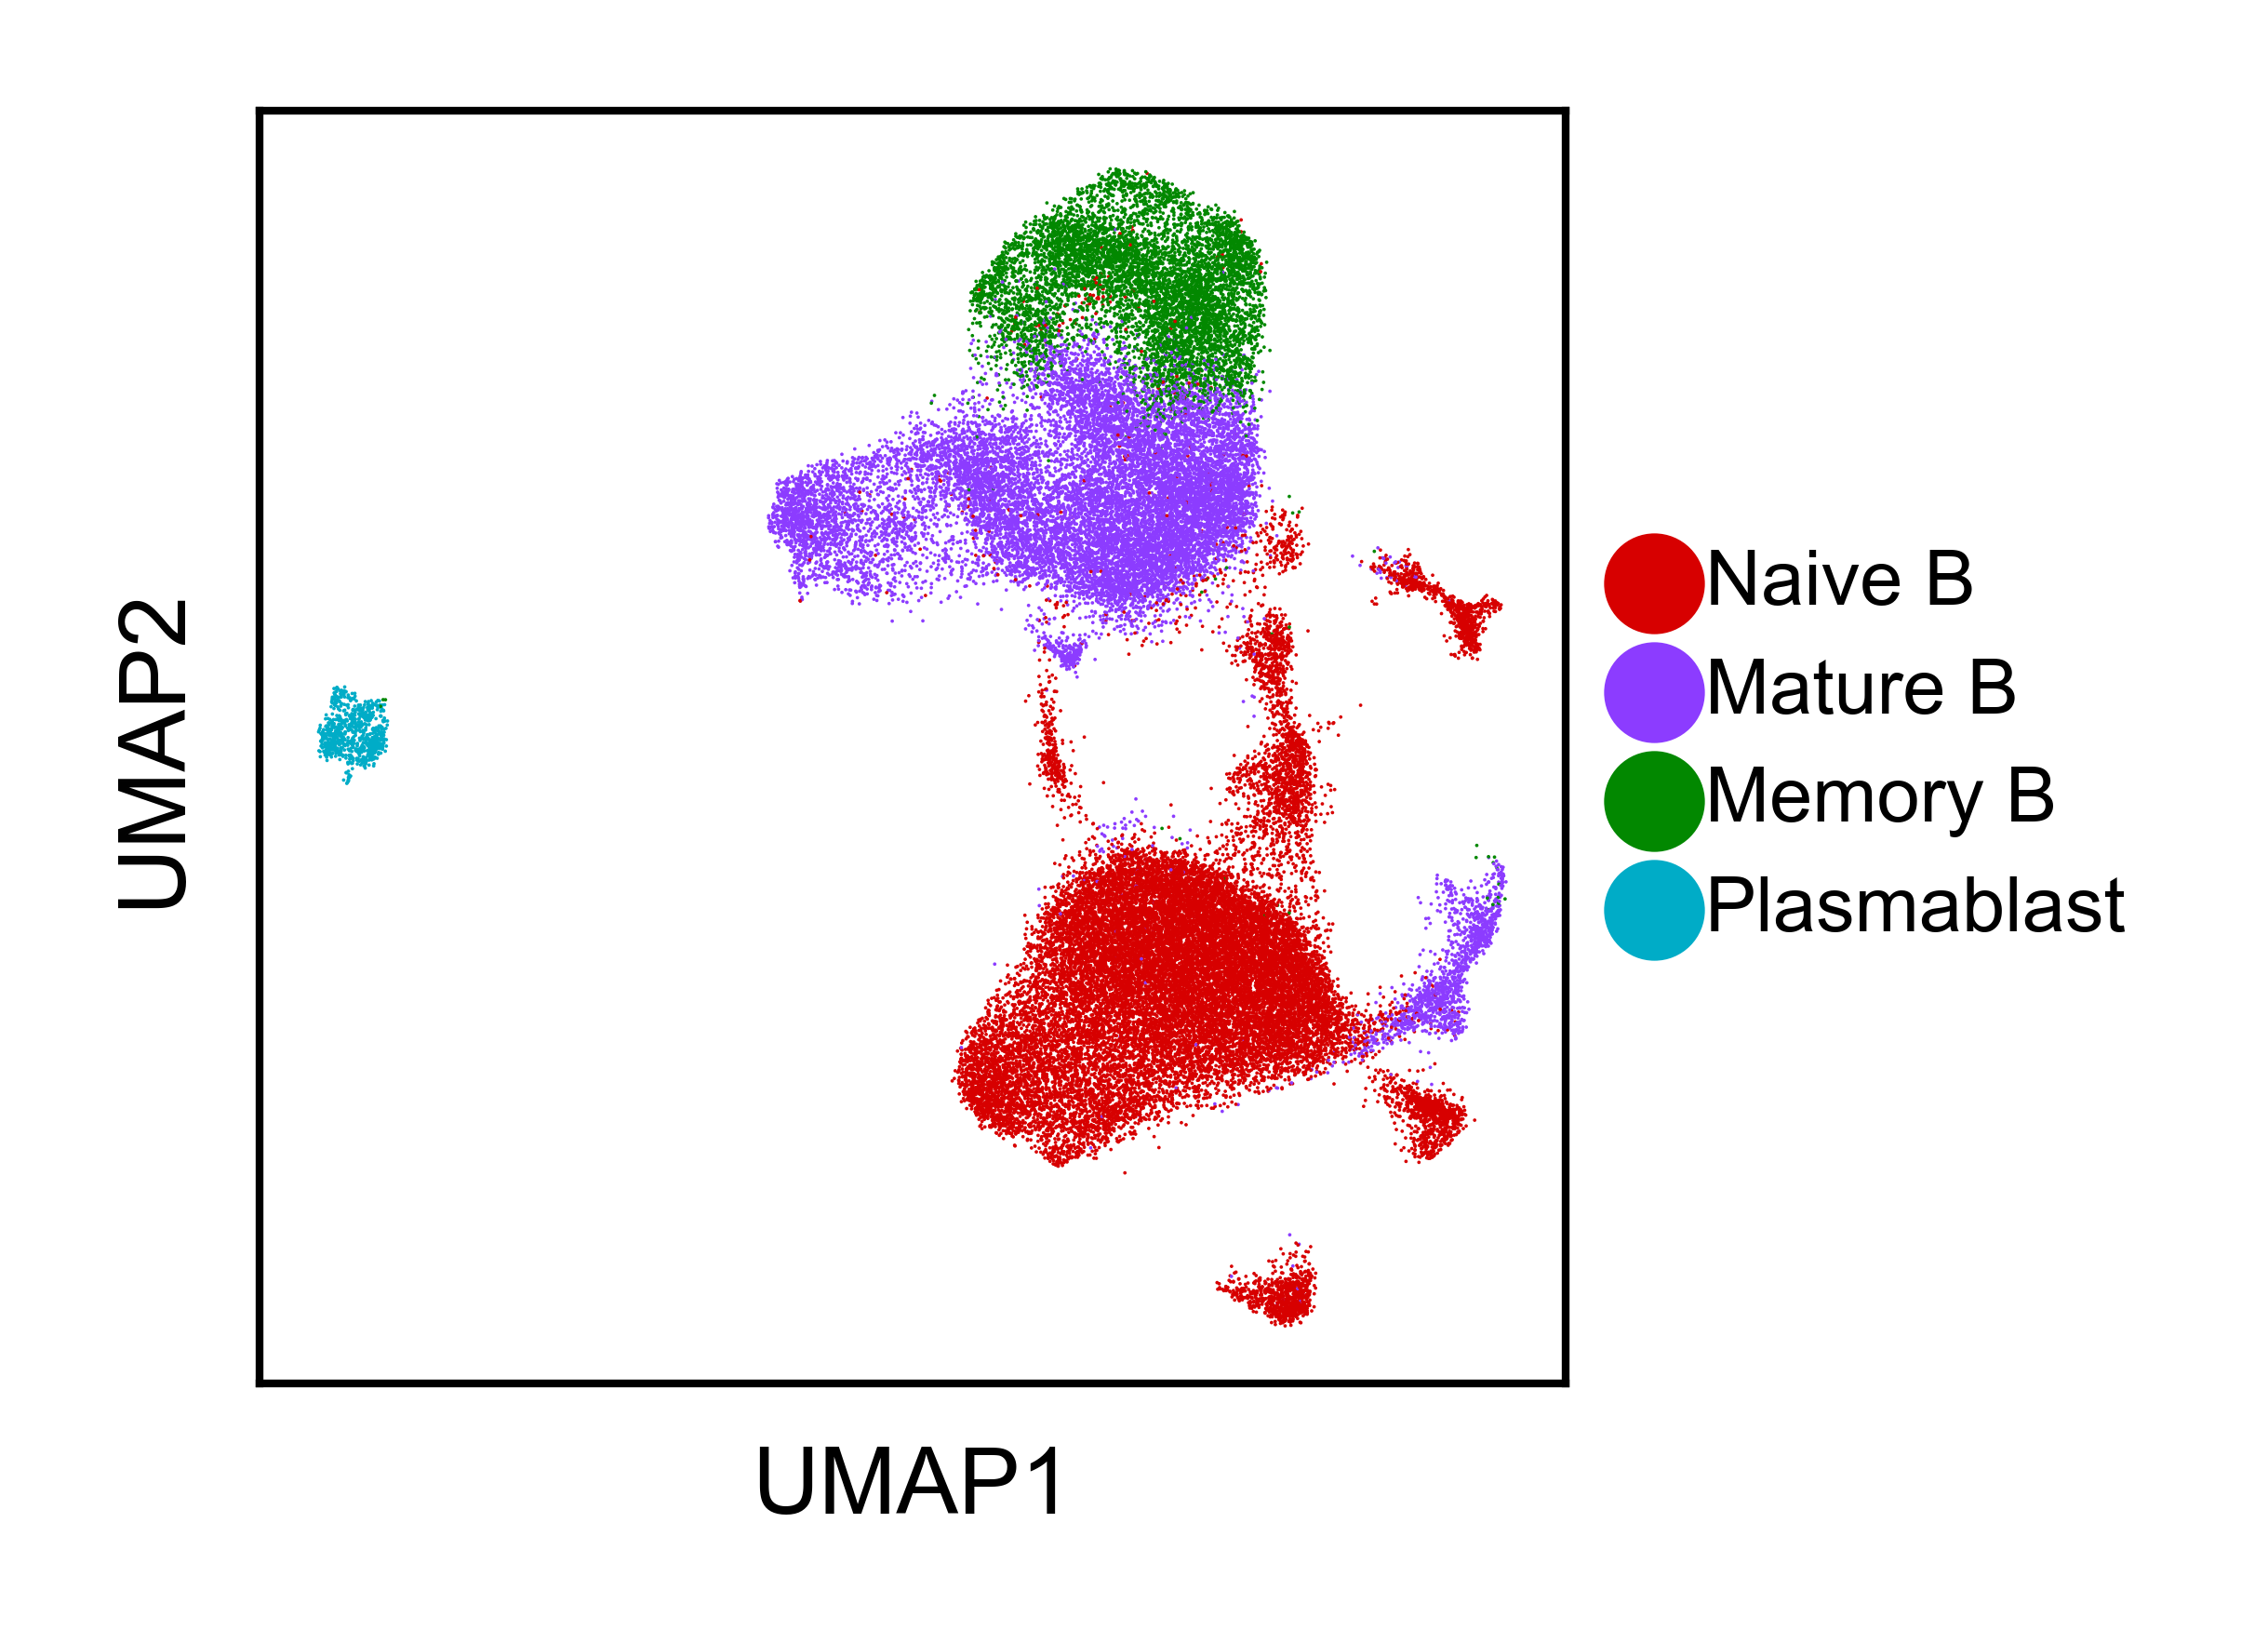

In [17]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'celltype_level3'
# cell_colors = {x: palsamplem['race-stage'] = samplem.apply(lambda row: f"{row['race']}-{row['group']}", axis=1)
# Counter(samplem['race-stage'])
#palette[ct] = (0.8, 0.8, 0.8)

order = cells_group[celltype_major]
pal_ordered = [palette_all[c] for c in order]

# newlabel_dict = {
# 'Naive CD4T': 'Naive CD4', 
# 'Central Memory CD4T': 'CD4 TCM', 
# 'Effector Memory CD4T': 'CD4 TEM', 
# 'Cytotoxic CD4T': 'CD4 CTL',
# 'Treg':'Treg'
# }

d.obs['celltype_level3_new'] = d.obs['celltype_level3'] #[
#     newlabel_dict[x] for x in d.obs['celltype_level3']
# ]

d.obs['celltype_level3_new'] = pd.Categorical(
    d.obs['celltype_level3_new'],
    categories=order,
    ordered=True
)

sc.pl.umap(
    d,
    color='celltype_level3_new',
    palette=pal_ordered,
    size=.2,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig(f'plots/F7_2/{celltype_major}_celltype.svg')

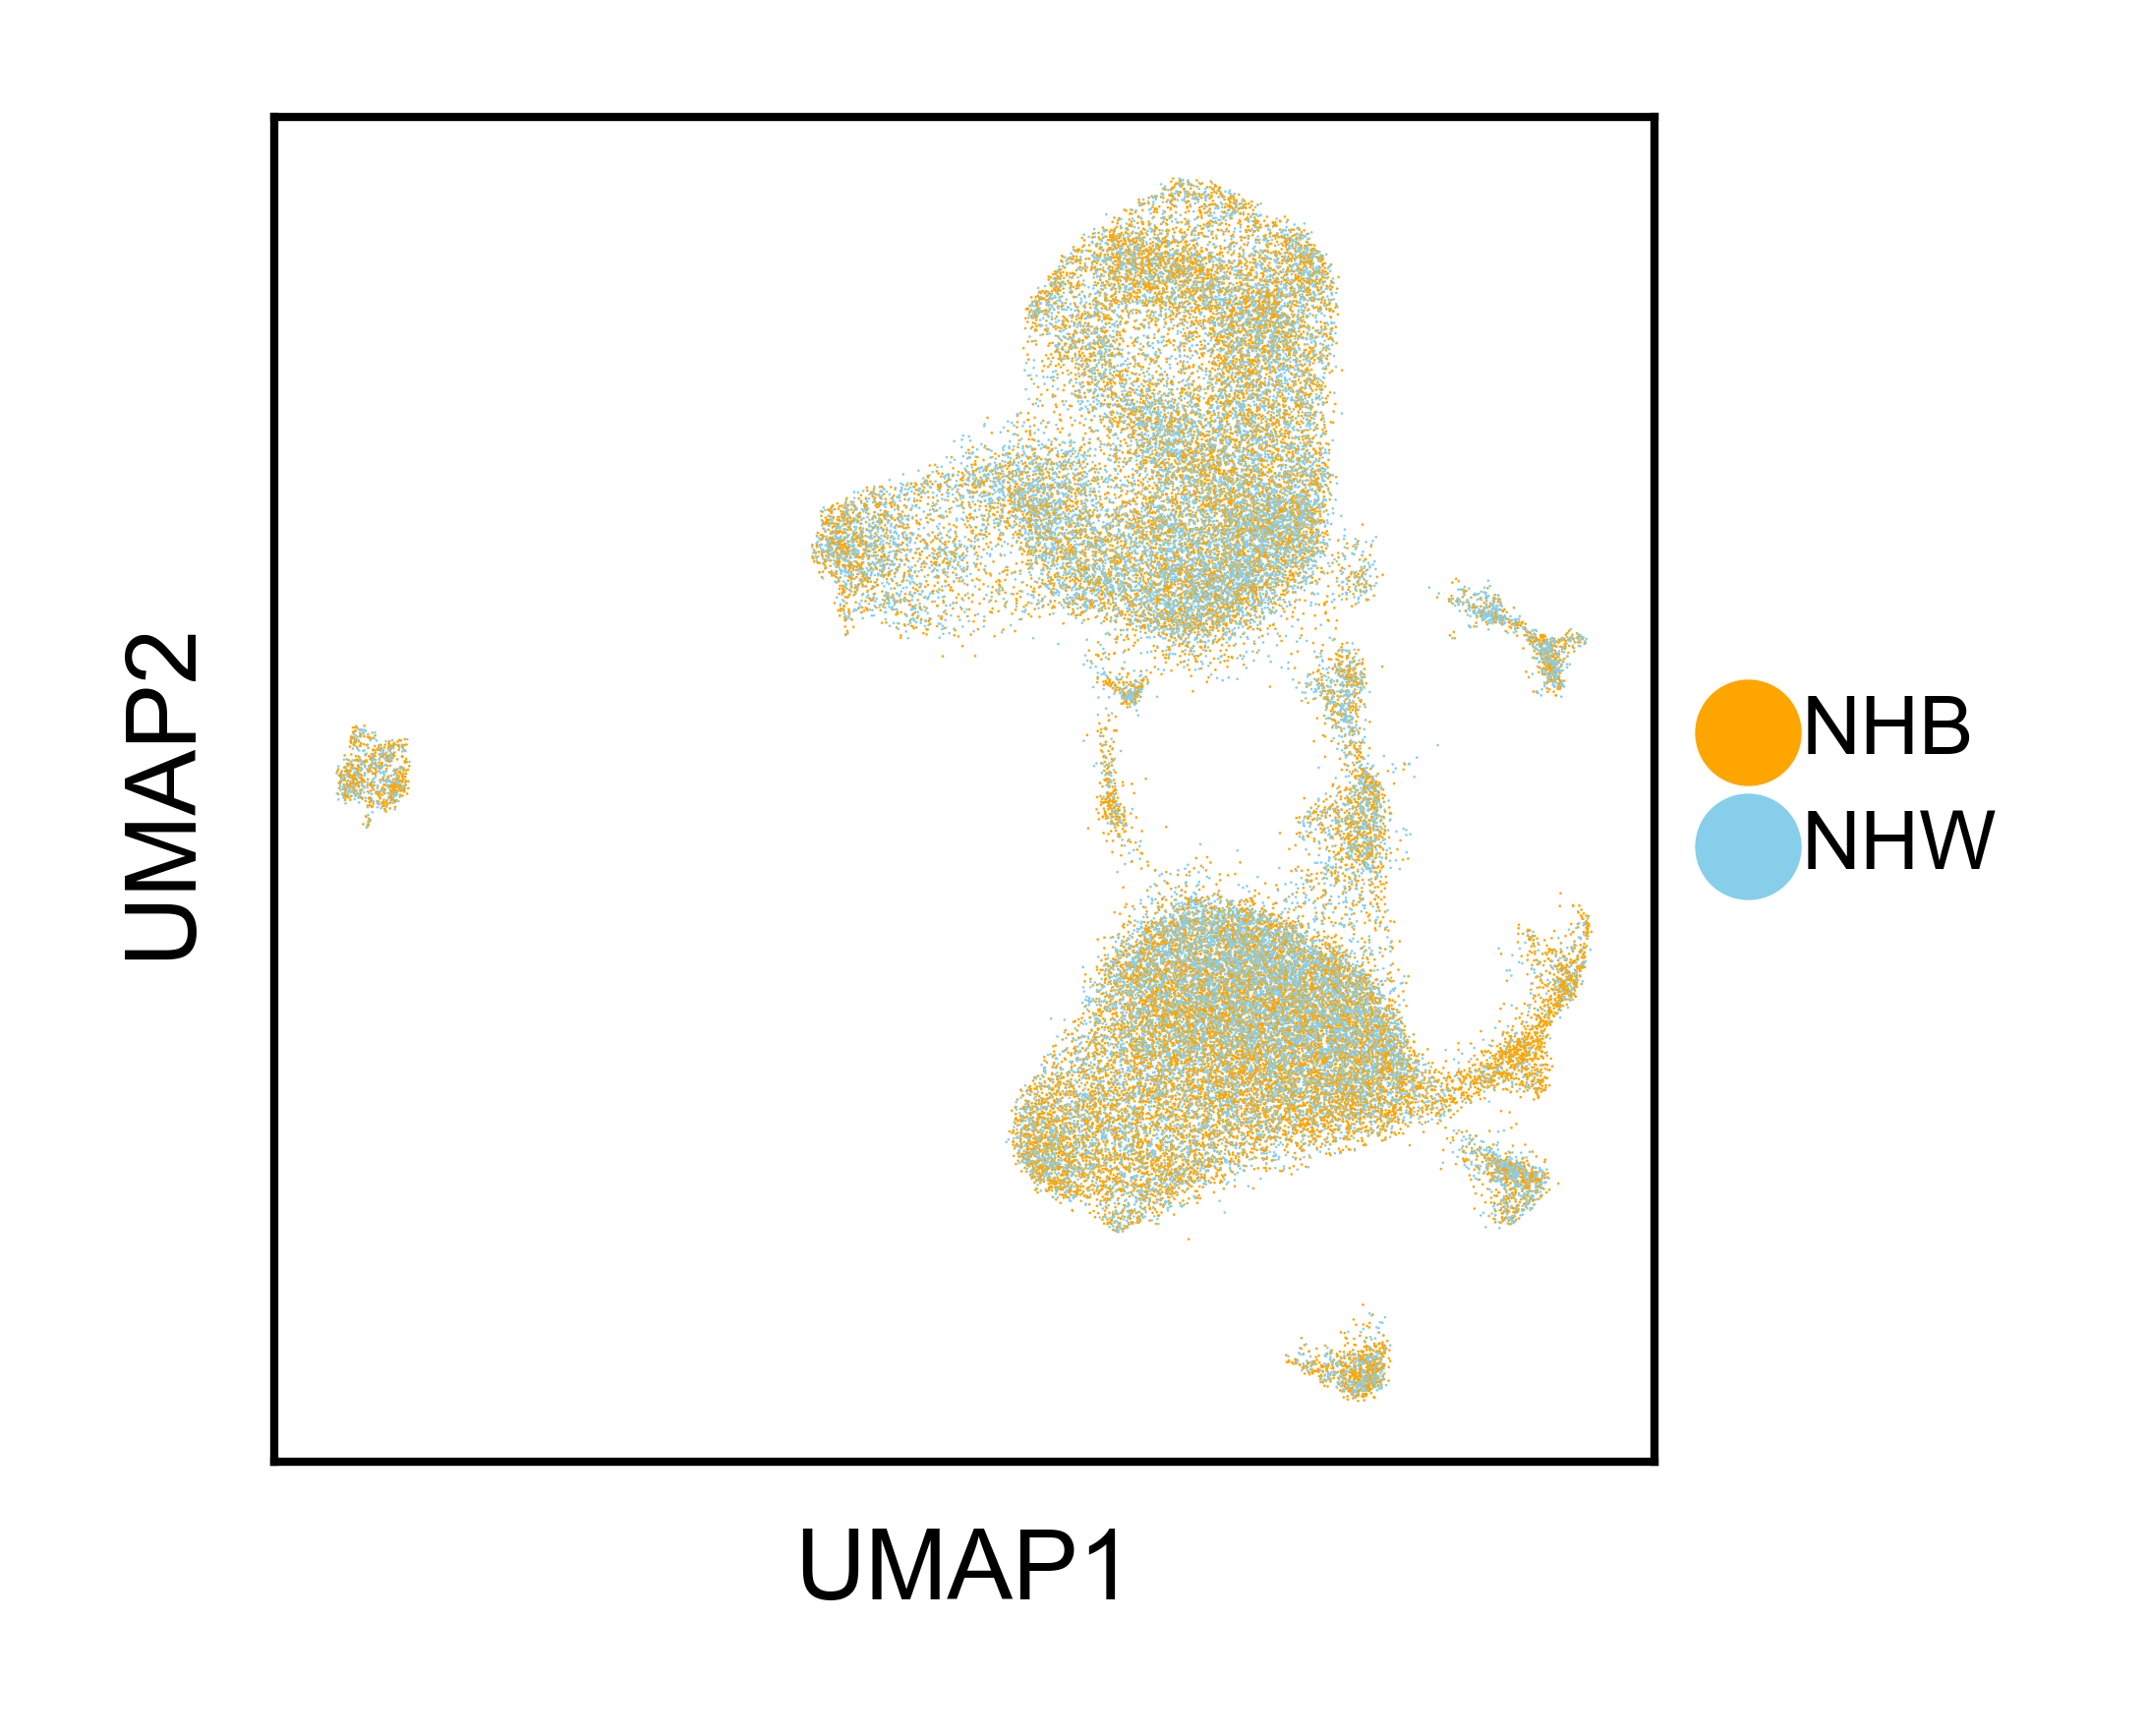

In [16]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'race'
d.obs['race'] = [str(x).replace('1','NHB').replace('0','NHW') for x in d.obs['race']]


order = cells_group[celltype_major]
pal_ordered = [palette_all[c] for c in order]

sc.pl.umap(
    d,
    color=covar,
    palette=['orange','skyblue'],
    size=.1,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig(f'plots/F7_2/{celltype_major}_race.svg')

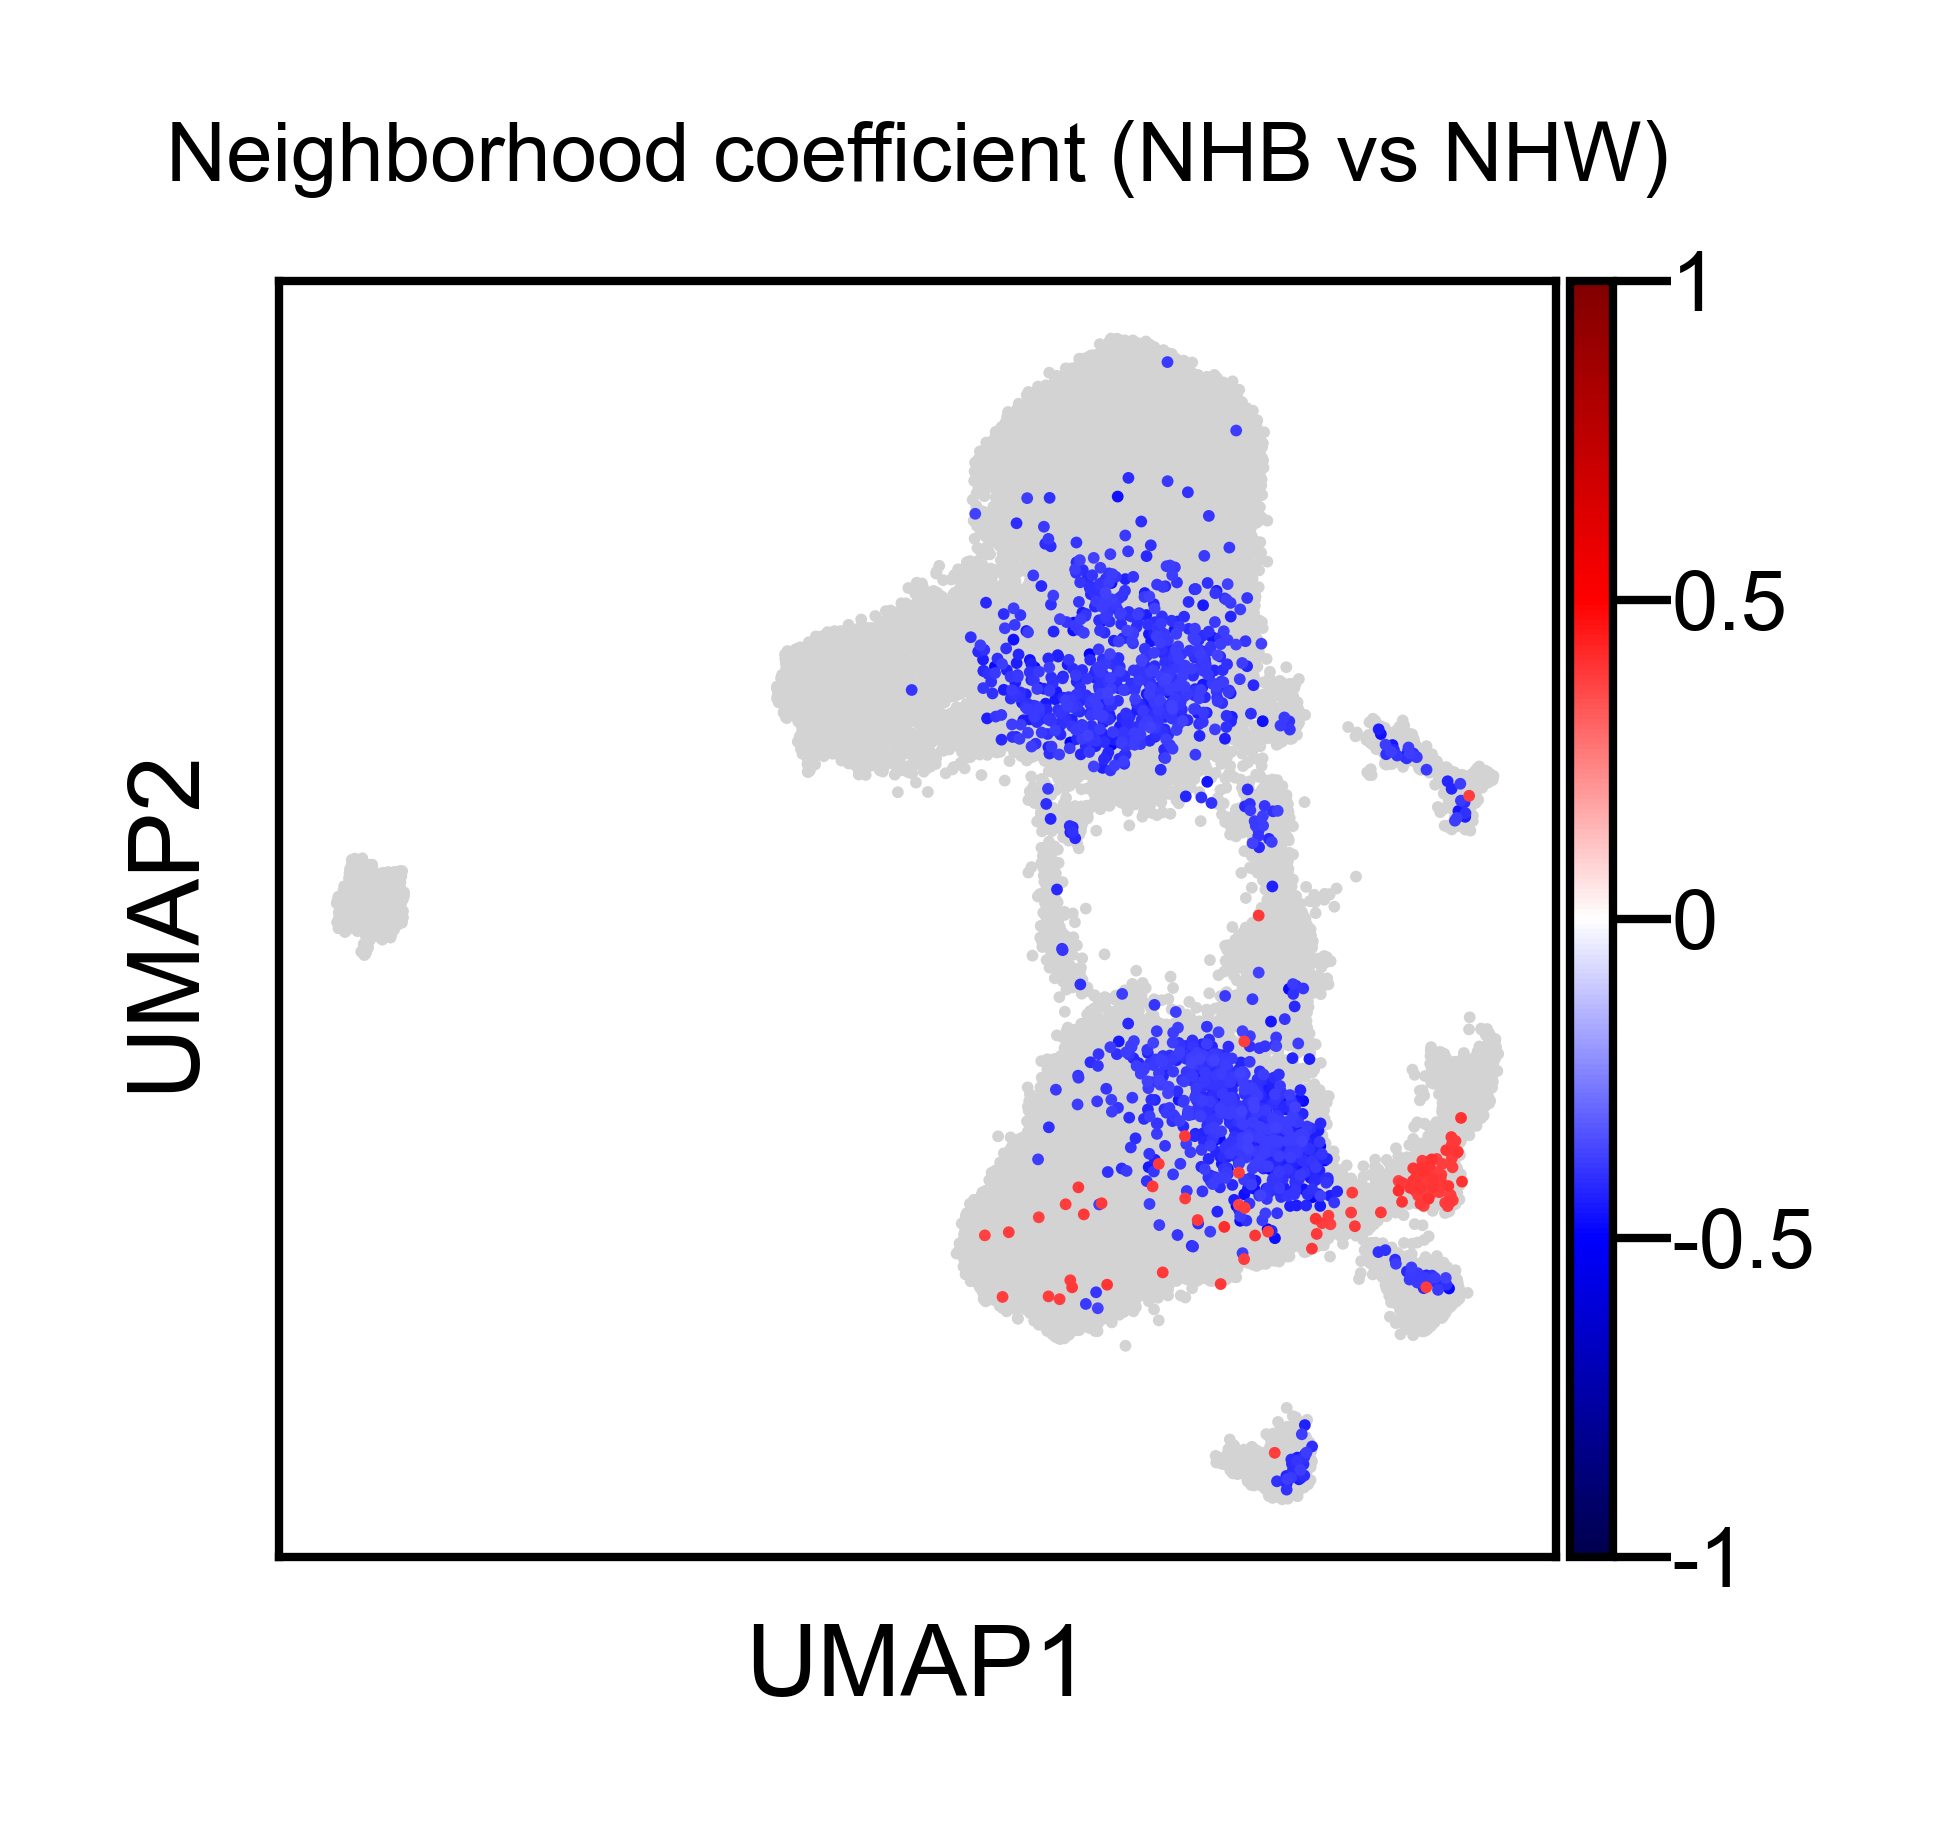

In [19]:
fig, ax = plt.subplots(figsize=(1.5, 1.4))

covar = 'race' 

coef_col = f"{covar}_coef"
fdr_col = f"{covar}_coef_fdr"
color_col = f"{covar}_coef_plot"

d.obs[color_col] = np.where(d.obs[fdr_col] < 0.1, d.obs[coef_col], np.nan)   # nan will show as gray in sc.pl.umap
sc.pl.umap(
    d,
    color=color_col,
    s=2,
    ax=ax,
    vmin=-1,
    vmax=1,
    cmap='seismic',
    na_color='lightgray',   # Gray for nan (non-significant)
    title='',
    show=False         # So you can further edit if needed
)

cbar = ax.collections[0].colorbar
ticks = [-1, -0.5, 0, 0.5, 1]
cbar.set_ticks(ticks)
cbar.set_ticklabels([str(t) for t in ticks])


ax.set_title('Neighborhood coefficient (NHB vs NHW)',fontsize=5)
plt.savefig(f'plots/F7_2/{celltype_major}_NbCoeff.svg')

In [20]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]>0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

Naive B: 39 (37.86%)
Mature B: 64 (62.14%)


In [21]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]<0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

Naive B: 844 (55.93%)
Mature B: 647 (42.88%)
Memory B: 18 (1.19%)


## Celltype + DzState

In [ ]:
cts = 0

for celltype in [
'Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'
]:
    for group in ['HRL','DCIS','BC']:

        for db in ['hallmark','immport']:

            cts += 1
            
            raw = pd.read_csv(
                f'data/Figure7_2/CNArankNHBvsW_{celltype}_{group}_{db}.csv', 
                index_col=0)
            
            dfp = raw#[raw['FDR q-val']<0.1].sort_values('NES', ascending=False)
            # dfp = raw[raw['NOM p-val']<0.05].sort_values('NES', ascending=False)

            dfp['Tag %'] = (
                dfp['Tag %']
                .astype(str)
                .apply(lambda x: eval(x) if '/' in x else float(x))
            )
            dfp['Tag %'] = dfp['Tag %'] * 100
            dfp['log_p'] = -np.log10(dfp['FDR q-val'].replace(0, 1e-300))
            
            # Sort by NES
            dfp = dfp.sort_values('NES', ascending=False)
            
            # filter - 
            # dfp = dfp[dfp['Tag %']>=30]
            dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]

            dfp['analysis_celltype'] = [celltype]*dfp.shape[0]
            dfp['analysis_group'] = [group]*dfp.shape[0]
            dfp['analysis_db'] = [db]*dfp.shape[0]

            out = dfp if cts==1 else pd.concat([out, dfp])

out        

In [ ]:
tmp = out[(out['analysis_db']=='immport') & (out['FDR q-val']<0.1)]

cnt = Counter(tmp[
    'Term'])
cnt

In [38]:
# [k for k, v in Counter(tmp['Term']).most_common()]
list_sel = [
 'ANTIMICROBIAL HUMORAL RESPONSE',
 'INNATE IMMUNE RESPONSE IN MUCOSA',
 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
 'ROS AND RNS PRODUCTION IN PHAGOCYTES',
 # 'NEUTROPHIL DEGRANULATION',
 'TNFR2 NON-CANONICAL NF-KB PATHWAY',
 'B CELL DIFFERENTIATION',
 'B CELL ACTIVATION',
 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
 # 'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
 'TOLERANCE INDUCTION',
 'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
 'INTERFERON ALPHA/BETA SIGNALING',
 # 'T CELL MEDIATED CYTOTOXICITY',
 'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
 'INTERLEUKIN-2 FAMILY SIGNALING',
 'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
 'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
 'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
 # 'ANTIFUNGAL INNATE IMMUNE RESPONSE',
 'RAP1 SIGNALLING',
 'ALPHA-BETA T CELL ACTIVATION',
 # 'T CELL DIFFERENTIATION',
 # 'MYELOID LEUKOCYTE ACTIVATION',
 'ACTIVATION OF INNATE IMMUNE RESPONSE',
 # 'GAMMA-DELTA T CELL ACTIVATION',
 'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
 'INTERLEUKIN-20 FAMILY SIGNALING',
 # 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
 # 'ALPHA-PROTEIN KINASE 1 SIGNALING PATHWAY',
 # 'TCR SIGNALING',
 'ANTIGEN PROCESSING AND PRESENTATION',
 # 'C-TYPE LECTIN RECEPTORS (CLRS)',
 'LYMPHOCYTE PROLIFERATION',
 # 'GROWTH HORMONE RECEPTOR SIGNALING',
 # 'LEUKOCYTE DEGRANULATION',
 # 'T CELL PROLIFERATION',
 # 'NEGATIVE REGULATION OF ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
 # 'CLASS I MHC MEDIATED ANTIGEN PROCESSING & PRESENTATION',
 # 'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
 # 'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
 # 'NATURAL KILLER CELL ACTIVATION',
 # 'LEUKOCYTE HOMEOSTASIS',
 # 'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
 # 'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
 # 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
 # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
 # 'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS',
 # 'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY',
 # 'NATURAL KILLER CELL MEDIATED IMMUNITY',
 # 'LEUKOCYTE CHEMOTAXIS',
 # 'INTERLEUKIN-12 FAMILY SIGNALING',
 # 'LEUKOCYTE MEDIATED CYTOTOXICITY',
 # 'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
 # 'NEGATIVE REGULATION OF HEMOPOIESIS',
 # 'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
 # 'MHC CLASS II ANTIGEN PRESENTATION',
 # 'INTERLEUKIN-1 FAMILY SIGNALING',
 # 'COSTIMULATION BY THE CD28 FAMILY',
 # 'T CELL COSTIMULATION',
 # 'COMPLEMENT CASCADE',
 # 'LYMPHOCYTE COSTIMULATION',
 # 'RESPIRATORY BURST INVOLVED IN DEFENSE RESPONSE',
 # 'INTERLEUKIN-7 SIGNALING',
 # 'DAP12 INTERACTIONS',
 # 'GERMINAL CENTER FORMATION',
 # 'FLT3 SIGNALING',
 # 'FC EPSILON RECEPTOR (FCERI) SIGNALING',
 # 'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
 # 'MONONUCLEAR CELL MIGRATION',
 # 'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',
 # 'ADVANCED GLYCOSYLATION ENDPRODUCT RECEPTOR SIGNALING',
 # 'OPSONIZATION',
 # 'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
 # 'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY',
 # 'ANTIMICROBIAL PEPTIDES',
 # 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',
 # 'MYELOID LEUKOCYTE MIGRATION',
 # 'TOLL-LIKE RECEPTOR CASCADES',
 # 'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
 # 'DIAPEDESIS',
 # 'CYTOSOLIC SENSORS OF PATHOGEN-ASSOCIATED DNA ',
 # 'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS',
 # 'ANTIVIRAL MECHANISM BY IFN-STIMULATED GENES',
 # 'MYELOID CELL HOMEOSTASIS',
 # 'NATURAL KILLER CELL DIFFERENTIATION',
 # 'NEGATIVE REGULATION OF IMMUNE RESPONSE',
 # 'INTERFERON GAMMA SIGNALING',
 # 'NEGATIVE REGULATION OF CYTOPLASMIC PATTERN RECOGNITION RECEPTOR SIGNALING PATHWAY',
 # 'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
 # 'TYPE 2 IMMUNE RESPONSE'
]

list_sel

['ANTIMICROBIAL HUMORAL RESPONSE',
 'INNATE IMMUNE RESPONSE IN MUCOSA',
 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
 'ROS AND RNS PRODUCTION IN PHAGOCYTES',
 'TNFR2 NON-CANONICAL NF-KB PATHWAY',
 'B CELL DIFFERENTIATION',
 'B CELL ACTIVATION',
 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
 'TOLERANCE INDUCTION',
 'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
 'INTERFERON ALPHA/BETA SIGNALING',
 'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
 'INTERLEUKIN-2 FAMILY SIGNALING',
 'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
 'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
 'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
 'RAP1 SIGNALLING',
 'ALPHA-BETA T CELL ACTIVATION',
 'ACTIVATION OF INNATE IMMUNE RESPONSE',
 'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
 'INTERLEUKIN-20 FAMILY SIGNALING',
 'ANTIGEN PROCESSING AND PRESENTATION',
 'LYMPHOCYTE PROLIFERATION']

In [22]:
list_sel = [
 'B CELL DIFFERENTIATION',
 'B CELL ACTIVATION',
 'ANTIMICROBIAL HUMORAL RESPONSE',
    
 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
    
 'ROS AND RNS PRODUCTION IN PHAGOCYTES',
 'TNFR2 NON-CANONICAL NF-KB PATHWAY'
 # 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
 # 'TOLERANCE INDUCTION',
 # 'INTERFERON ALPHA/BETA SIGNALING',
 # 'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
 # 'INTERLEUKIN-2 FAMILY SIGNALING',
 # 'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
 # 'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
 # 'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
 # 'RAP1 SIGNALLING',
 # 'INTERLEUKIN-20 FAMILY SIGNALING',
 # 'ANTIGEN PROCESSING AND PRESENTATION',
 # 'LYMPHOCYTE PROLIFERATION'    
]

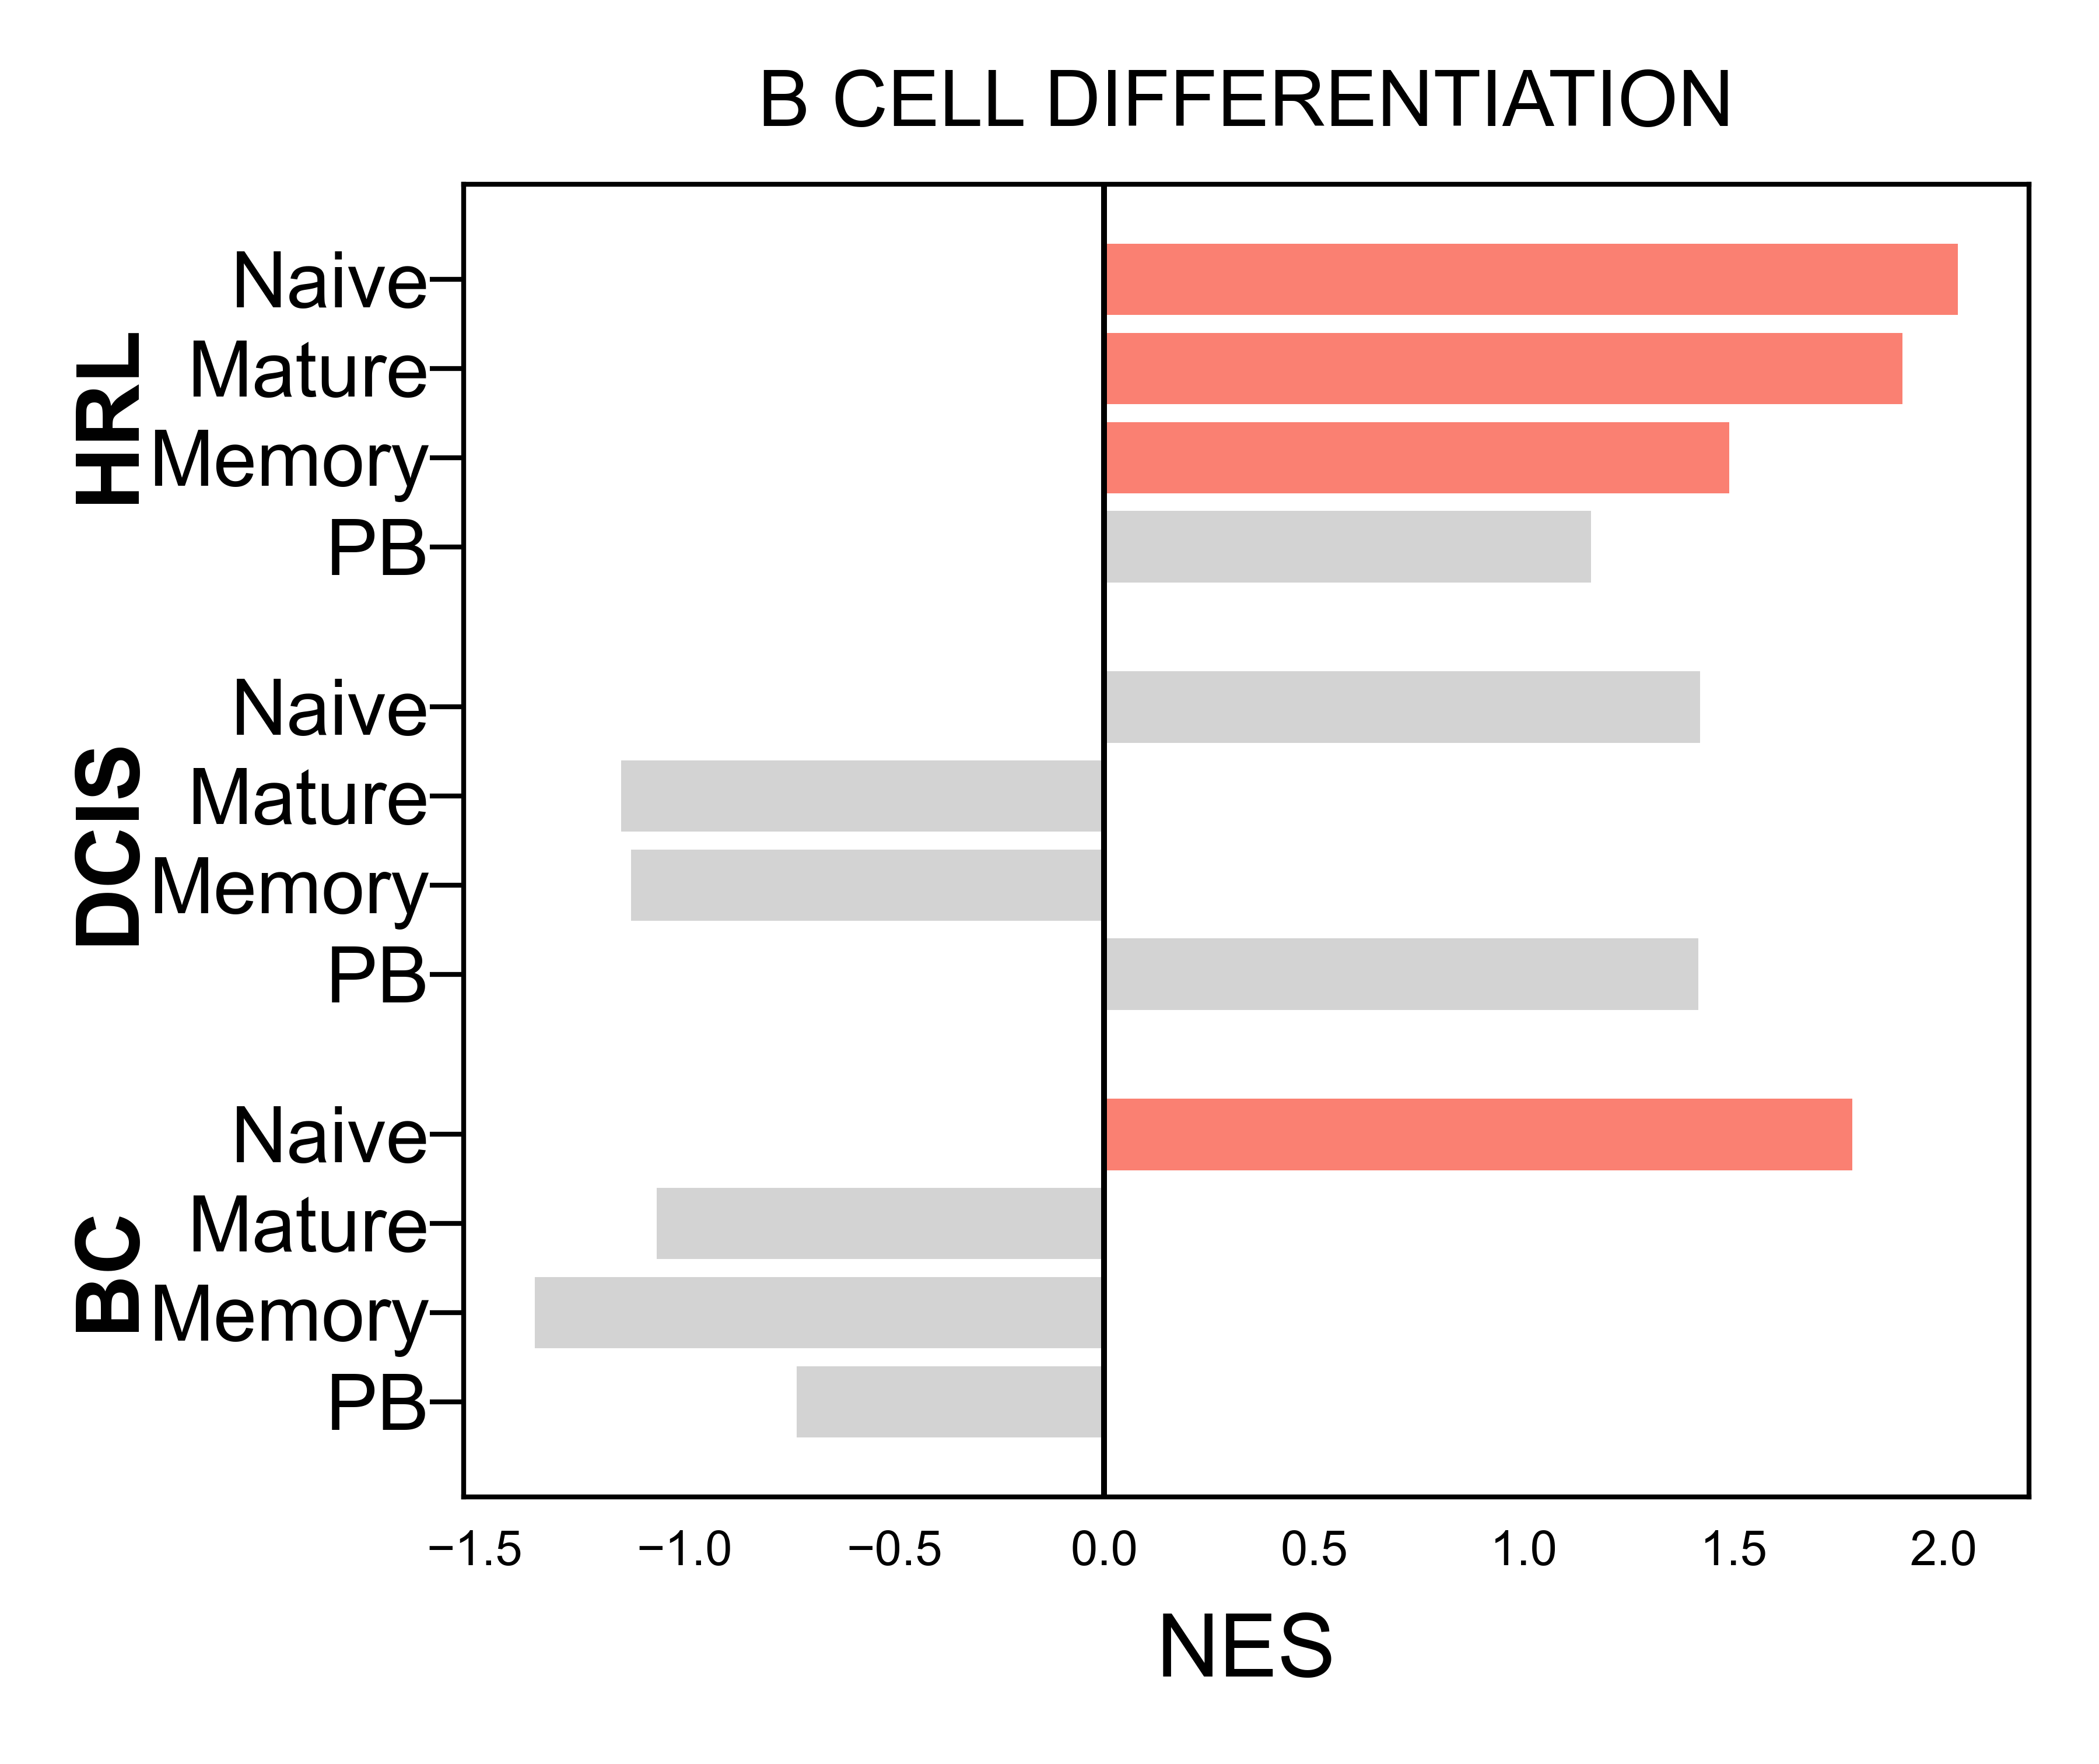

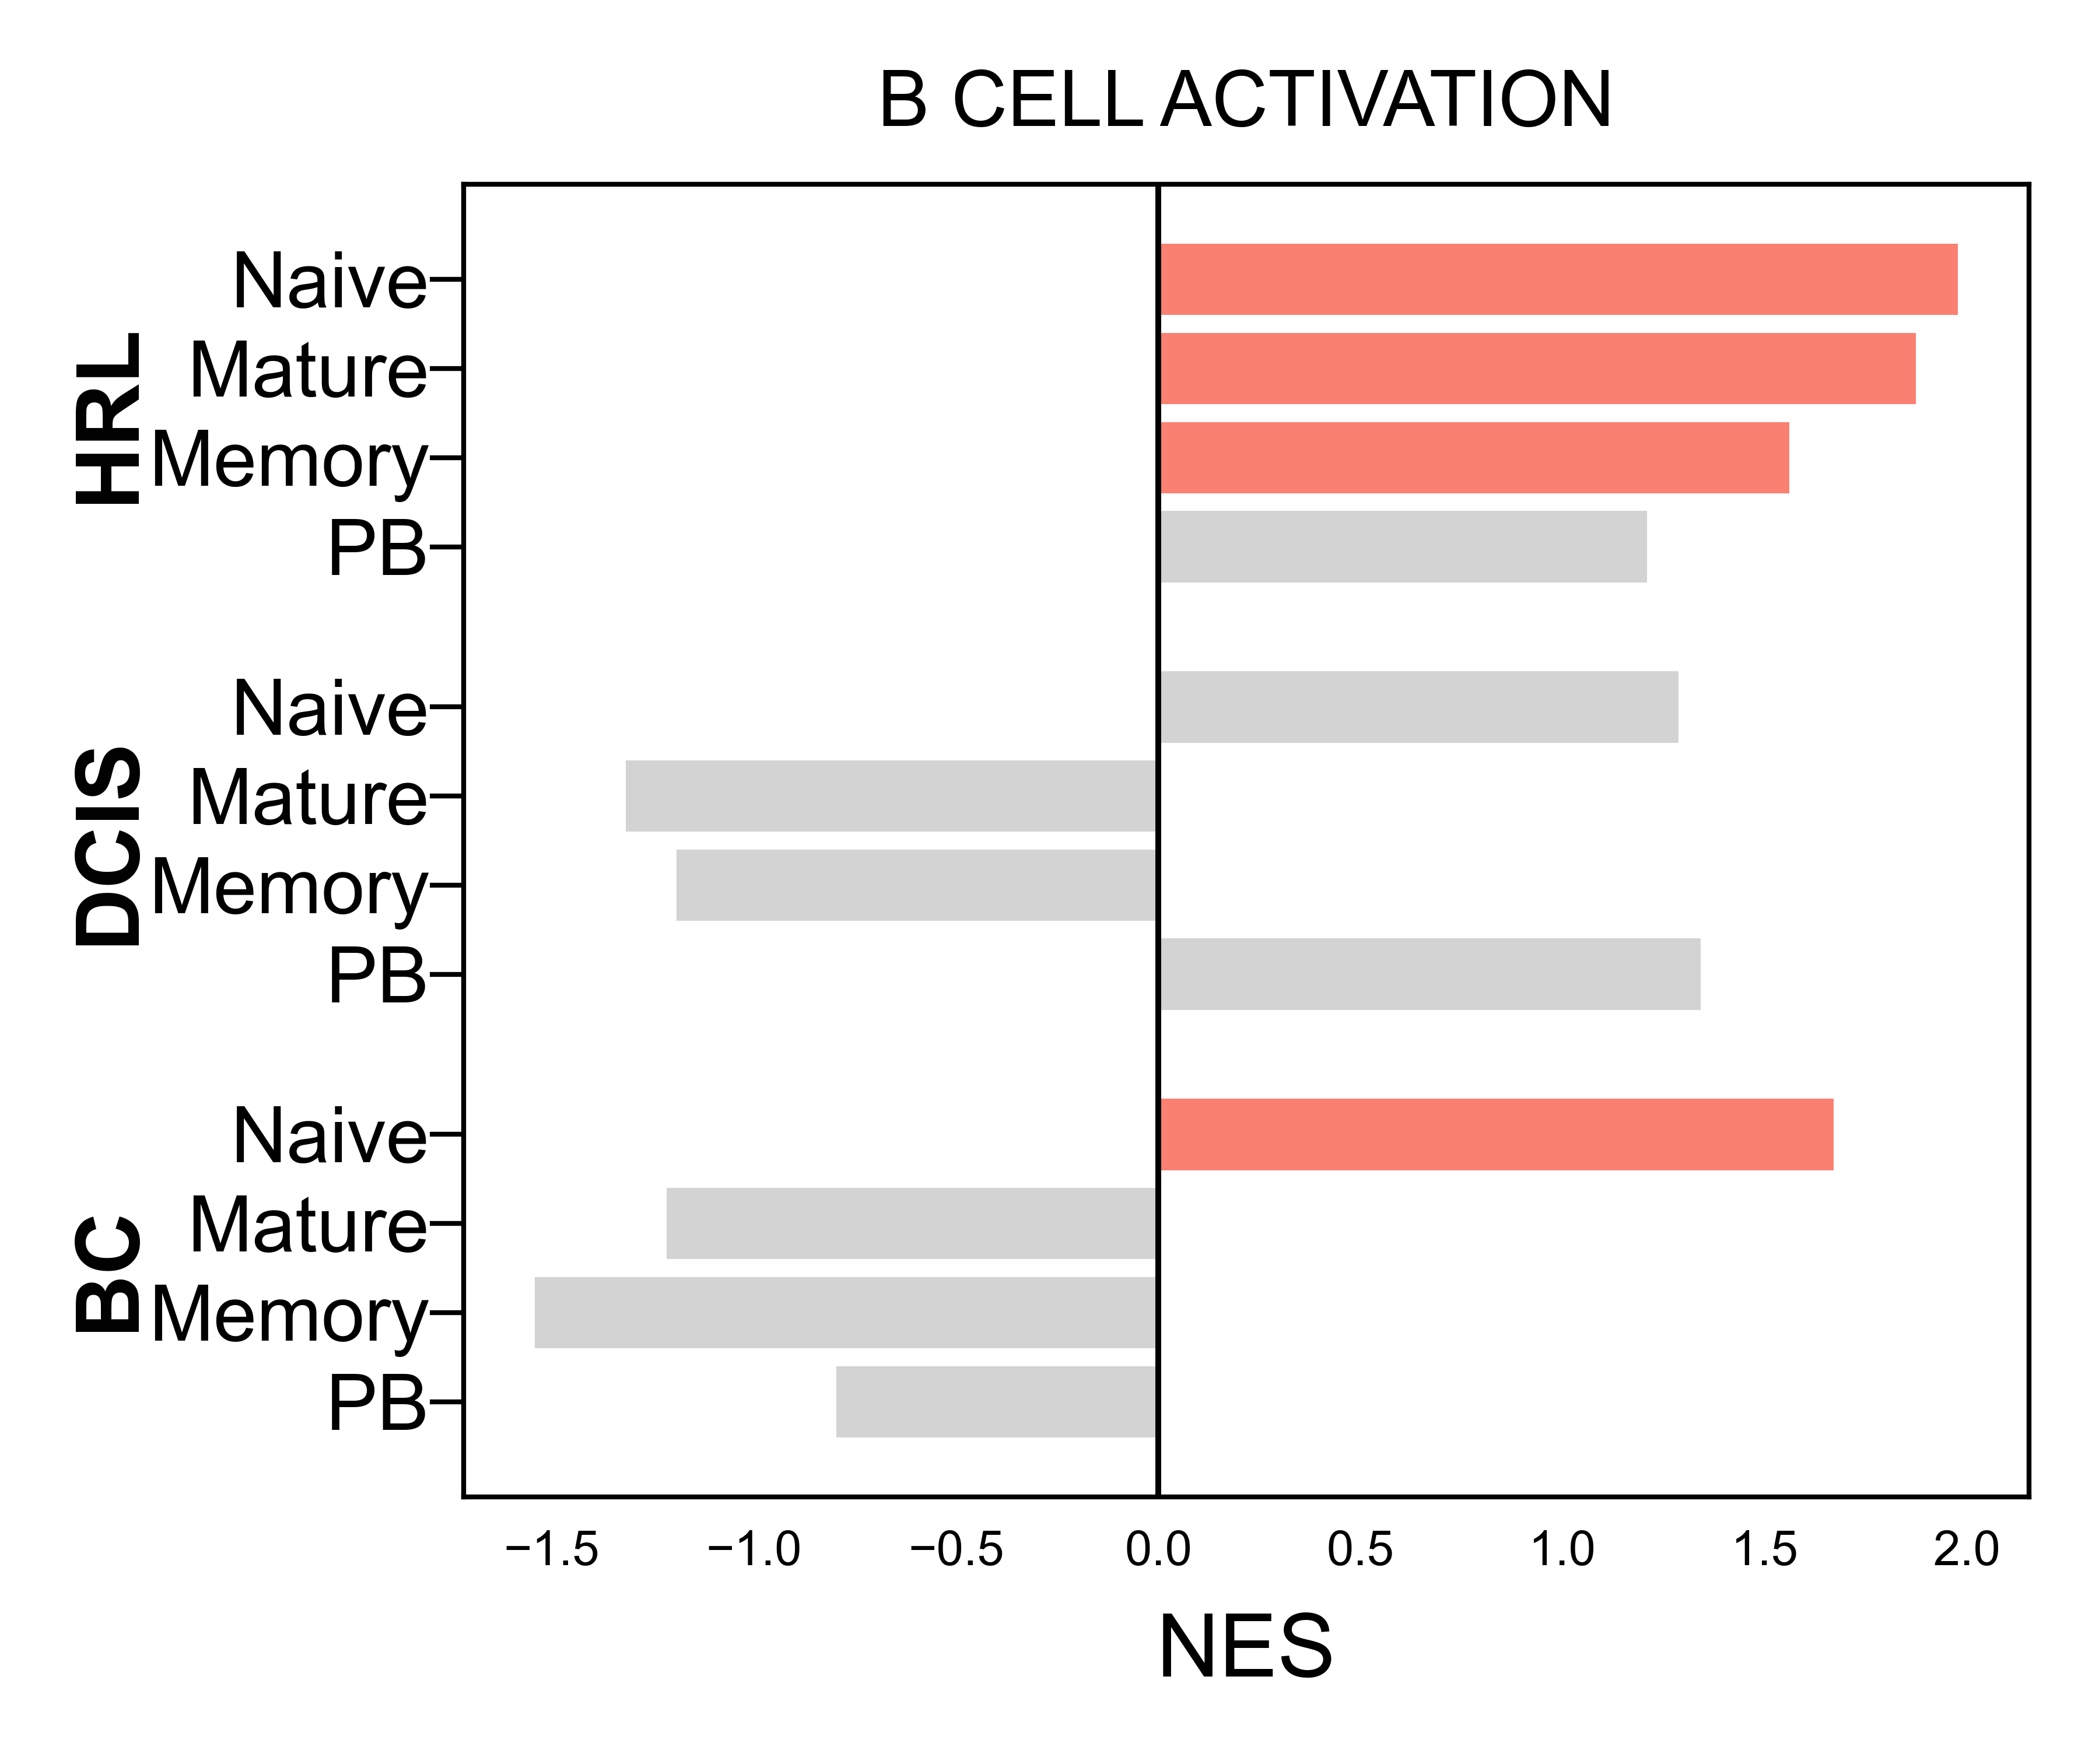

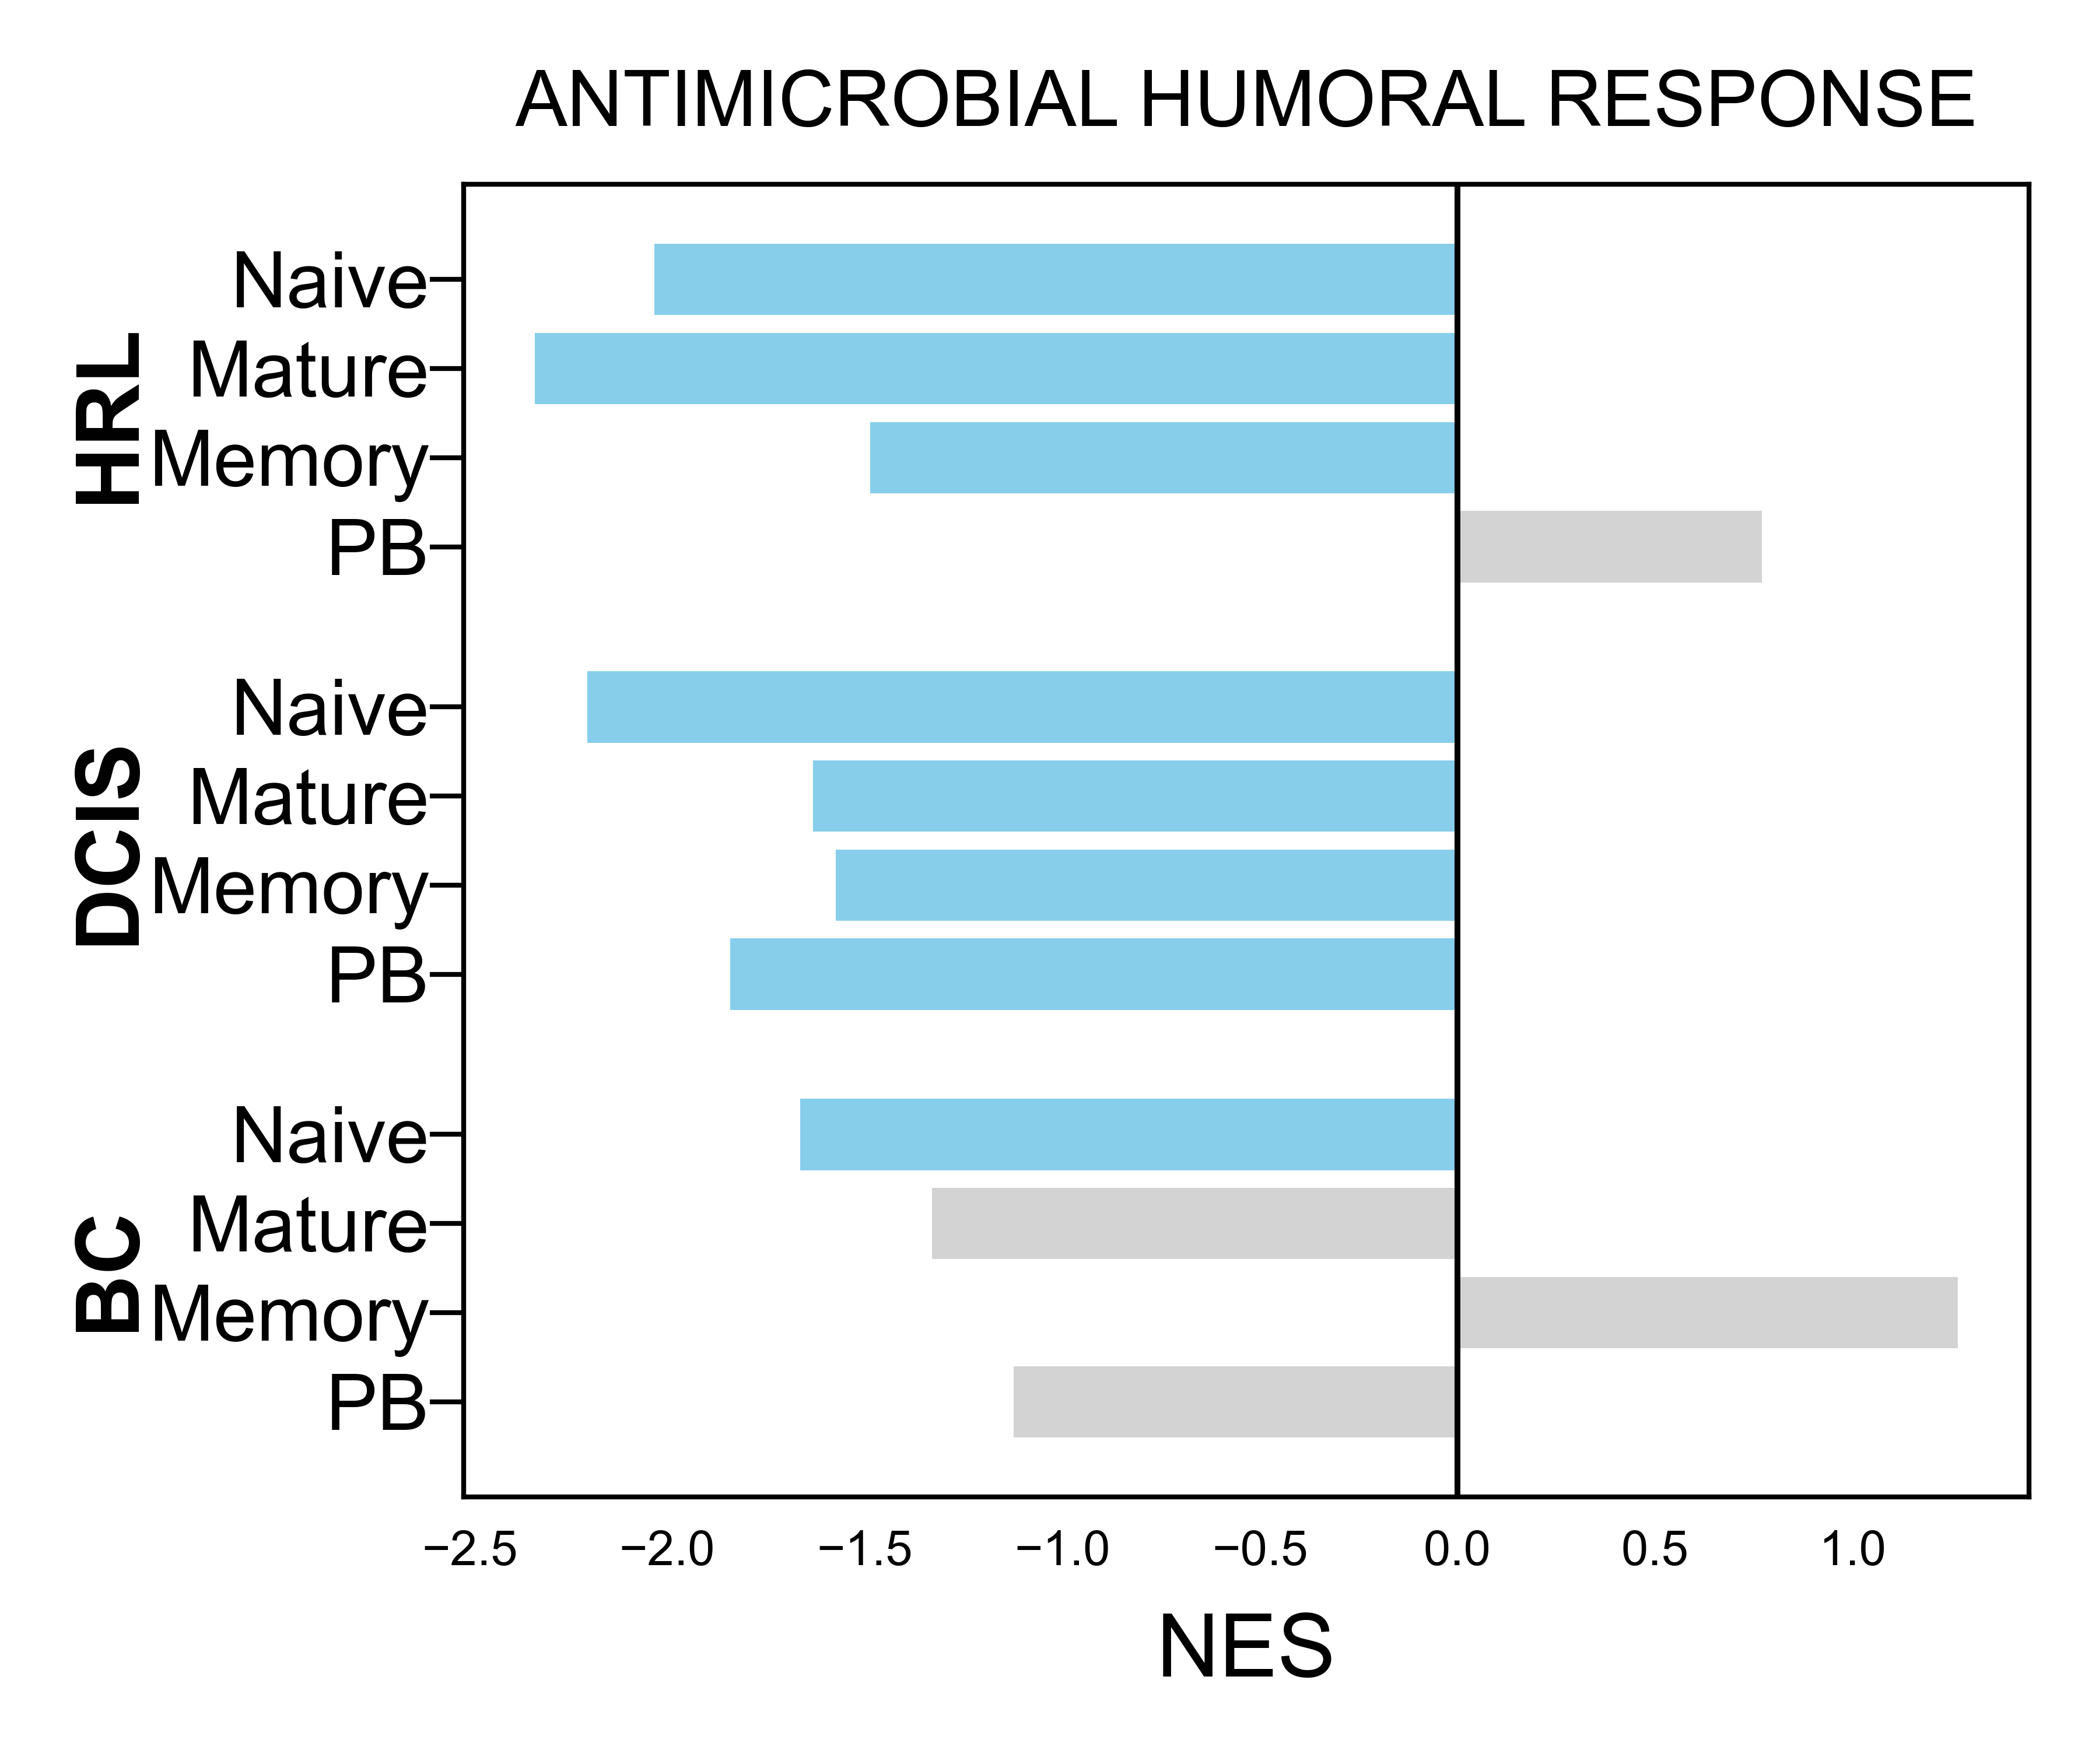

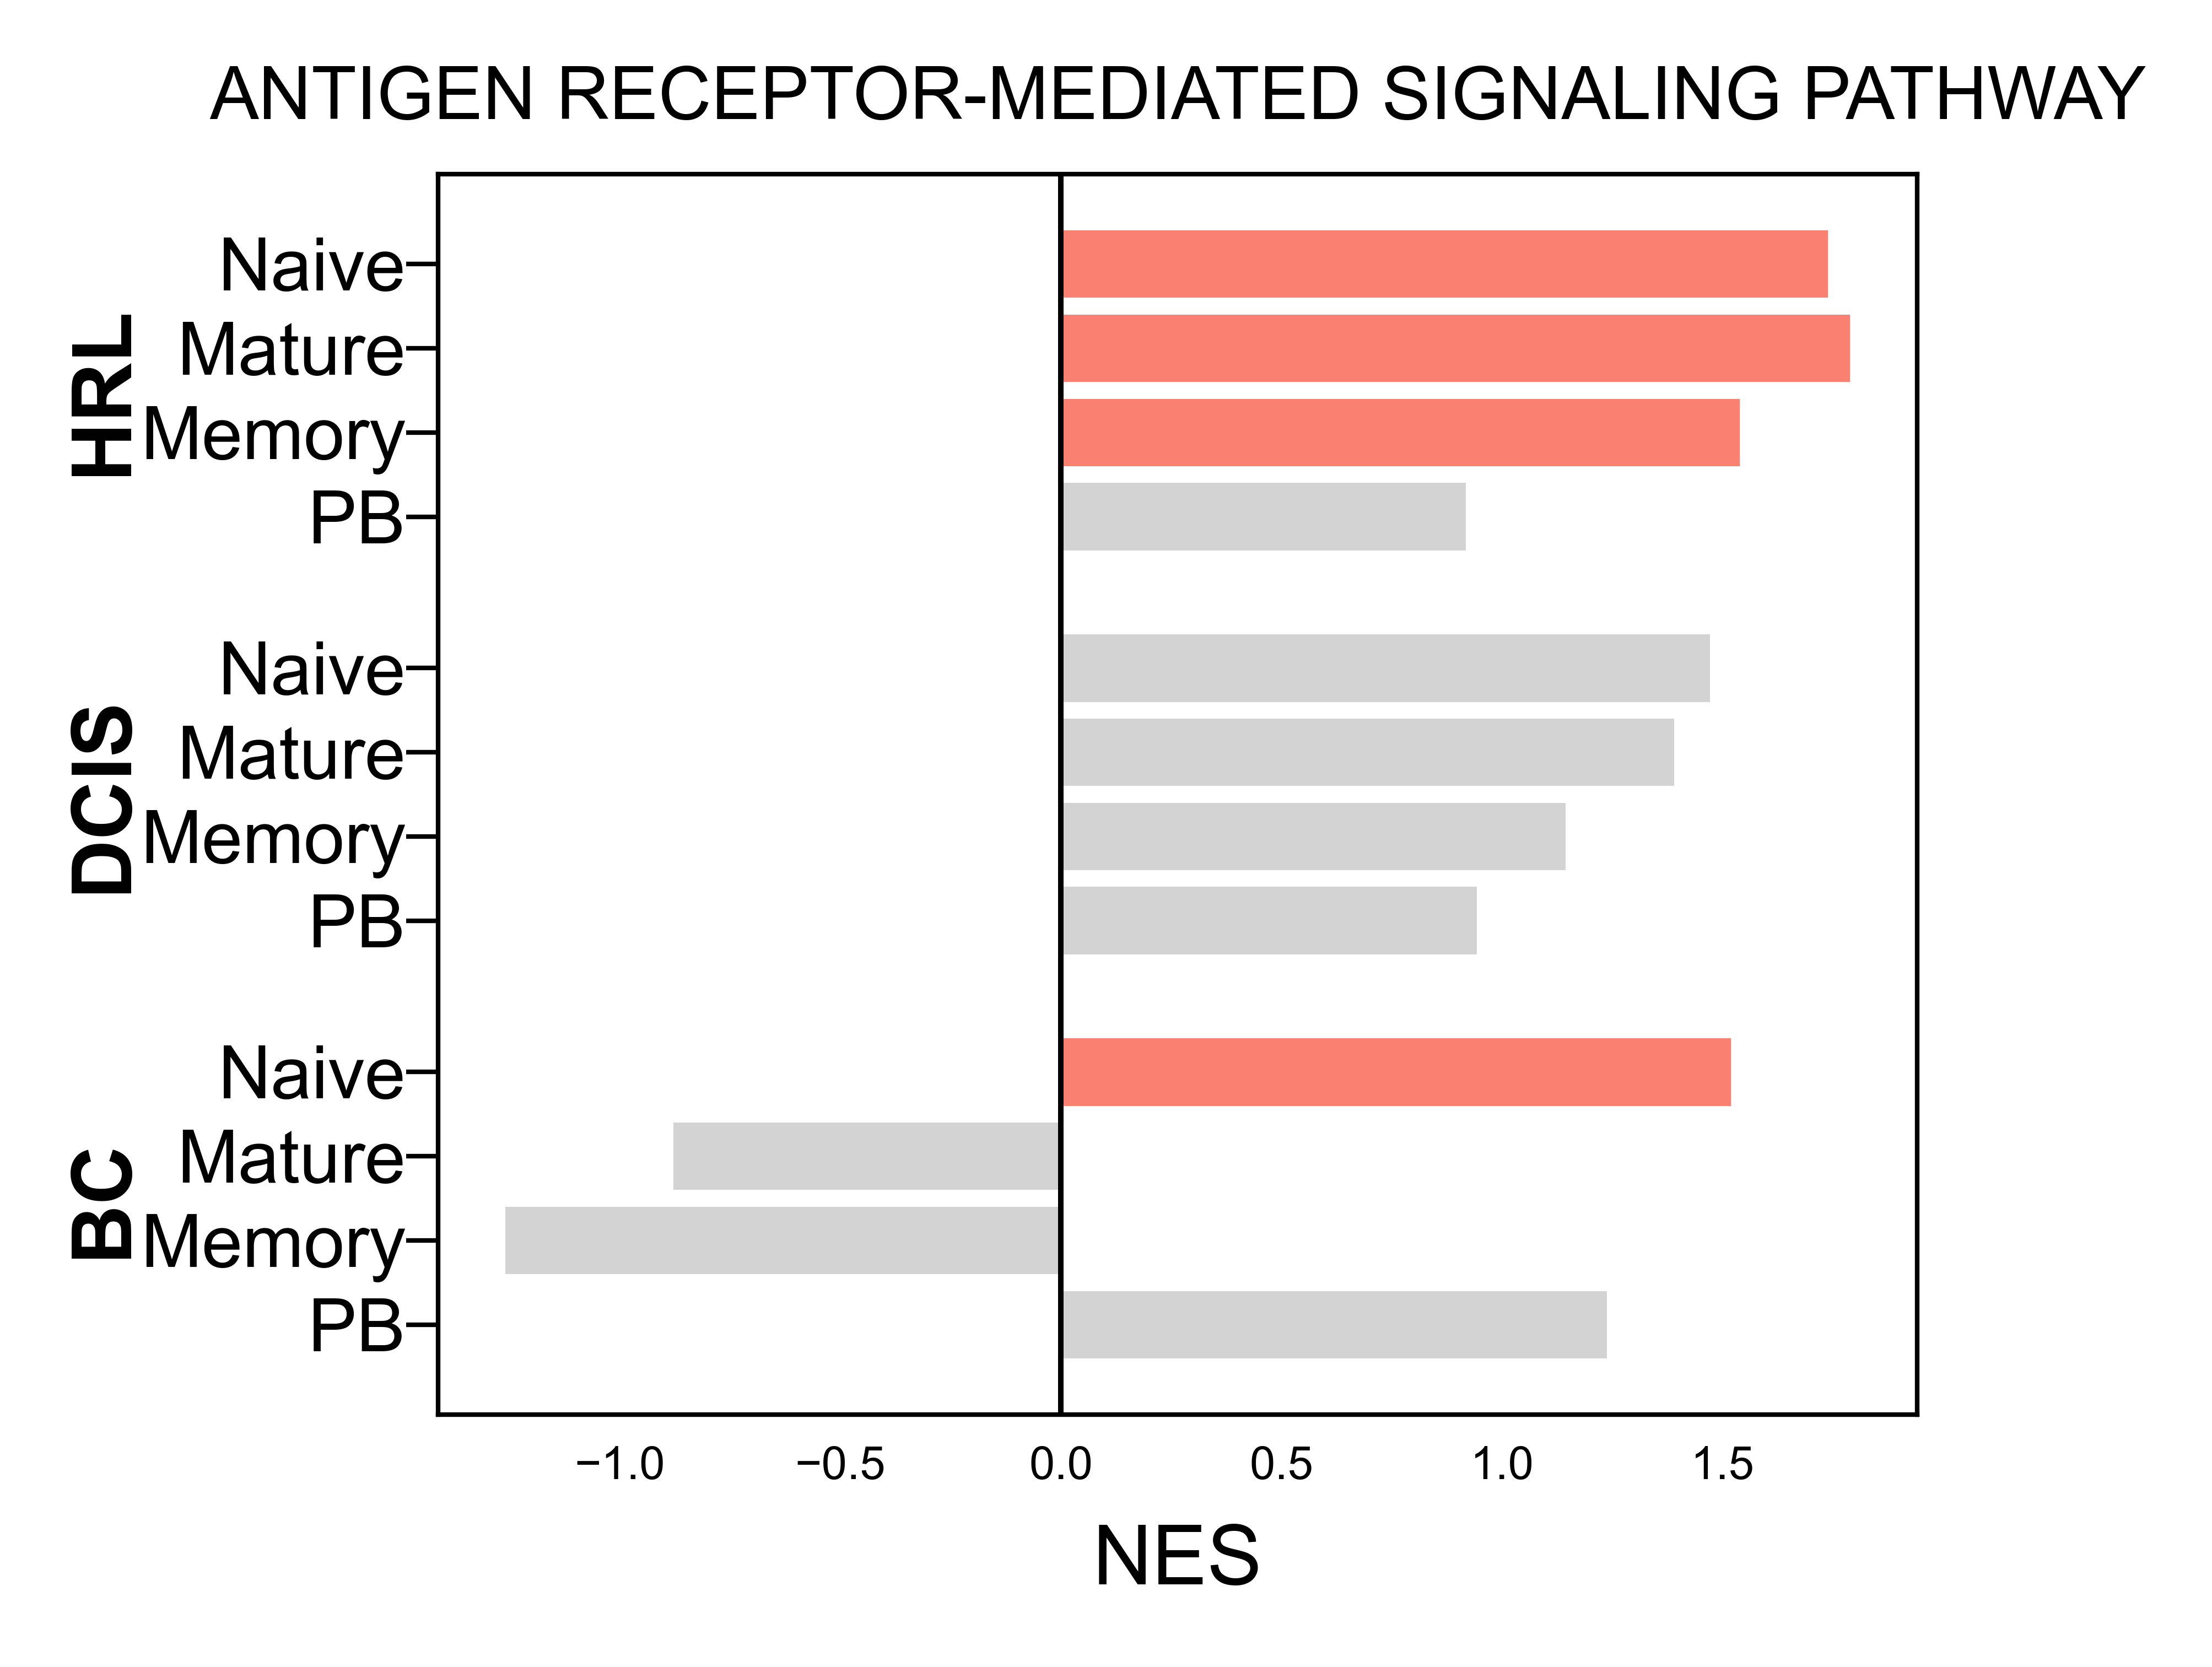

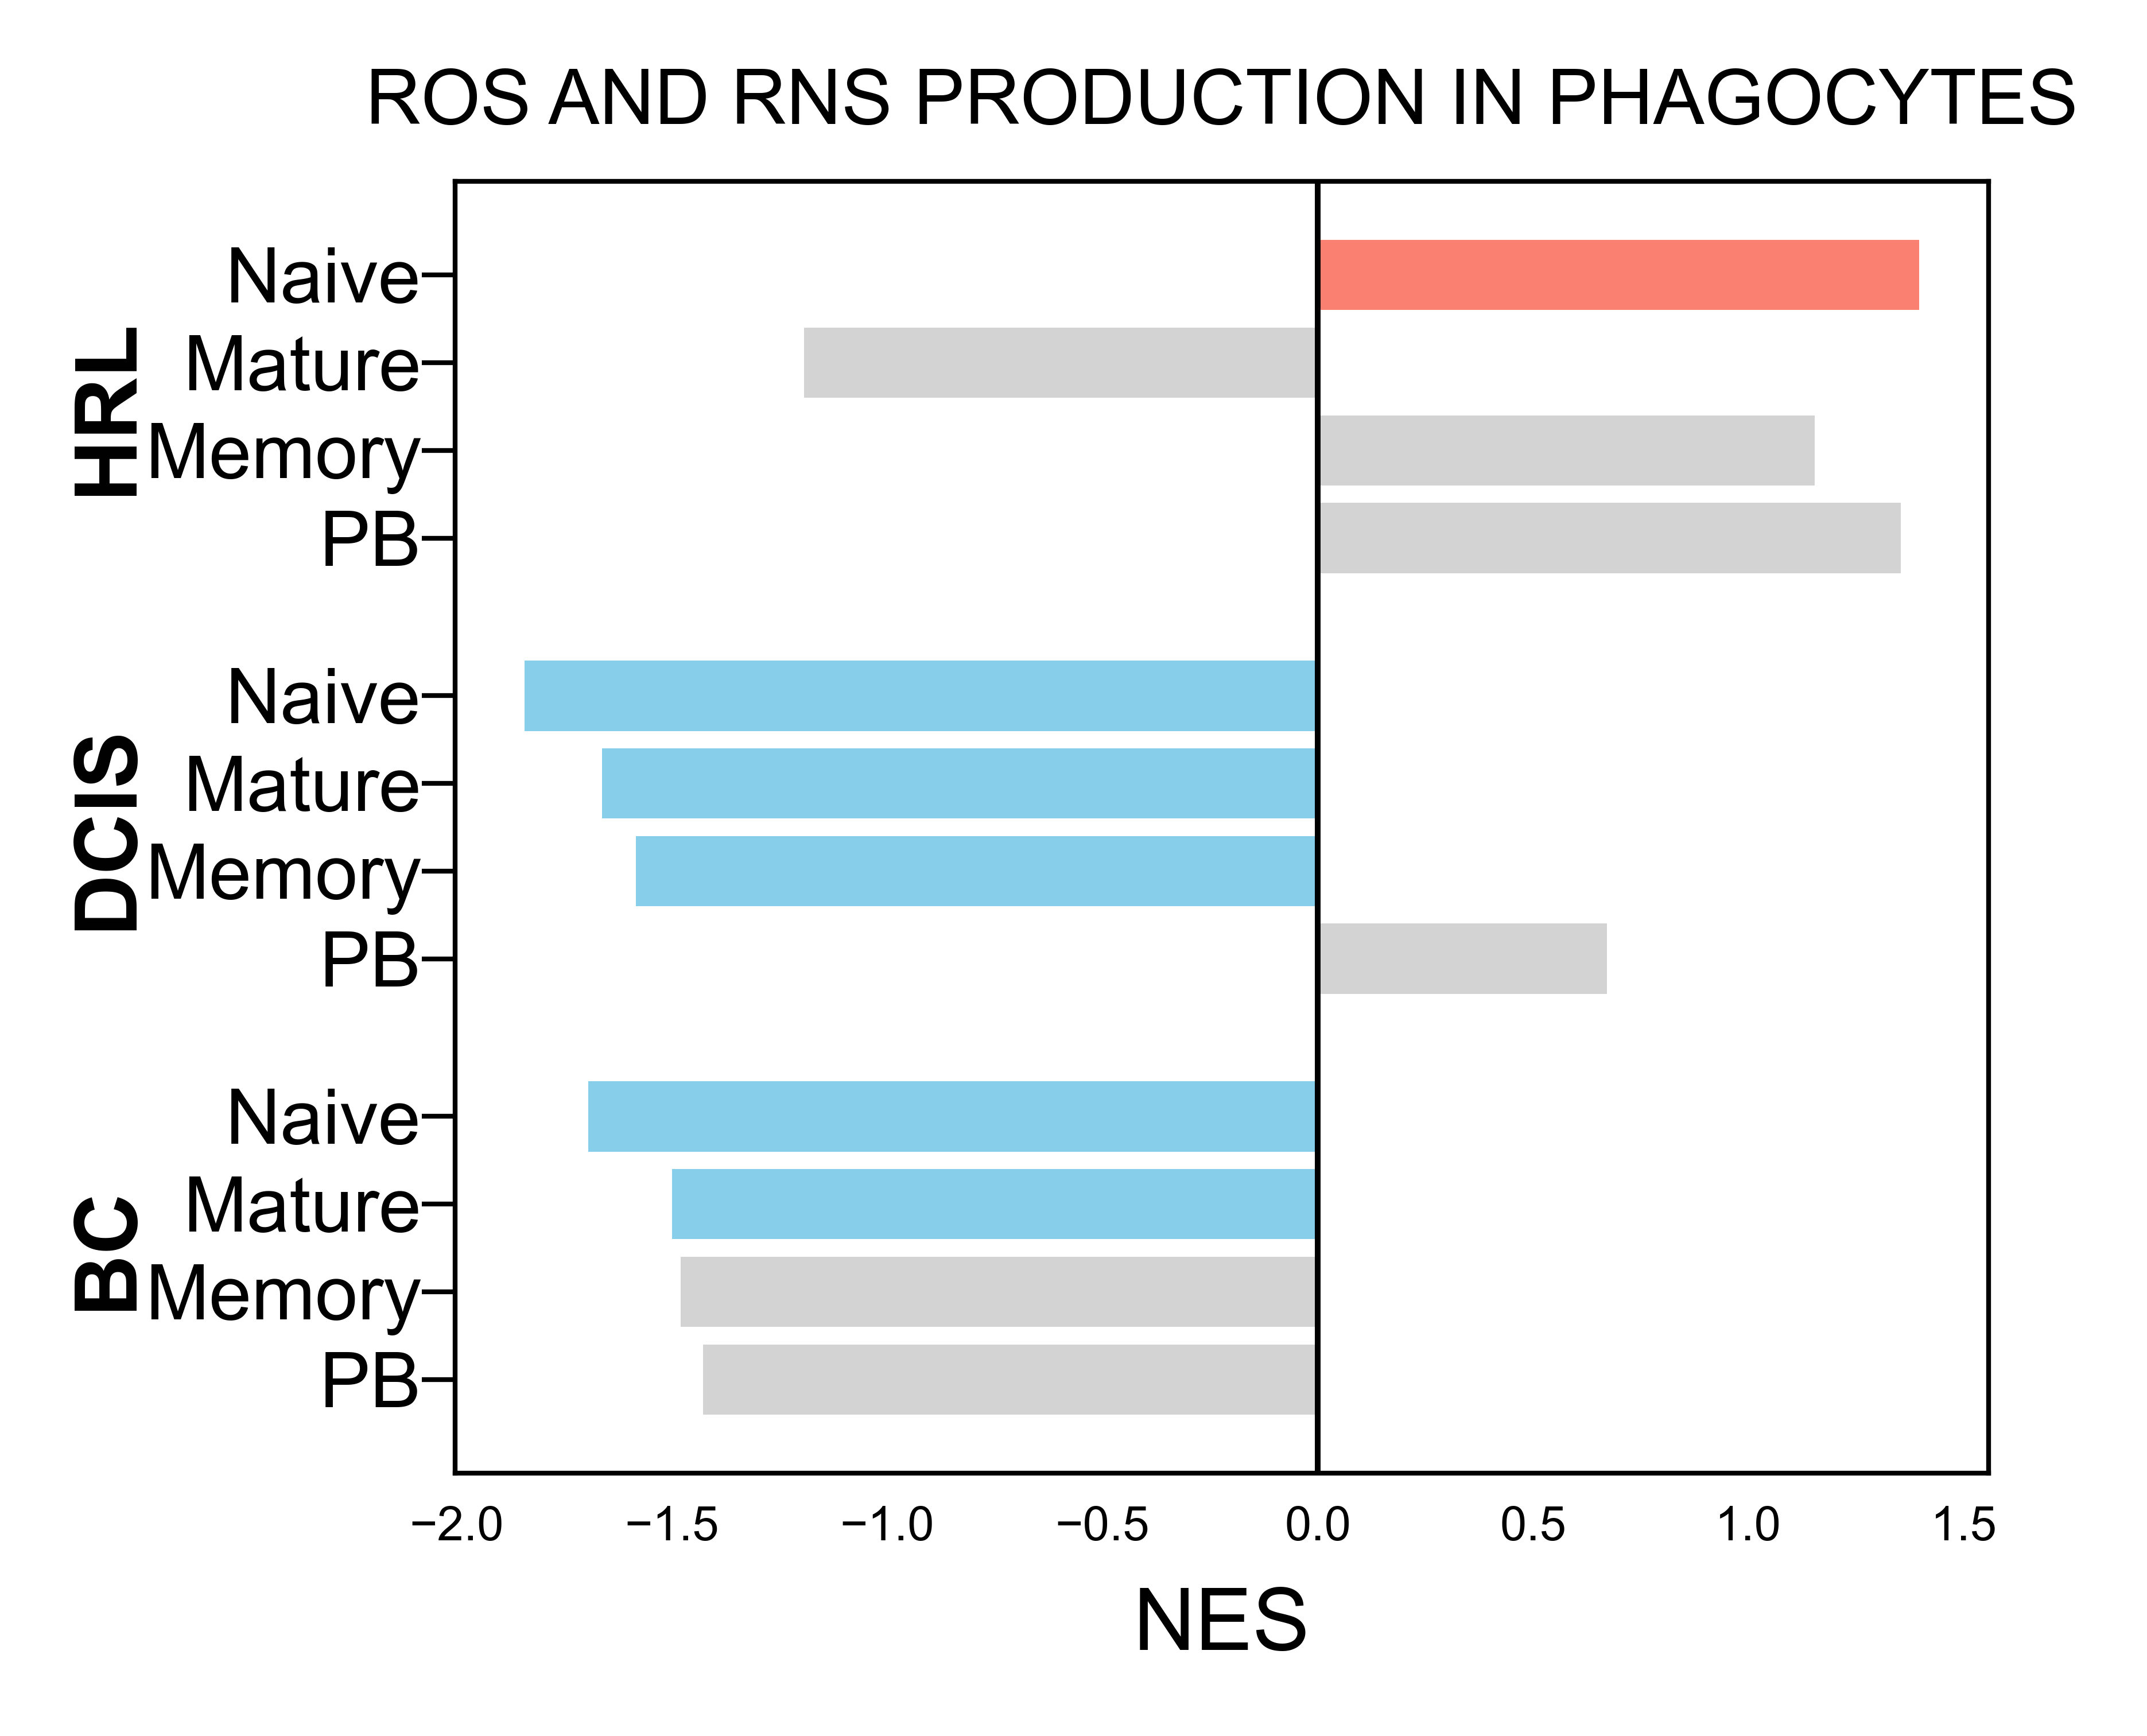

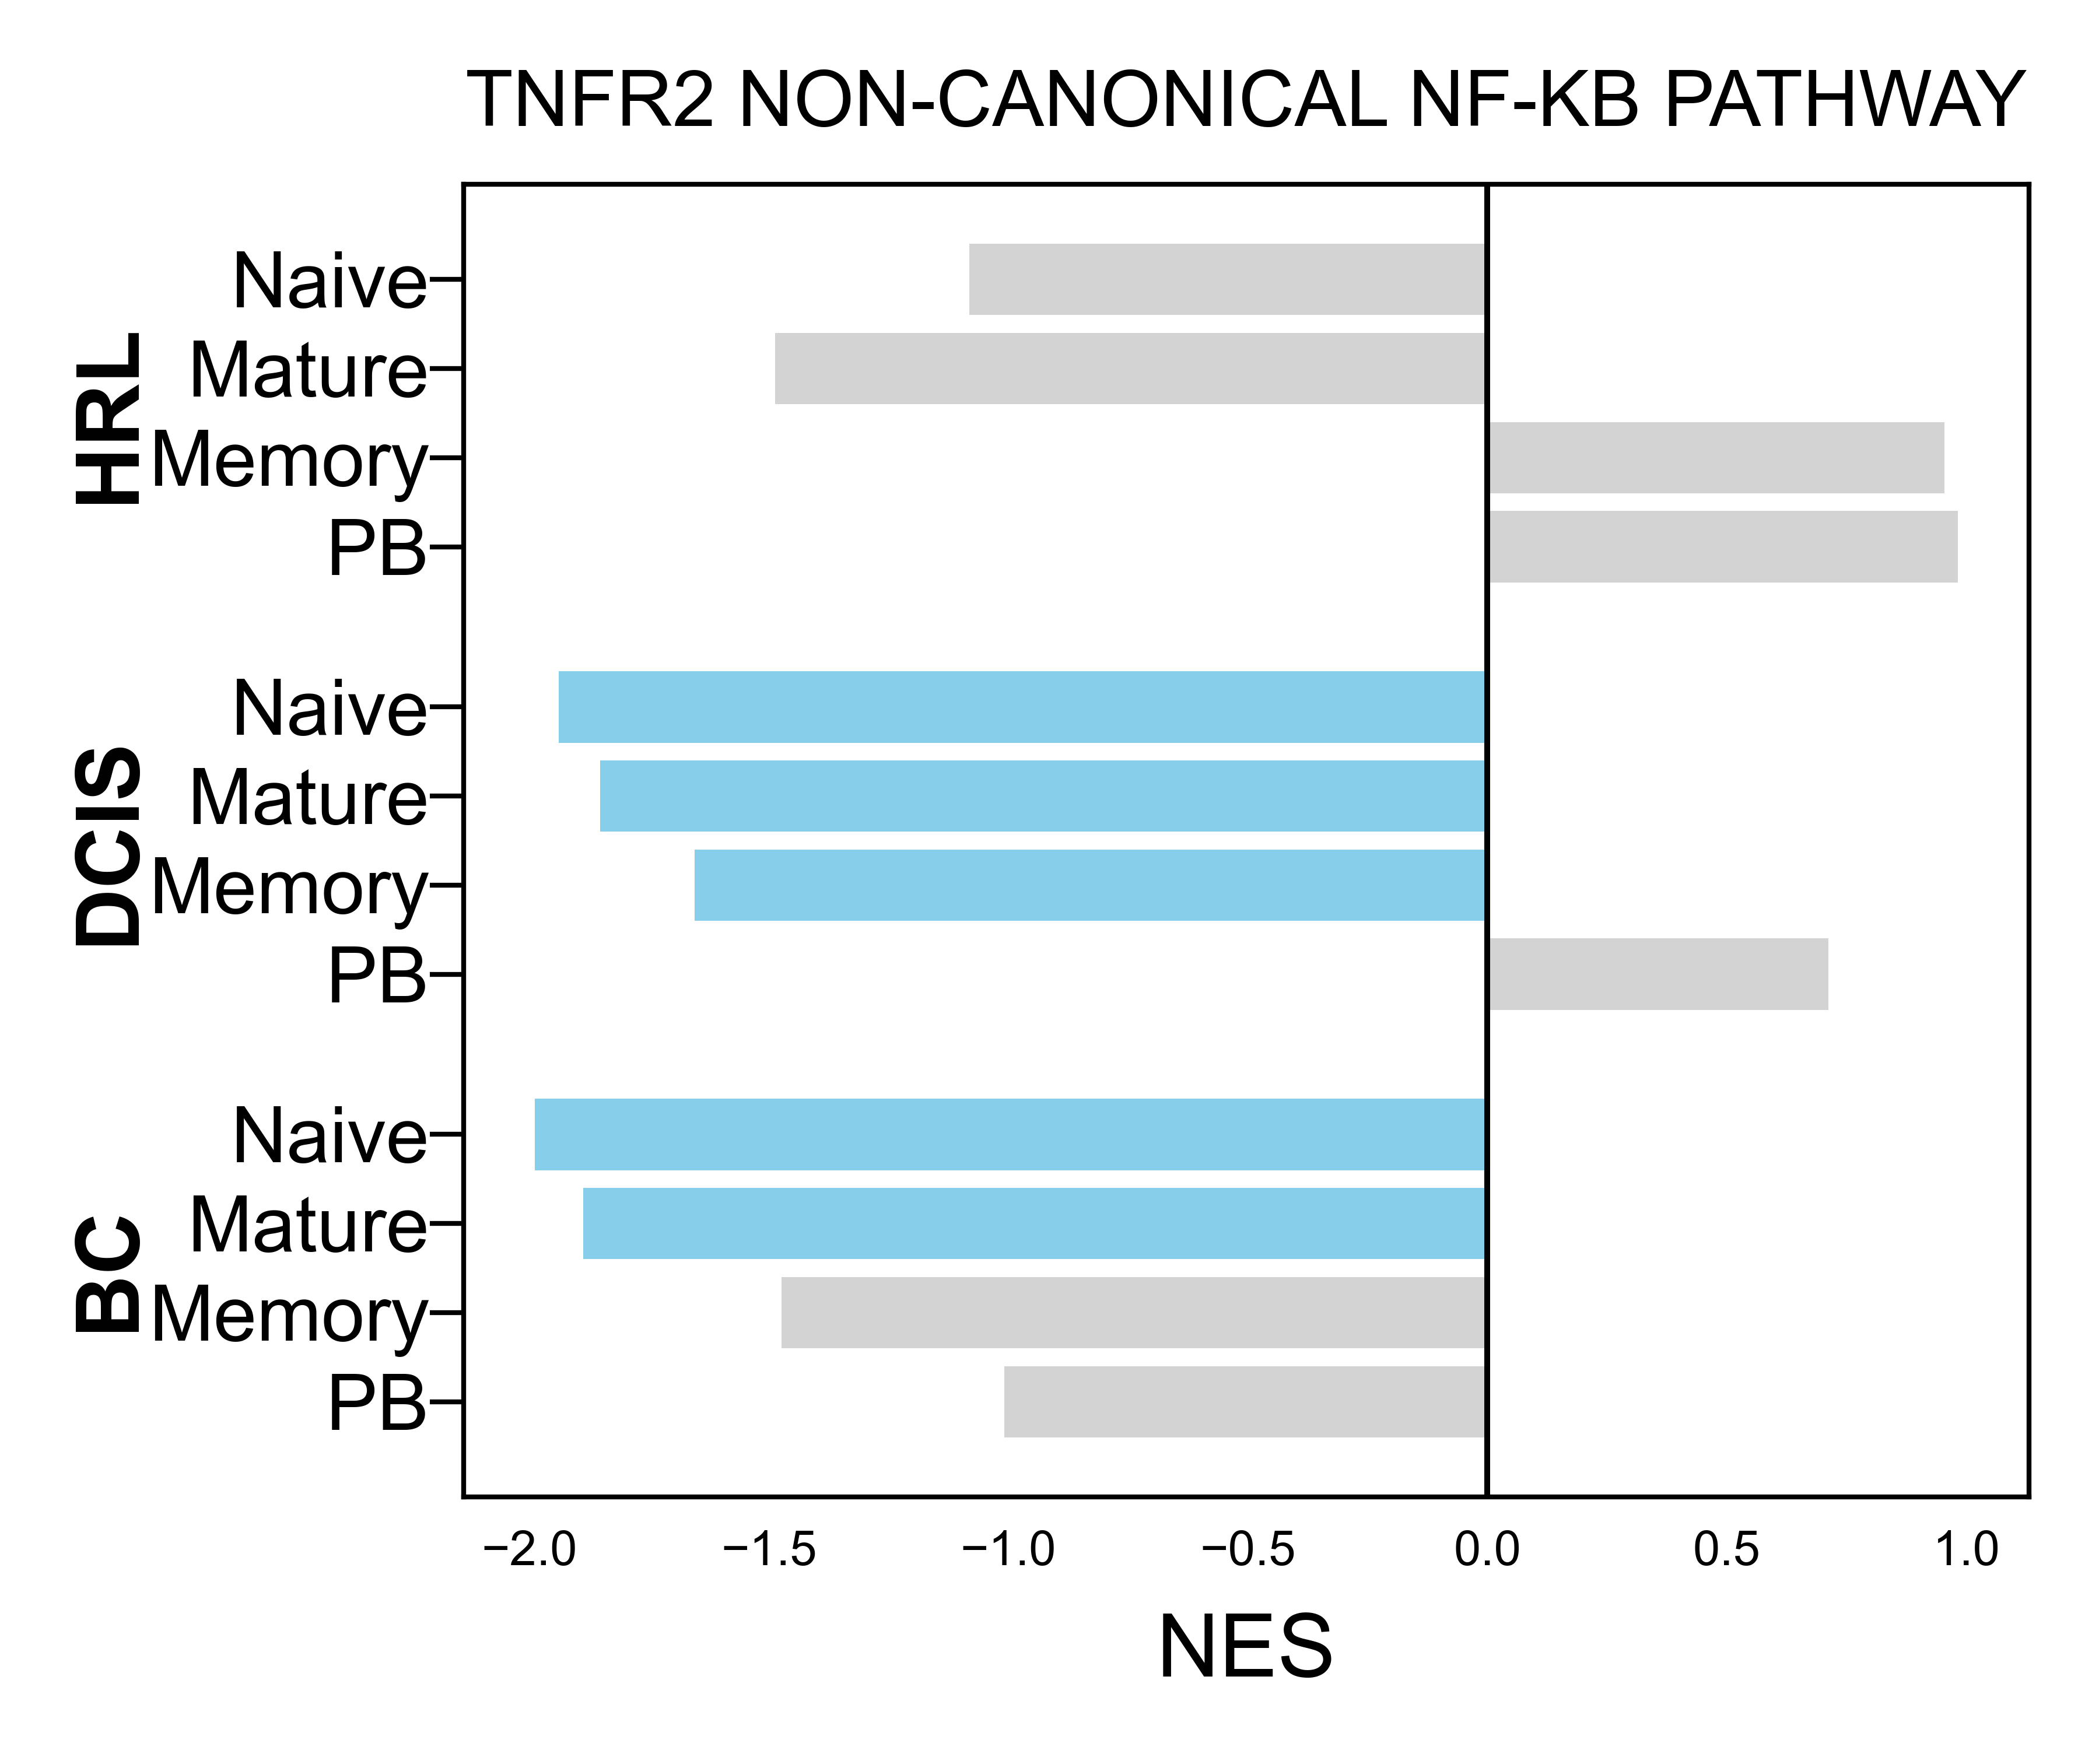

In [23]:
for path_sel in list_sel:
    
    dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
    qthres = .1
    
    abbr = {
        'Naive B': 'Naive',
        'Mature B': 'Mature',
        'Memory B': 'Memory',
        'Plasmablast': 'PB'
    }
    
    df = dfp.copy()
    df['ct'] = df['analysis_celltype'].map(abbr)
    
    group_order = df['analysis_group'].unique()
    ct_order = ['Naive','Mature','Memory','PB']
    
    # ---- build plotting table ----
    rows = []
    y = 0
    gap = 0.8
    group_centers = {}
    
    for g in group_order:
        sub = df[df['analysis_group'] == g]
        start = y
        for ct in ct_order:
            r = sub[sub['ct'] == ct]
            if not r.empty:
                r = r.iloc[0]
                rows.append({
                    'y': y,
                    'NES': r['NES'],
                    'q': r['FDR q-val'],
                    'ct': ct,
                    'group': g
                })
                y += 1
        group_centers[g] = (start + y - 1) / 2
        y += gap
    
    plot_df = pd.DataFrame(rows)
    
    # ---- colors ----
    colors = [
        'salmon' if (q < qthres and nes > 0)
        else 'skyblue' if (q < qthres and nes < 0)
        else 'lightgray'
        for nes, q in zip(plot_df['NES'], plot_df['q'])
    ]
    
    # ---- plot ----
    fig, ax = plt.subplots(figsize=(3, 2.5))
    ax.barh(plot_df['y'], plot_df['NES'], color=colors)
    ax.axvline(0, color='black', lw=0.6)
    
    ax.set_title(path_sel, fontsize=8)
    ax.set_yticks(plot_df['y'])
    ax.set_yticklabels(plot_df['ct'], fontsize=8)
    
    # ---- group labels ----
    for g, yc in group_centers.items():
        ax.text(
            -0.2, yc, g,
            ha='right', va='center',
            fontsize=9, fontweight='bold',
            rotation=90,
            transform=ax.get_yaxis_transform()
        )
    
    ax.set_xlabel('NES', fontsize=9)
    ax.invert_yaxis()
    plt.tight_layout()
    
    # plt.savefig(f'plots/F6/Mono_{path_sel}.svg')

In [24]:
panel_title_map = {

    'ANTIMICROBIAL HUMORAL RESPONSE': 'Humoral antimicrobial response',
    'ROS AND RNS PRODUCTION IN PHAGOCYTES': 'ROS/RNS production in phagocytes',
    'TNFR2 NON-CANONICAL NF-KB PATHWAY': 'TNFR2 noncanonical NF-κB',
    
    'B CELL DIFFERENTIATION': 'B cell differentiation',
    'B CELL ACTIVATION': 'B cell activation',
}

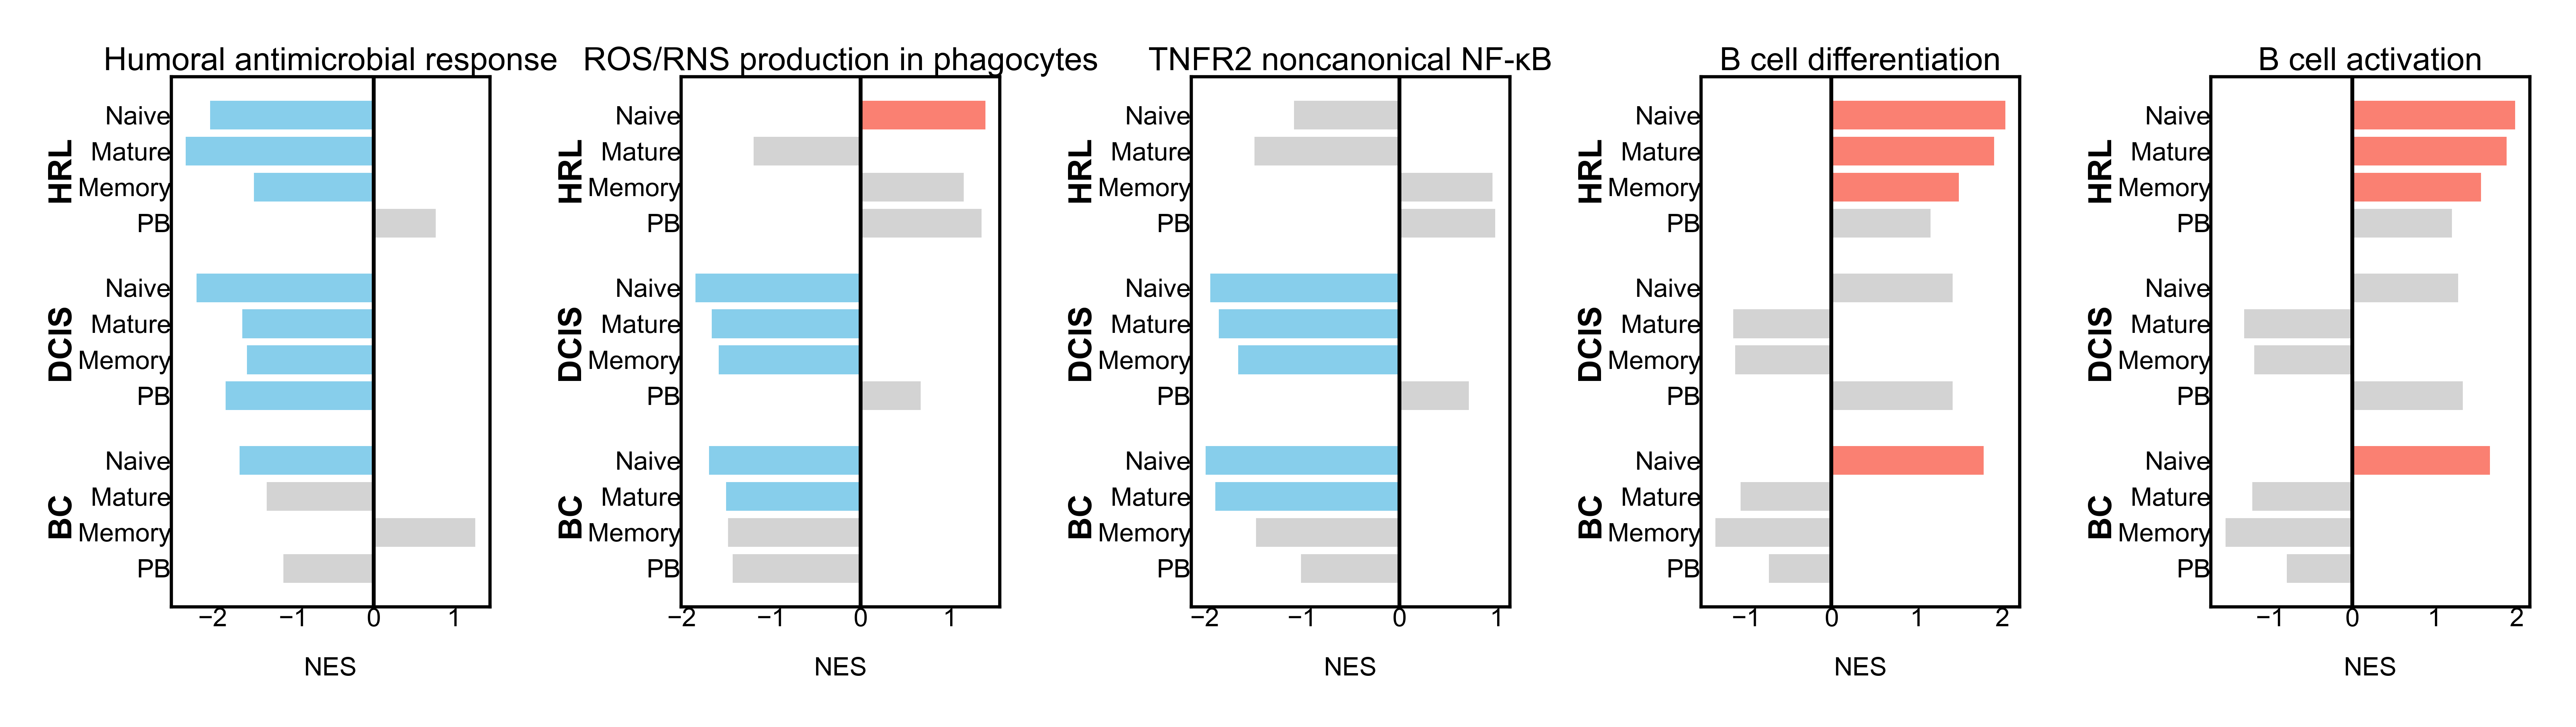

In [27]:
# make 1 row N columns
list_sel = list(panel_title_map.keys())

n = len(list_sel)
fig, axes = plt.subplots(
    1, n,
    figsize=(6.5, 1.5),   # scale width by number
    sharey=False
)

plt.subplots_adjust(wspace=0.6)

for ax, path_sel in zip(axes, list_sel):
    
    dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
    qthres = .1
    
    abbr = {
        'Naive B': 'Naive',
        'Mature B': 'Mature',
        'Memory B': 'Memory',
        'Plasmablast': 'PB'
    }
    
    df = dfp.copy()
    df['ct'] = df['analysis_celltype'].map(abbr)
    
    group_order = df['analysis_group'].unique()
    ct_order = ['Naive','Mature','Memory','PB']
    
    # ---- build plotting table ----
    rows = []
    y = 0
    gap = 0.8
    group_centers = {}
    
    for g in group_order:
        sub = df[df['analysis_group'] == g]
        start = y
        for ct in ct_order:
            r = sub[sub['ct'] == ct]
            if not r.empty:
                r = r.iloc[0]
                rows.append({
                    'y': y,
                    'NES': r['NES'],
                    'q': r['FDR q-val'],
                    'ct': ct,
                    'group': g
                })
                y += 1
        group_centers[g] = (start + y - 1) / 2
        y += gap
    
    plot_df = pd.DataFrame(rows)
    
    # ---- colors ----
    colors = [
        'salmon' if (q < qthres and nes > 0)
        else 'skyblue' if (q < qthres and nes < 0)
        else 'lightgray'
        for nes, q in zip(plot_df['NES'], plot_df['q'])
    ]
    
    # ---- plot ----
    ax.barh(plot_df['y'], plot_df['NES'], color=colors)
    ax.axvline(0, color='black', lw=0.6)

    panel_title = panel_title_map[path_sel]
    ax.set_title(panel_title, fontsize=5, pad=1)

    ax.set_xlabel('NES', fontsize=4)
    ax.set_yticks(plot_df['y'])
    ax.set_yticklabels(plot_df['ct'], fontsize=4)
    
    # tick cosmetics
    ax.tick_params(axis='x', length=.2, labelsize=4)
    ax.tick_params(axis='y', length=0)   # remove tick length
    
    # group labels
    for g, yc in group_centers.items():
        ax.text(
            -0.3, yc, g,
            ha='right', va='center',
            fontsize=5, fontweight='bold',
            rotation=90,
            transform=ax.get_yaxis_transform()
        )
    
    ax.invert_yaxis()


plt.subplots_adjust(wspace=0.6)
plt.savefig('plots/F7_2/B_multiplot.svg')
plt.show()

In [28]:
path_sel = 'B CELL DIFFERENTIATION'

dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
dfp

,analysis_celltype,analysis_group,NES,FDR q-val
1,Naive B,HRL,2.033809,0.000000
26,Naive B,DCIS,1.419047,0.221385
4,Naive B,BC,1.782318,0.014569
3,Mature B,HRL,1.901477,0.000000
70,Mature B,DCIS,-1.151042,0.388443
77,Mature B,BC,-1.065174,0.607837
16,Memory B,HRL,1.489267,0.042358
50,Memory B,DCIS,-1.127024,0.437780
16,Memory B,BC,-1.356279,0.418730
29,Plasmablast,HRL,1.160271,0.788444


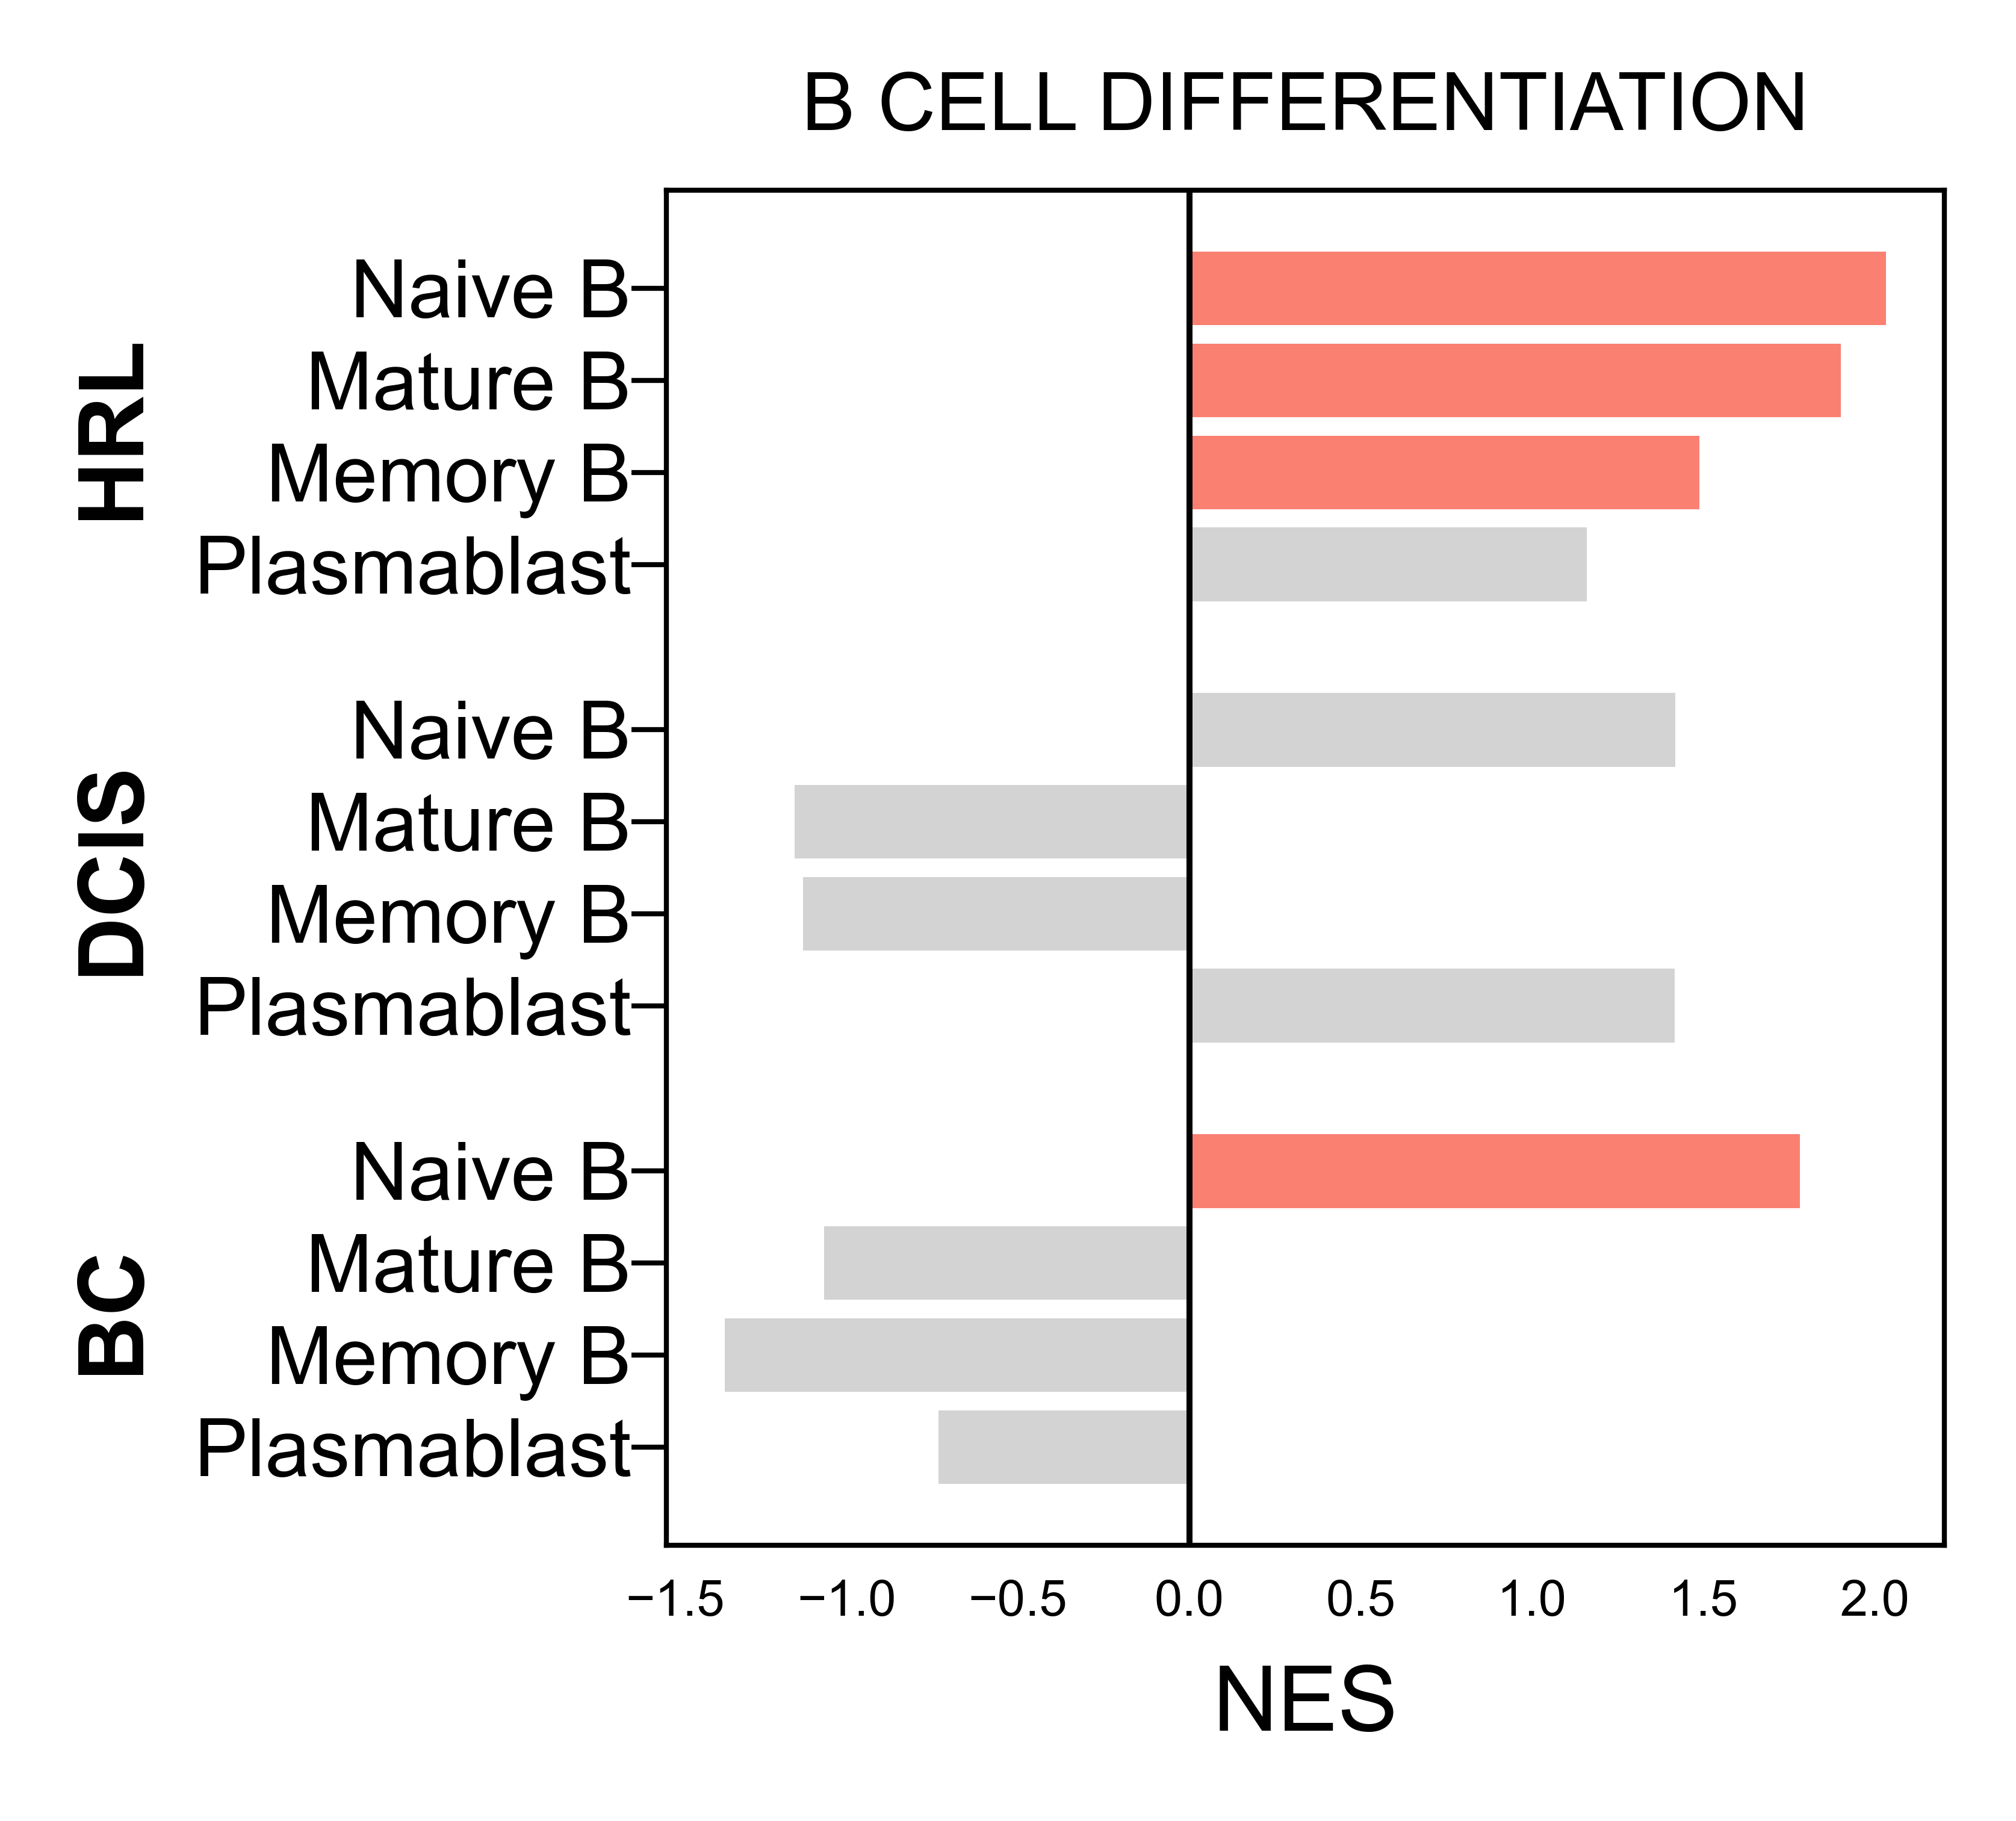

In [30]:
qthres = .1


df = dfp.copy()
df['ct'] = df['analysis_celltype']#.map(abbr)

group_order = df['analysis_group'].unique()
ct_order = [
    'Naive B',    # Naive
    'Mature B',   # Central memory
    'Memory B',   # Effector memory
    'Plasmablast'       # Regulatory (parallel lineage)
]

# ---- build plotting table ----
rows = []
y = 0
gap = 0.8
group_centers = {}

for g in group_order:
    sub = df[df['analysis_group'] == g]
    start = y
    for ct in ct_order:
        r = sub[sub['ct'] == ct]
        if not r.empty:
            r = r.iloc[0]
            rows.append({
                'y': y,
                'NES': r['NES'],
                'q': r['FDR q-val'],
                'ct': ct,
                'group': g
            })
            y += 1
    group_centers[g] = (start + y - 1) / 2
    y += gap

plot_df = pd.DataFrame(rows)

# ---- colors ----
colors = [
    'salmon' if (q < qthres and nes > 0)
    else 'skyblue' if (q < qthres and nes < 0)
    else 'lightgray'
    for nes, q in zip(plot_df['NES'], plot_df['q'])
]

# ---- plot ----
fig, ax = plt.subplots(figsize=(3, 2.5))
ax.barh(plot_df['y'], plot_df['NES'], color=colors)
ax.axvline(0, color='black', lw=0.6)

ax.set_title(path_sel, fontsize=8)
ax.set_yticks(plot_df['y'])
ax.set_yticklabels(plot_df['ct'], fontsize=8)

# ---- group labels ----
for g, yc in group_centers.items():
    ax.text(
        -0.4, yc, g,
        ha='right', va='center',
        fontsize=9, fontweight='bold',
        rotation=90,
        transform=ax.get_yaxis_transform()
    )

ax.set_xlabel('NES', fontsize=9)
ax.invert_yaxis()
plt.tight_layout()

plt.savefig(f'plots/F7_2/{celltype_major}_{path_sel}.svg')

In [31]:
path_sel = 'B CELL ACTIVATION'

dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
dfp

,analysis_celltype,analysis_group,NES,FDR q-val
4,Naive B,HRL,1.977955,0.000000
44,Naive B,DCIS,1.286431,0.348485
9,Naive B,BC,1.669843,0.028504
4,Mature B,HRL,1.873429,0.000000
33,Mature B,DCIS,-1.317102,0.275308
49,Mature B,BC,-1.216540,0.337913
7,Memory B,HRL,1.560087,0.035752
41,Memory B,DCIS,-1.191565,0.354393
4,Memory B,BC,-1.542139,0.174004
15,Plasmablast,HRL,1.209399,1.000000


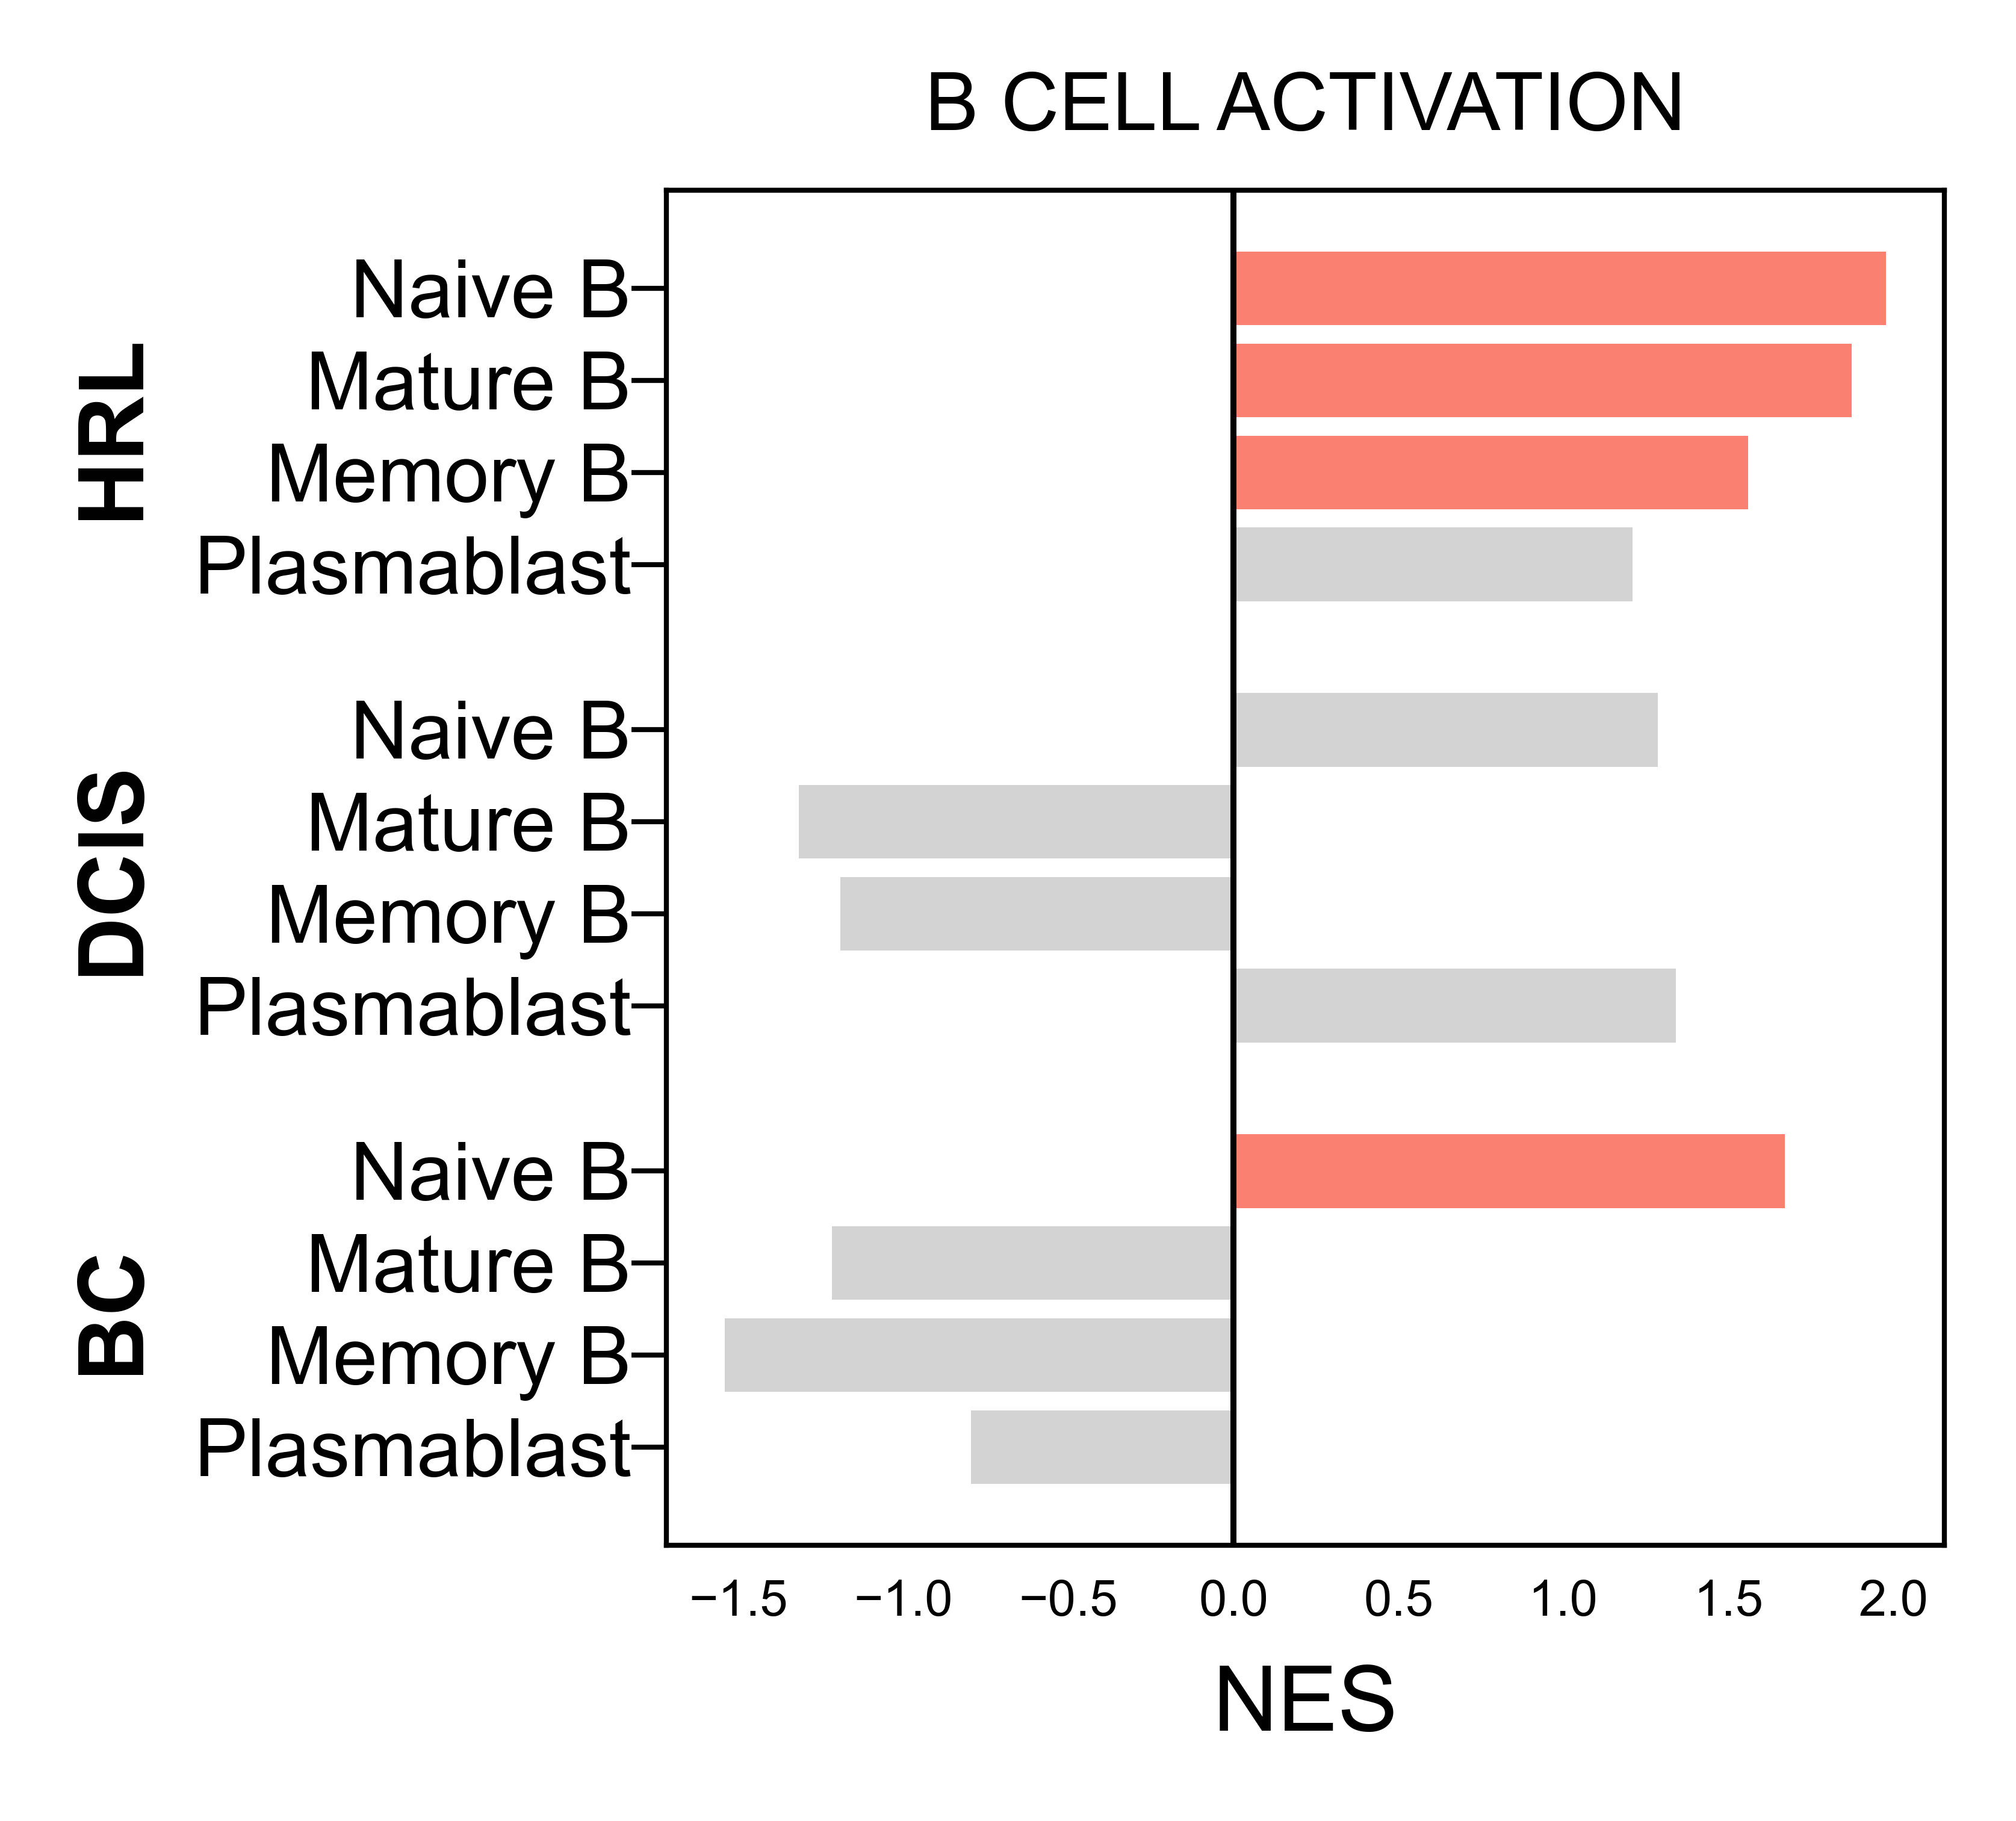

In [32]:
qthres = .1


df = dfp.copy()
df['ct'] = df['analysis_celltype']#.map(abbr)

group_order = df['analysis_group'].unique()
ct_order = [
    'Naive B',    # Naive
    'Mature B',   # Central memory
    'Memory B',   # Effector memory
    'Plasmablast'       # Regulatory (parallel lineage)
]

# ---- build plotting table ----
rows = []
y = 0
gap = 0.8
group_centers = {}

for g in group_order:
    sub = df[df['analysis_group'] == g]
    start = y
    for ct in ct_order:
        r = sub[sub['ct'] == ct]
        if not r.empty:
            r = r.iloc[0]
            rows.append({
                'y': y,
                'NES': r['NES'],
                'q': r['FDR q-val'],
                'ct': ct,
                'group': g
            })
            y += 1
    group_centers[g] = (start + y - 1) / 2
    y += gap

plot_df = pd.DataFrame(rows)

# ---- colors ----
colors = [
    'salmon' if (q < qthres and nes > 0)
    else 'skyblue' if (q < qthres and nes < 0)
    else 'lightgray'
    for nes, q in zip(plot_df['NES'], plot_df['q'])
]

# ---- plot ----
fig, ax = plt.subplots(figsize=(3, 2.5))
ax.barh(plot_df['y'], plot_df['NES'], color=colors)
ax.axvline(0, color='black', lw=0.6)

ax.set_title(path_sel, fontsize=8)
ax.set_yticks(plot_df['y'])
ax.set_yticklabels(plot_df['ct'], fontsize=8)

# ---- group labels ----
for g, yc in group_centers.items():
    ax.text(
        -0.4, yc, g,
        ha='right', va='center',
        fontsize=9, fontweight='bold',
        rotation=90,
        transform=ax.get_yaxis_transform()
    )

ax.set_xlabel('NES', fontsize=9)
ax.invert_yaxis()
plt.tight_layout()

plt.savefig(f'plots/F7_2/{celltype_major}_{path_sel}.svg')

In [35]:
path_sel = 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY'

dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
dfp

,analysis_celltype,analysis_group,NES,FDR q-val
6,Naive B,HRL,1.737867,0.001836
19,Naive B,DCIS,1.471623,0.299837
27,Naive B,BC,1.518675,0.071718
6,Mature B,HRL,1.788647,0.000512
24,Mature B,DCIS,1.389442,0.274805
98,Mature B,BC,-0.878462,0.868450
10,Memory B,HRL,1.538604,0.031848
48,Memory B,DCIS,1.143985,1.000000
29,Memory B,BC,-1.259444,0.543148
82,Plasmablast,HRL,0.918069,0.918688


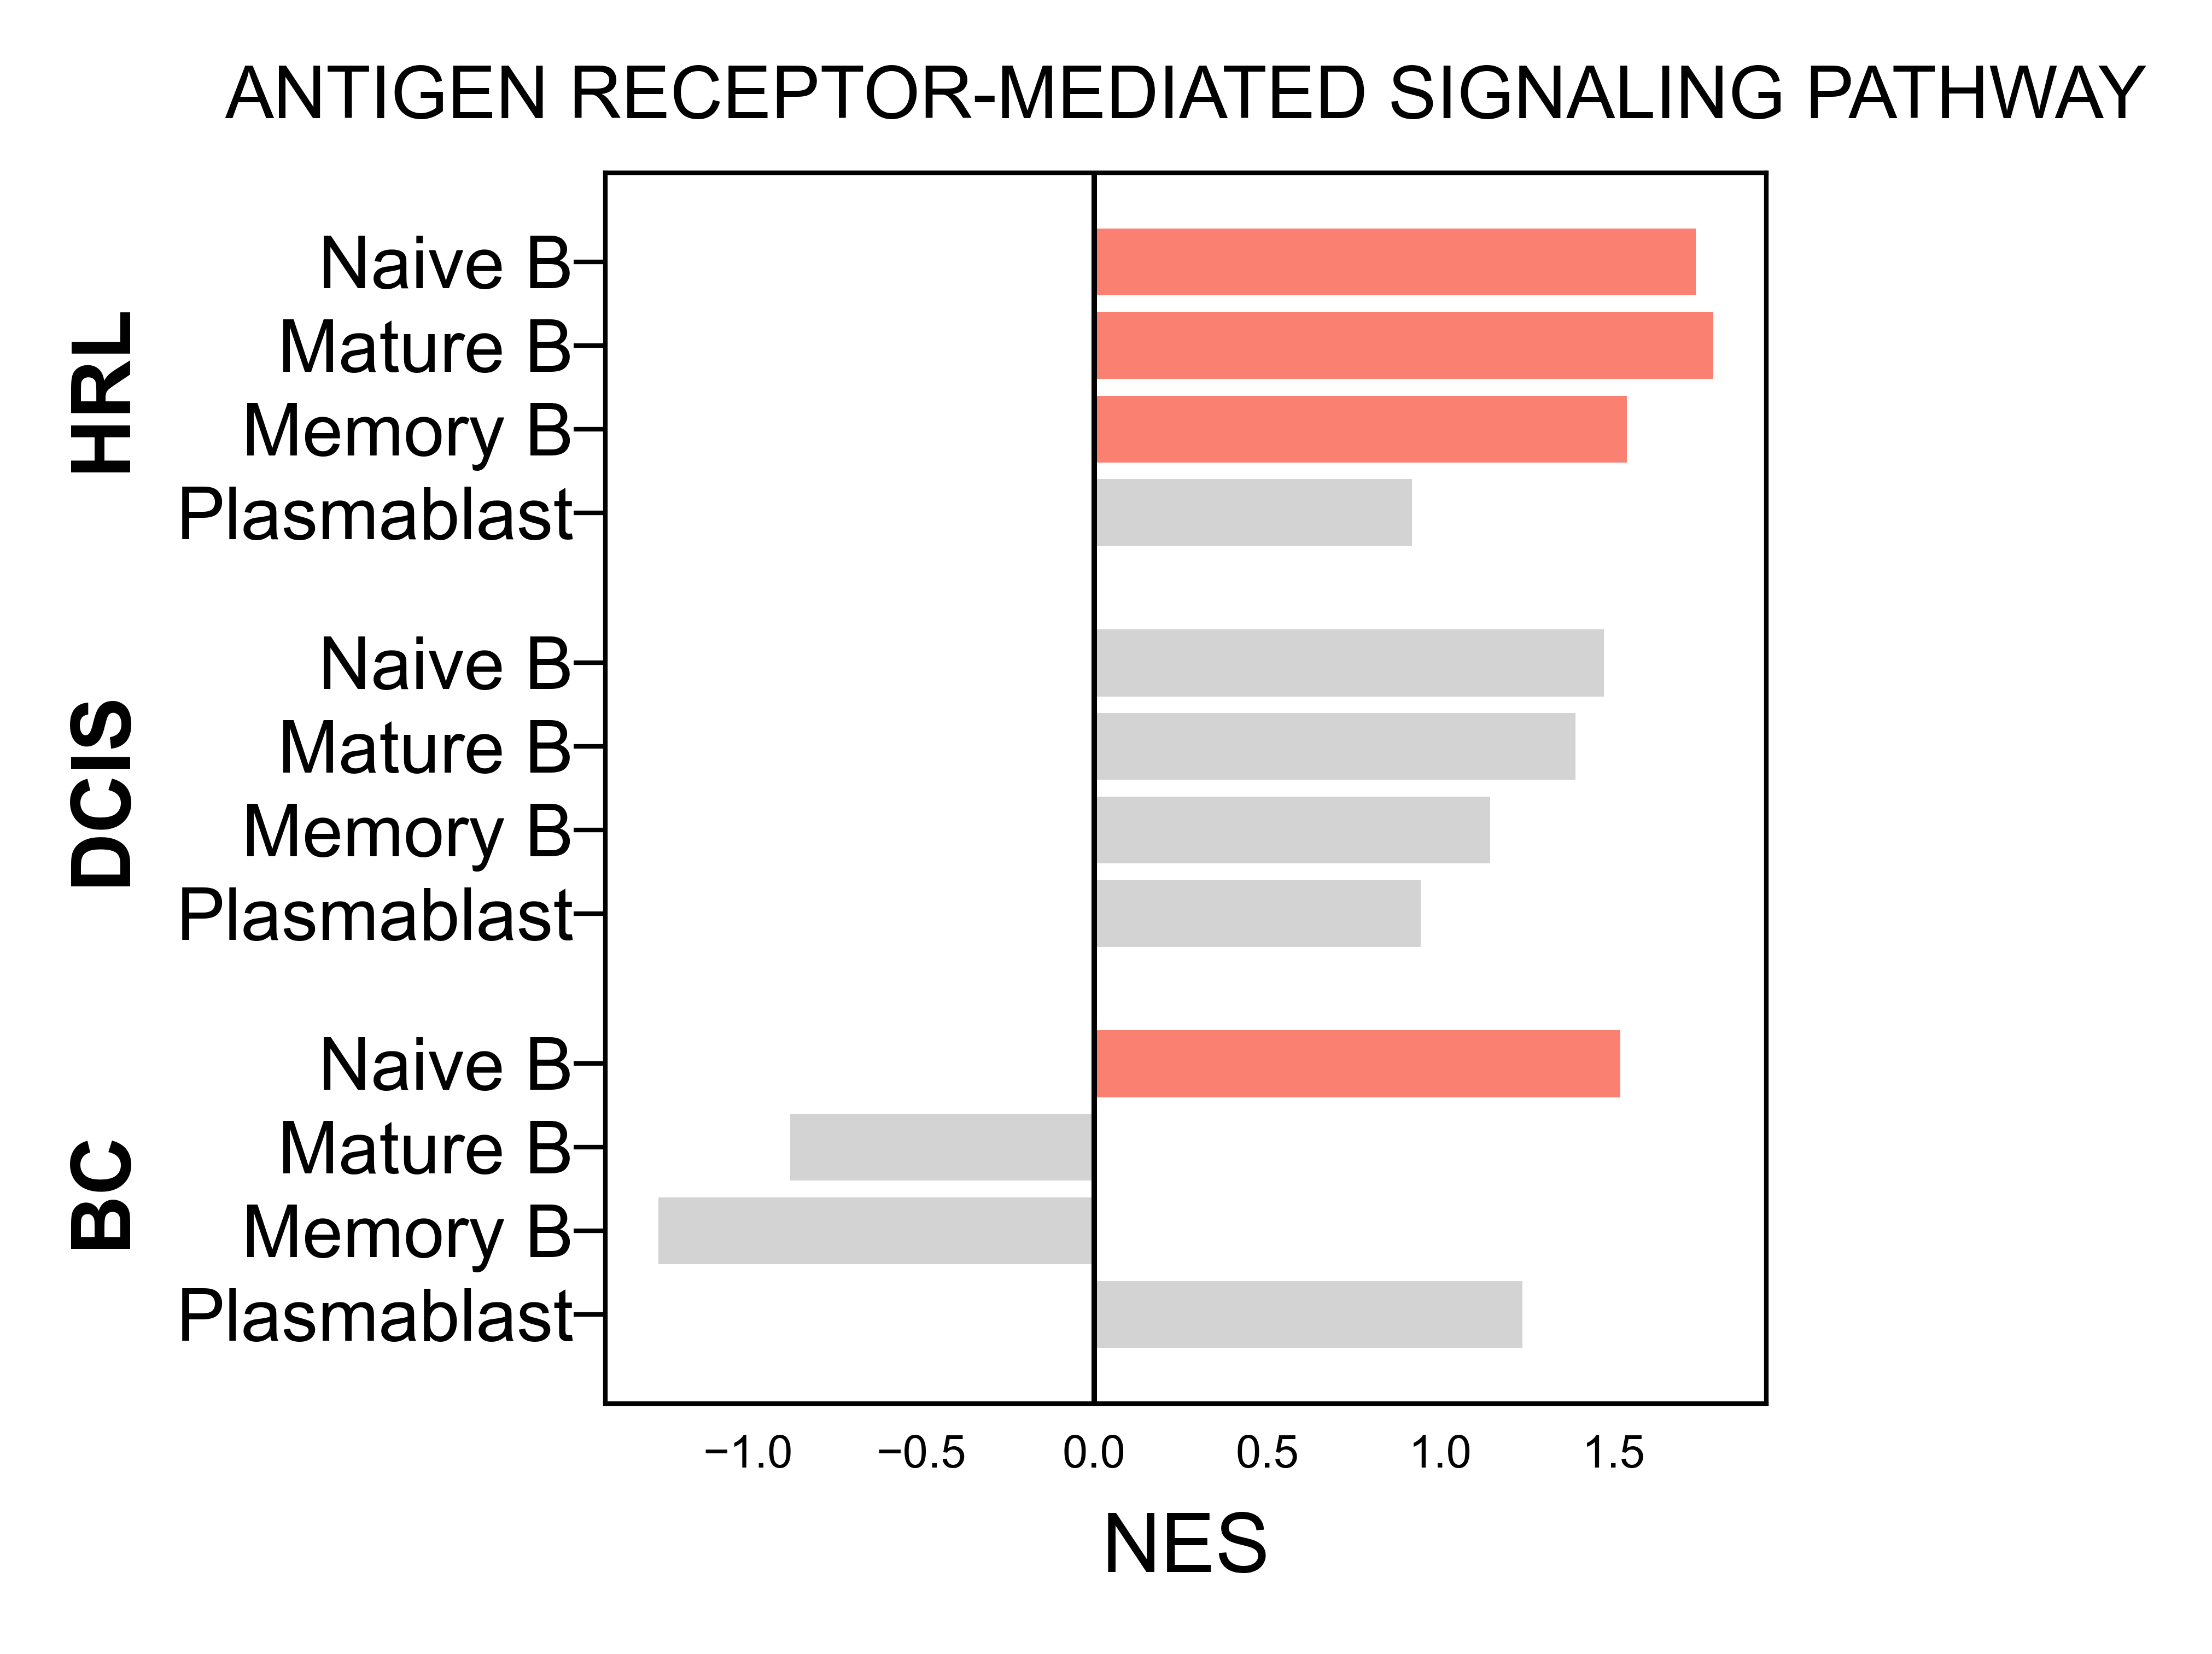

In [37]:
qthres = .1


df = dfp.copy()
df['ct'] = df['analysis_celltype']#.map(abbr)

group_order = df['analysis_group'].unique()
ct_order = [
    'Naive B',    # Naive
    'Mature B',   # Central memory
    'Memory B',   # Effector memory
    'Plasmablast'       # Regulatory (parallel lineage)
]

# ---- build plotting table ----
rows = []
y = 0
gap = 0.8
group_centers = {}

for g in group_order:
    sub = df[df['analysis_group'] == g]
    start = y
    for ct in ct_order:
        r = sub[sub['ct'] == ct]
        if not r.empty:
            r = r.iloc[0]
            rows.append({
                'y': y,
                'NES': r['NES'],
                'q': r['FDR q-val'],
                'ct': ct,
                'group': g
            })
            y += 1
    group_centers[g] = (start + y - 1) / 2
    y += gap

plot_df = pd.DataFrame(rows)

# ---- colors ----
colors = [
    'salmon' if (q < qthres and nes > 0)
    else 'skyblue' if (q < qthres and nes < 0)
    else 'lightgray'
    for nes, q in zip(plot_df['NES'], plot_df['q'])
]

# ---- plot ----
fig, ax = plt.subplots(figsize=(3, 2.5))
ax.barh(plot_df['y'], plot_df['NES'], color=colors)
ax.axvline(0, color='black', lw=0.6)

ax.set_title(path_sel, fontsize=8)
ax.set_yticks(plot_df['y'])
ax.set_yticklabels(plot_df['ct'], fontsize=8)

# ---- group labels ----
for g, yc in group_centers.items():
    ax.text(
        -0.4, yc, g,
        ha='right', va='center',
        fontsize=9, fontweight='bold',
        rotation=90,
        transform=ax.get_yaxis_transform()
    )

ax.set_xlabel('NES', fontsize=9)
ax.invert_yaxis()
plt.tight_layout()

plt.savefig(f'plots/F7_2/{celltype_major}_{path_sel}.svg')

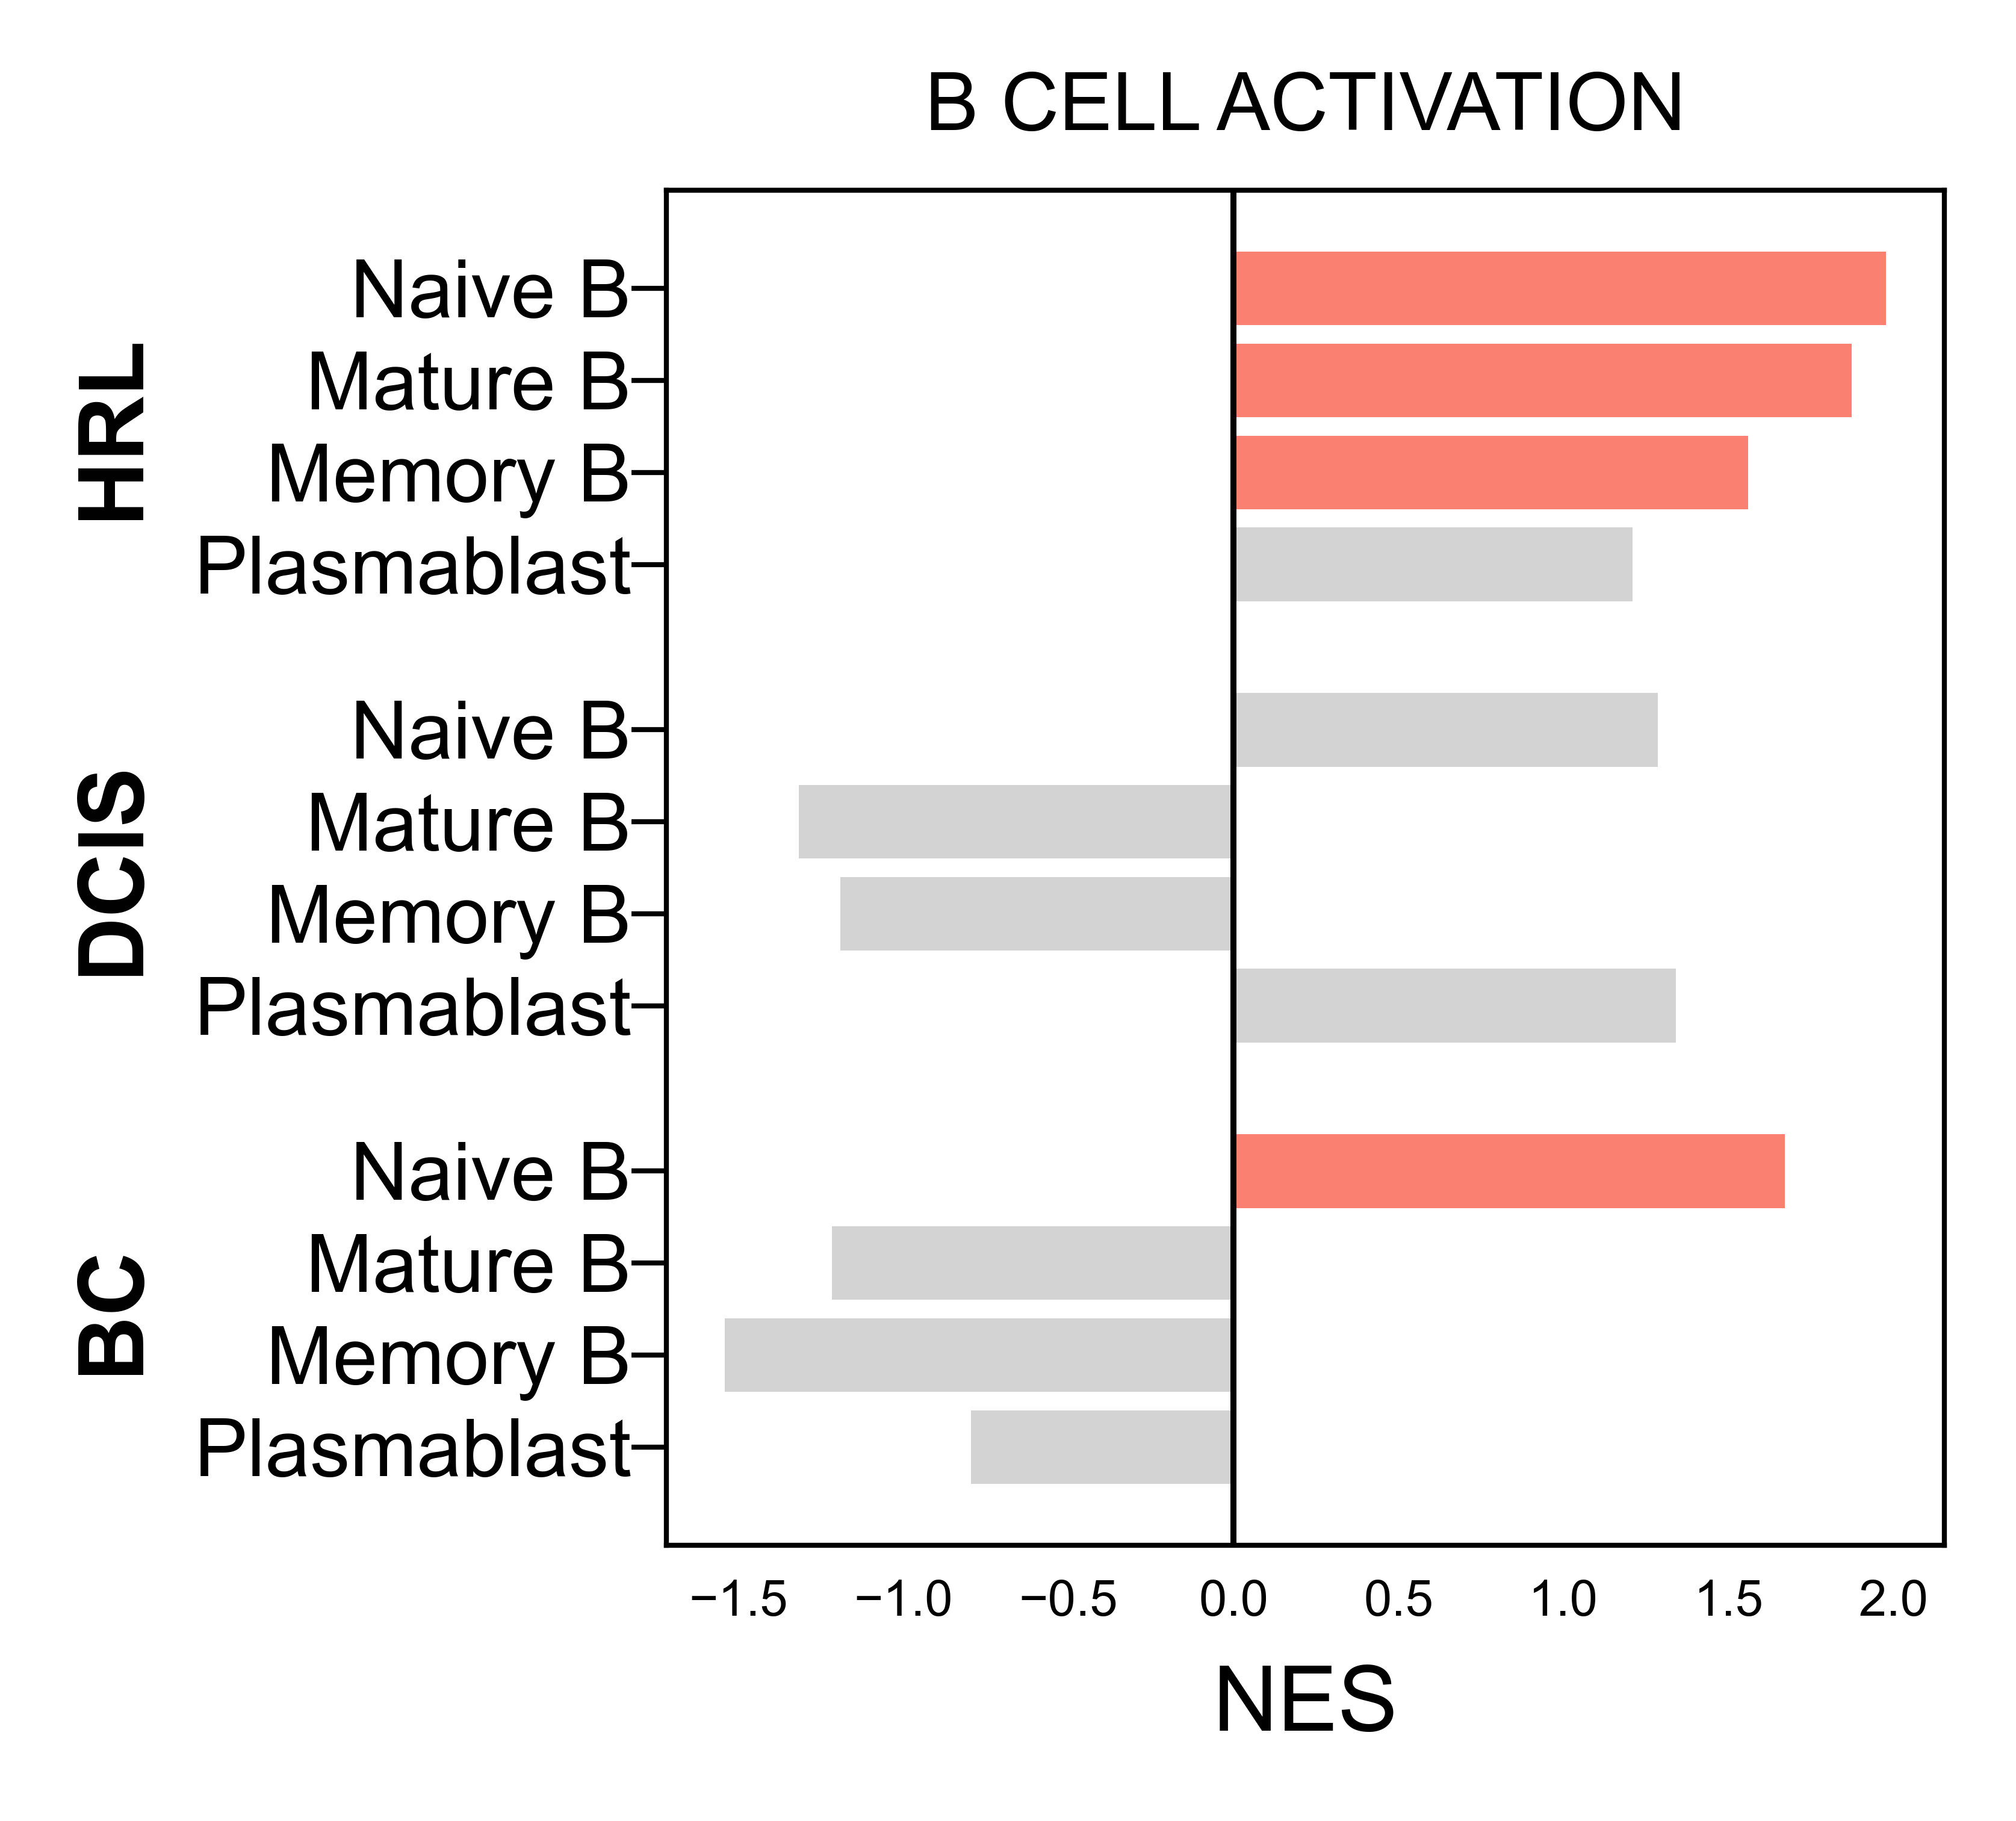

In [32]:
qthres = .1


df = dfp.copy()
df['ct'] = df['analysis_celltype']#.map(abbr)

group_order = df['analysis_group'].unique()
ct_order = [
    'Naive B',    # Naive
    'Mature B',   # Central memory
    'Memory B',   # Effector memory
    'Plasmablast'       # Regulatory (parallel lineage)
]

# ---- build plotting table ----
rows = []
y = 0
gap = 0.8
group_centers = {}

for g in group_order:
    sub = df[df['analysis_group'] == g]
    start = y
    for ct in ct_order:
        r = sub[sub['ct'] == ct]
        if not r.empty:
            r = r.iloc[0]
            rows.append({
                'y': y,
                'NES': r['NES'],
                'q': r['FDR q-val'],
                'ct': ct,
                'group': g
            })
            y += 1
    group_centers[g] = (start + y - 1) / 2
    y += gap

plot_df = pd.DataFrame(rows)

# ---- colors ----
colors = [
    'salmon' if (q < qthres and nes > 0)
    else 'skyblue' if (q < qthres and nes < 0)
    else 'lightgray'
    for nes, q in zip(plot_df['NES'], plot_df['q'])
]

# ---- plot ----
fig, ax = plt.subplots(figsize=(3, 2.5))
ax.barh(plot_df['y'], plot_df['NES'], color=colors)
ax.axvline(0, color='black', lw=0.6)

ax.set_title(path_sel, fontsize=8)
ax.set_yticks(plot_df['y'])
ax.set_yticklabels(plot_df['ct'], fontsize=8)

# ---- group labels ----
for g, yc in group_centers.items():
    ax.text(
        -0.4, yc, g,
        ha='right', va='center',
        fontsize=9, fontweight='bold',
        rotation=90,
        transform=ax.get_yaxis_transform()
    )

ax.set_xlabel('NES', fontsize=9)
ax.invert_yaxis()
plt.tight_layout()

plt.savefig(f'plots/F7_2/{celltype_major}_{path_sel}.svg')

In [38]:
path_sel = 'ANTIMICROBIAL HUMORAL RESPONSE'

dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
dfp

,analysis_celltype,analysis_group,NES,FDR q-val
2,Naive B,HRL,-2.032756,0.000353
0,Naive B,DCIS,-2.202768,0.000000
10,Naive B,BC,-1.663920,0.031926
0,Mature B,HRL,-2.335356,0.000000
6,Mature B,DCIS,-1.631417,0.027714
26,Mature B,BC,-1.330264,0.194700
17,Memory B,HRL,-1.485938,0.092240
8,Memory B,DCIS,-1.573030,0.083123
27,Memory B,BC,1.266994,0.413918
100,Plasmablast,HRL,0.770921,1.000000


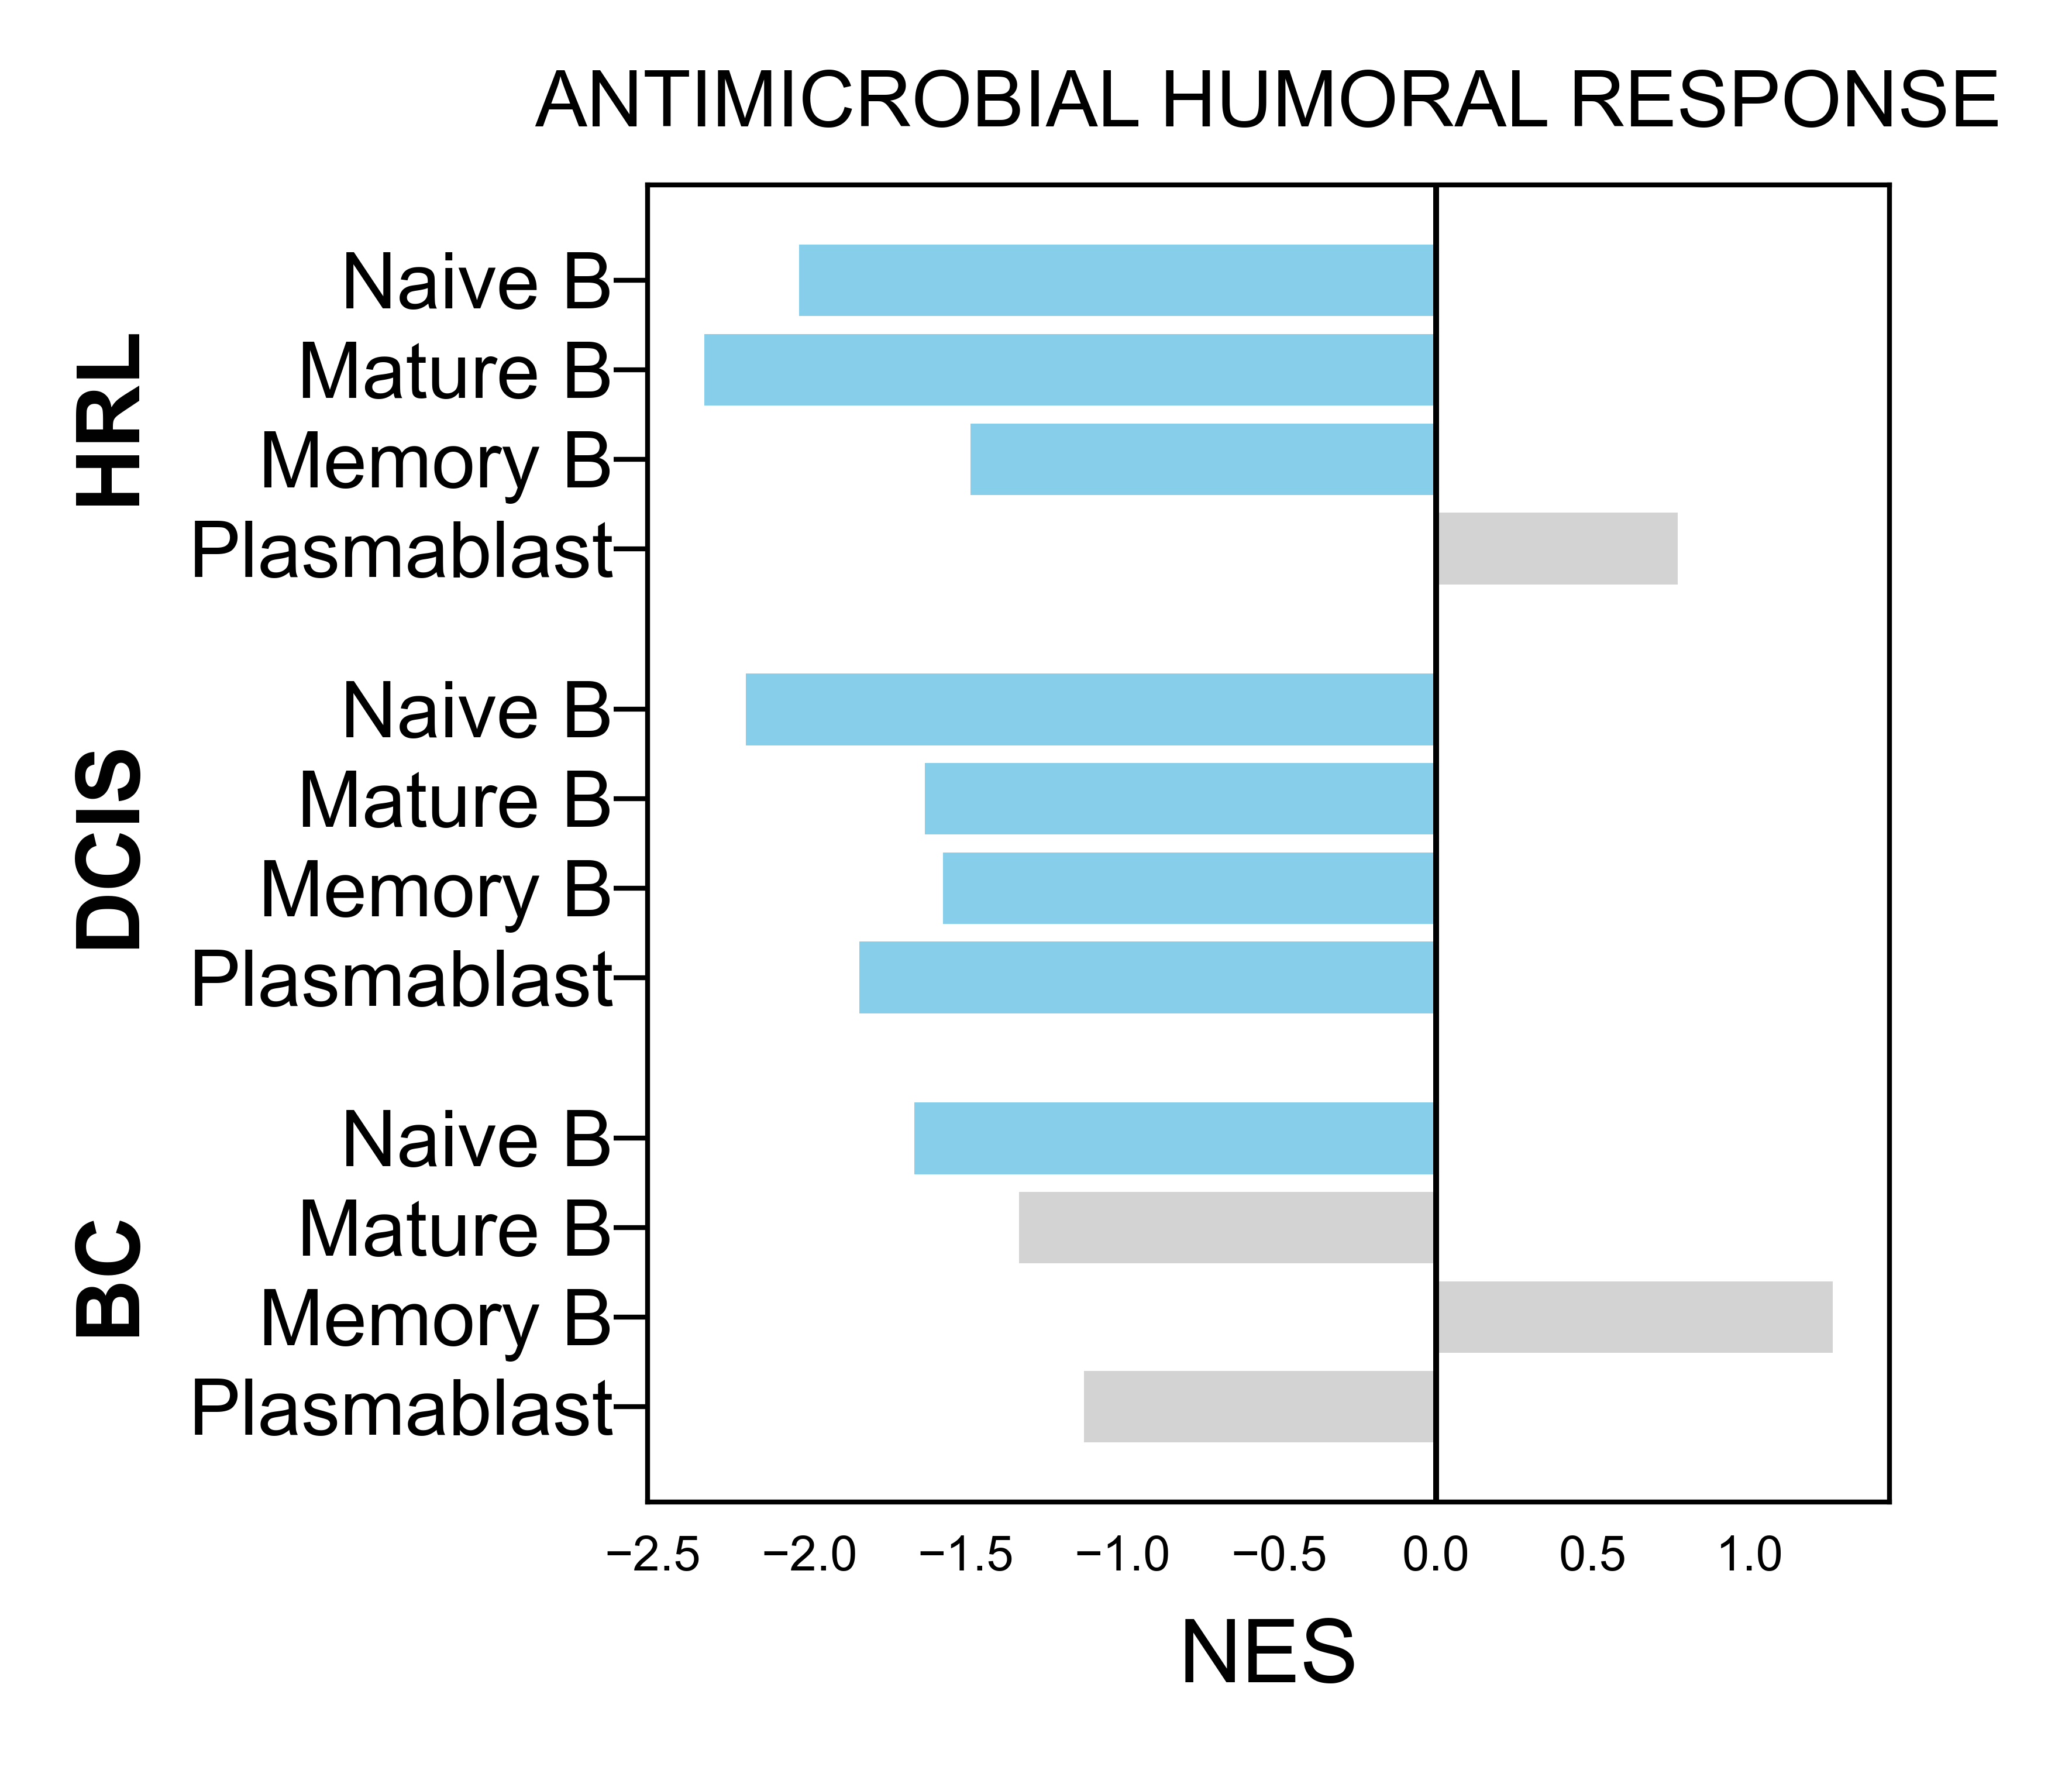

In [39]:
qthres = .1


df = dfp.copy()
df['ct'] = df['analysis_celltype']#.map(abbr)

group_order = df['analysis_group'].unique()
ct_order = [
    'Naive B',    # Naive
    'Mature B',   # Central memory
    'Memory B',   # Effector memory
    'Plasmablast'       # Regulatory (parallel lineage)
]

# ---- build plotting table ----
rows = []
y = 0
gap = 0.8
group_centers = {}

for g in group_order:
    sub = df[df['analysis_group'] == g]
    start = y
    for ct in ct_order:
        r = sub[sub['ct'] == ct]
        if not r.empty:
            r = r.iloc[0]
            rows.append({
                'y': y,
                'NES': r['NES'],
                'q': r['FDR q-val'],
                'ct': ct,
                'group': g
            })
            y += 1
    group_centers[g] = (start + y - 1) / 2
    y += gap

plot_df = pd.DataFrame(rows)

# ---- colors ----
colors = [
    'salmon' if (q < qthres and nes > 0)
    else 'skyblue' if (q < qthres and nes < 0)
    else 'lightgray'
    for nes, q in zip(plot_df['NES'], plot_df['q'])
]

# ---- plot ----
fig, ax = plt.subplots(figsize=(3, 2.5))
ax.barh(plot_df['y'], plot_df['NES'], color=colors)
ax.axvline(0, color='black', lw=0.6)

ax.set_title(path_sel, fontsize=8)
ax.set_yticks(plot_df['y'])
ax.set_yticklabels(plot_df['ct'], fontsize=8)

# ---- group labels ----
for g, yc in group_centers.items():
    ax.text(
        -0.4, yc, g,
        ha='right', va='center',
        fontsize=9, fontweight='bold',
        rotation=90,
        transform=ax.get_yaxis_transform()
    )

ax.set_xlabel('NES', fontsize=9)
ax.invert_yaxis()
plt.tight_layout()

plt.savefig(f'plots/F7_2/{celltype_major}_{path_sel}.svg')

## DzState

In [10]:
celltype_major = 'B'

In [11]:
cts = 0


for group in ['HRL','DCIS','BC']:

    for db in ['hallmark','immport']:

        cts += 1
        
        raw = pd.read_csv(
            f'data/Figure7_2/CNArankNHBvsW_{celltype_major}_{group}_{db}.csv', 
            index_col=0)
        
        dfp = raw#[raw['FDR q-val']<0.05].sort_values('NES', ascending=False)

        dfp['Tag %'] = (
            dfp['Tag %']
            .astype(str)
            .apply(lambda x: eval(x) if '/' in x else float(x))
        )
        dfp['Tag %'] = dfp['Tag %'] * 100
        dfp['log_p'] = -np.log10(dfp['FDR q-val'].replace(0, 1e-300))
        
        # Sort by NES
        dfp = dfp.sort_values('NES', ascending=False)
        
        # filter - 
        # dfp = dfp[dfp['Tag %']>=30]
        dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]


        dfp['analysis_group'] = [group]*dfp.shape[0]
        dfp['analysis_db'] = [db]*dfp.shape[0]

        out = dfp if cts==1 else pd.concat([out, dfp])


out        

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p,analysis_group,analysis_db
0,prerank,MITOTIC SPINDLE,0.714117,1.835586,0.0,0.000000,0.000,59.798995,17.41%,TRIO;SSH2;RAPGEF5;SPTBN1;DOCK2;EZR;NEDD9;NIN;G...,300.000000,HRL,hallmark
2,prerank,UV RESPONSE DN,0.682391,1.743907,0.0,0.000000,0.000,33.093525,8.95%,ANXA4;ATP2B1;PRKCE;PTEN;SMAD3;CELF2;ANXA2;SIPA...,300.000000,HRL,hallmark
3,prerank,G2M CHECKPOINT,0.616318,1.599083,0.0,0.000988,0.003,49.230769,21.11%,LBR;FOXN3;SMAD3;SLC38A1;STAG1;RPS6KA5;PAFAH1B1...,3.005368,HRL,hallmark
4,prerank,PI3K AKT MTOR SIGNALING,0.626468,1.559806,0.0,0.001975,0.008,53.921569,22.02%,PRKCB;PTEN;VAV3;MAPK1;ACTR2;PIKFYVE;ACTR3;CDKN...,2.704338,HRL,hallmark
5,prerank,PROTEIN SECRETION,0.612534,1.518879,0.0,0.004939,0.024,60.000000,20.48%,SSPN;AP3B1;ADAM10;MAPK1;ARFGEF1;MON2;DOP1A;SGM...,2.306398,HRL,hallmark
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4,prerank,INTERLEUKIN-1 FAMILY SIGNALING,-0.575349,-1.776524,0.0,0.004313,0.023,44.520548,11.77%,RPS27A;PTPN6;PSMB9;PSMA7;PSME1;ALOX5;UBB;UBA52...,2.365175,BC,immport
3,prerank,INNATE IMMUNE RESPONSE IN MUCOSA,-0.885114,-1.785876,0.0,0.004529,0.019,16.666667,0.27%,RPL39;FAU,2.343986,BC,immport
2,prerank,NEUTROPHIL DEGRANULATION,-0.534711,-1.788598,0.0,0.005464,0.017,35.176991,11.33%,EEF1A1;FTL;HLA-B;EEF2;B2M;PTPN6;CTSH;GMFG;HLA-...,2.262513,BC,immport
1,prerank,ANTIGEN PROCESSING AND PRESENTATION,-0.639577,-1.863355,0.0,0.000863,0.002,29.347826,6.51%,HLA-DPA1;HLA-B;CD74;B2M;CD1C;HLA-DRA;CTSH;HLA-...,3.064145,BC,immport


In [12]:
DzState, db = 'HRL', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['B CELL DIFFERENTIATION', 'B CELL ACTIVATION',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
       'INTERLEUKIN-2 FAMILY SIGNALING',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'RESPIRATORY BURST INVOLVED IN DEFENSE RESPONSE',
       'GAMMA-DELTA T CELL ACTIVATION', 'RAP1 SIGNALLING',
       'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
       'GROWTH HORMONE RECEPTOR SIGNALING',
       'NATURAL KILLER CELL ACTIVATION', 'TOLERANCE INDUCTION',
       'LYMPHOCYTE PROLIFERATION', 'LEUKOCYTE HOMEOSTASIS',
       'T CELL COSTIMULATION', 'LYMPHOCYTE COSTIMULATION',
       'ALPHA-BETA T CELL ACTIVATION',
       'NATURAL KILLER CELL MEDIATED CYTOTO

In [13]:
paths_sel = [
    'B CELL DIFFERENTIATION', 
    'B CELL ACTIVATION',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       # 'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
       'INTERLEUKIN-2 FAMILY SIGNALING',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       # 'RESPIRATORY BURST INVOLVED IN DEFENSE RESPONSE',
       # 'GAMMA-DELTA T CELL ACTIVATION', 
      'RAP1 SIGNALLING',
       # 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
       # 'GROWTH HORMONE RECEPTOR SIGNALING',
       # 'NATURAL KILLER CELL ACTIVATION', 
    # 'TOLERANCE INDUCTION',
       'LYMPHOCYTE PROLIFERATION', 
    'LEUKOCYTE HOMEOSTASIS',
       # 'T CELL COSTIMULATION', 
    'LYMPHOCYTE COSTIMULATION',
       # 'ALPHA-BETA T CELL ACTIVATION',
       # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       # 'T CELL PROLIFERATION', 
    # 'NATURAL KILLER CELL DIFFERENTIATION',
       # 'LEUKOCYTE DEGRANULATION', 
    # 'T CELL DIFFERENTIATION',
       # 'NATURAL KILLER CELL MEDIATED IMMUNITY', 
    'DAP12 INTERACTIONS',
       'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'CLASS I MHC MEDIATED ANTIGEN PROCESSING & PRESENTATION',
       # 'MYELOID LEUKOCYTE ACTIVATION',
       'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       # 'COSTIMULATION BY THE CD28 FAMILY', 
      'GERMINAL CENTER FORMATION',
       'NEGATIVE REGULATION OF ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS',
       # 'ANTIFUNGAL INNATE IMMUNE RESPONSE',
       'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'INTERLEUKIN-20 FAMILY SIGNALING',
       'FC EPSILON RECEPTOR (FCERI) SIGNALING',
       # 'ACTIVATION OF INNATE IMMUNE RESPONSE', 
       'INTERLEUKIN-7 SIGNALING',
       'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
       # 'NEGATIVE REGULATION OF CYTOPLASMIC PATTERN RECOGNITION RECEPTOR SIGNALING PATHWAY',
       'DIAPEDESIS',
       'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       'COMPLEMENT RECEPTOR MEDIATED SIGNALING PATHWAY',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       'INTERFERON GAMMA SIGNALING', 
       'MONONUCLEAR CELL MIGRATION',
       # 'C-TYPE LECTIN RECEPTORS (CLRS)', 
       'INTERLEUKIN-6 FAMILY SIGNALING',
       # 'ADVANCED GLYCOSYLATION ENDPRODUCT RECEPTOR SIGNALING',
       # 'ALPHA-PROTEIN KINASE 1 SIGNALING PATHWAY',
       # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       'ANTIMICROBIAL HUMORAL RESPONSE',
       'INNATE IMMUNE RESPONSE IN MUCOSA'
]

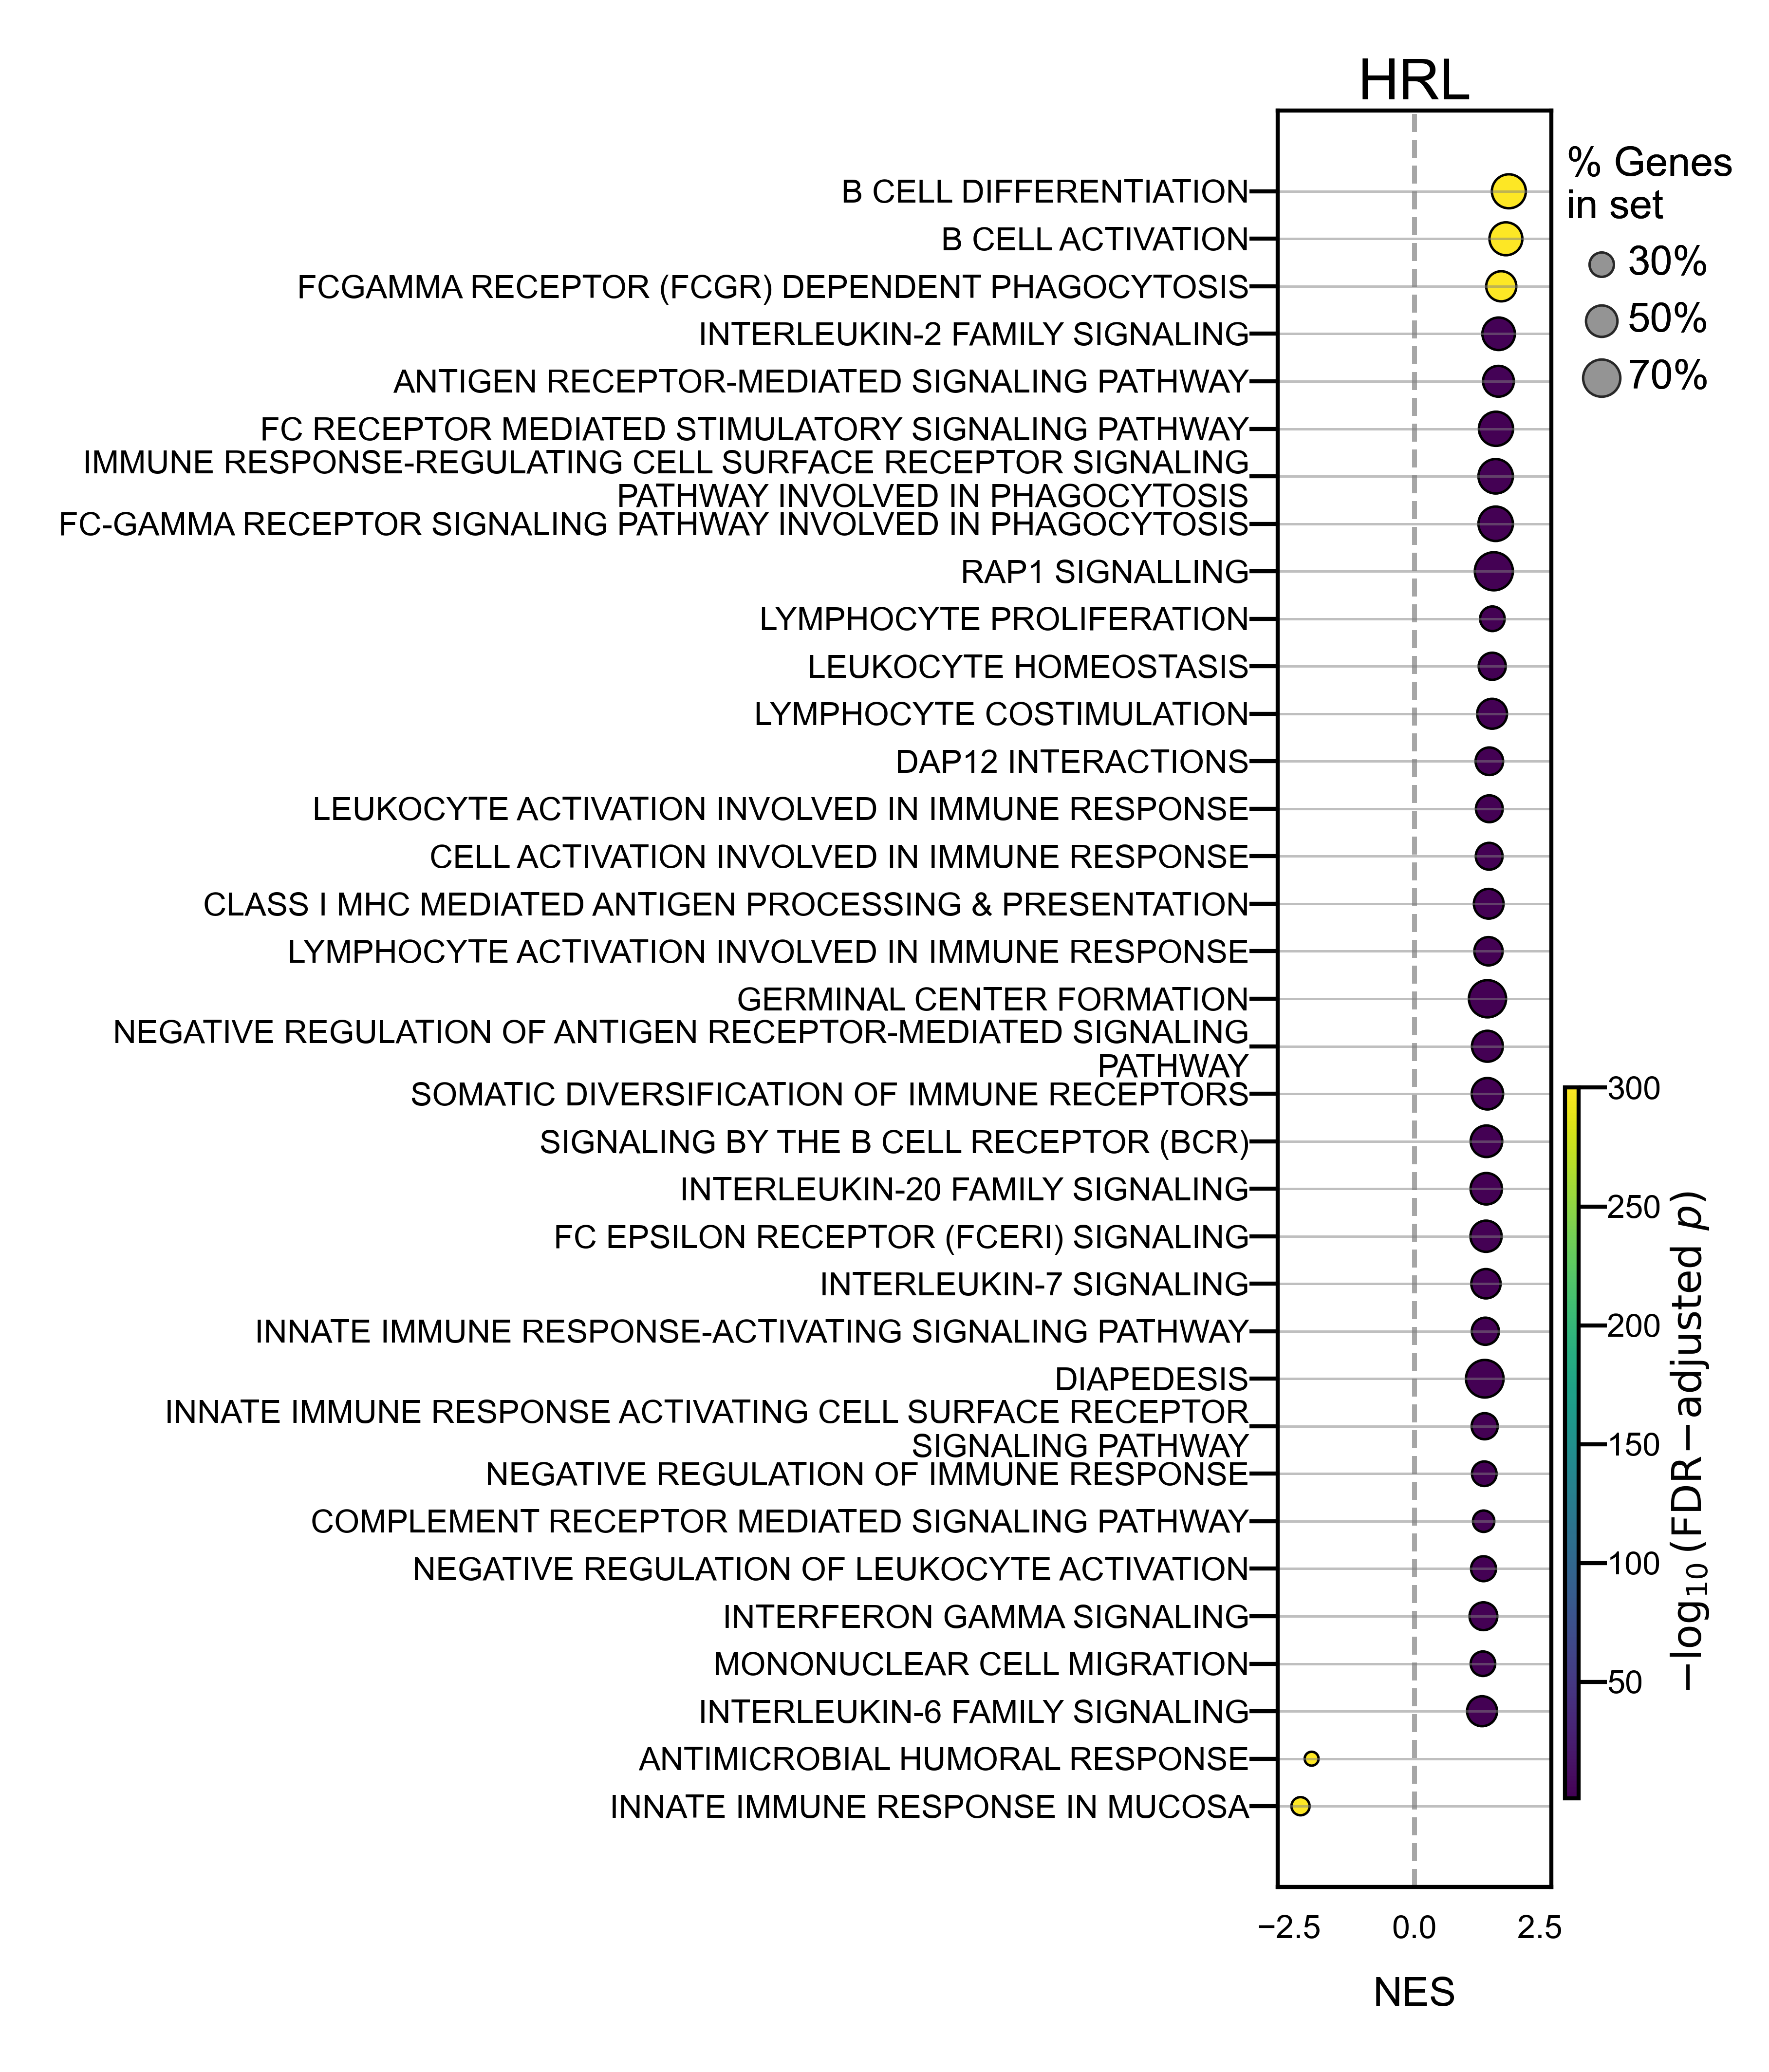

In [14]:
dfp2 = dfp[dfp['Term'].isin(paths_sel)].reset_index(drop=True)

wrap_width = 60
dfp2['Term'] = dfp2['Term'].apply(lambda x: fill(x, width=wrap_width))
# Parameters
dot_scale = .3   # smaller dot size multiplier
cmap = plt.cm.viridis

# Plot
fig, ax = plt.subplots(figsize=(.6
                                , 4))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=5)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=4)
ax.tick_params(axis='y', labelsize=4)
ax.set_title(DzState, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$-\log_{10}(\mathrm{FDR\!-\!adjusted\ }p)$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.8, 1)
)
ax.add_artist(leg1)
ax.axvline(
    x=0,
    linestyle='--',
    linewidth=0.6,
    color='gray',
    alpha=0.7,
    zorder=0
)
# plt.tight_layout()
plt.savefig(f"plots/S7_2/Bubble_B_{DzState}_{db}.jpg", 
            dpi=600, 
            bbox_inches='tight'
            )

In [15]:
DzState, db = 'DCIS', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['TCR SIGNALING', 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'INTERLEUKIN-12 FAMILY SIGNALING', 'LEUKOCYTE MEDIATED IMMUNITY',
       'ANTIGEN PROCESSING AND PRESENTATION',
       'INTERLEUKIN-1 FAMILY SIGNALING',
       'INTERFERON ALPHA/BETA SIGNALING',
       'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
       'T CELL MEDIATED CYTOTOXICITY', 'ANTIMICROBIAL HUMORAL RESPONSE',
       'INNATE IMMUNE RESPONSE IN MUCOSA',
       'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       'ROS AND RNS PRODUCTION IN PHAGOCYTES', 'NEUTROPHIL DEGRANULATION',
       'TNFR2 NON-CANONICAL NF-KB PATHWAY'], dtype=object)

In [16]:
paths_sel = [
# 'TCR SIGNALING', 
'SIGNALING BY THE B CELL RECEPTOR (BCR)',
'INTERLEUKIN-12 FAMILY SIGNALING', 
'LEUKOCYTE MEDIATED IMMUNITY',
'ANTIGEN PROCESSING AND PRESENTATION',
'INTERLEUKIN-1 FAMILY SIGNALING',
'INTERFERON ALPHA/BETA SIGNALING',
'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
# 'T CELL MEDIATED CYTOTOXICITY', 
'ANTIMICROBIAL HUMORAL RESPONSE',
'INNATE IMMUNE RESPONSE IN MUCOSA',
# 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
'ROS AND RNS PRODUCTION IN PHAGOCYTES', 
# 'NEUTROPHIL DEGRANULATION',
'TNFR2 NON-CANONICAL NF-KB PATHWAY'    
]

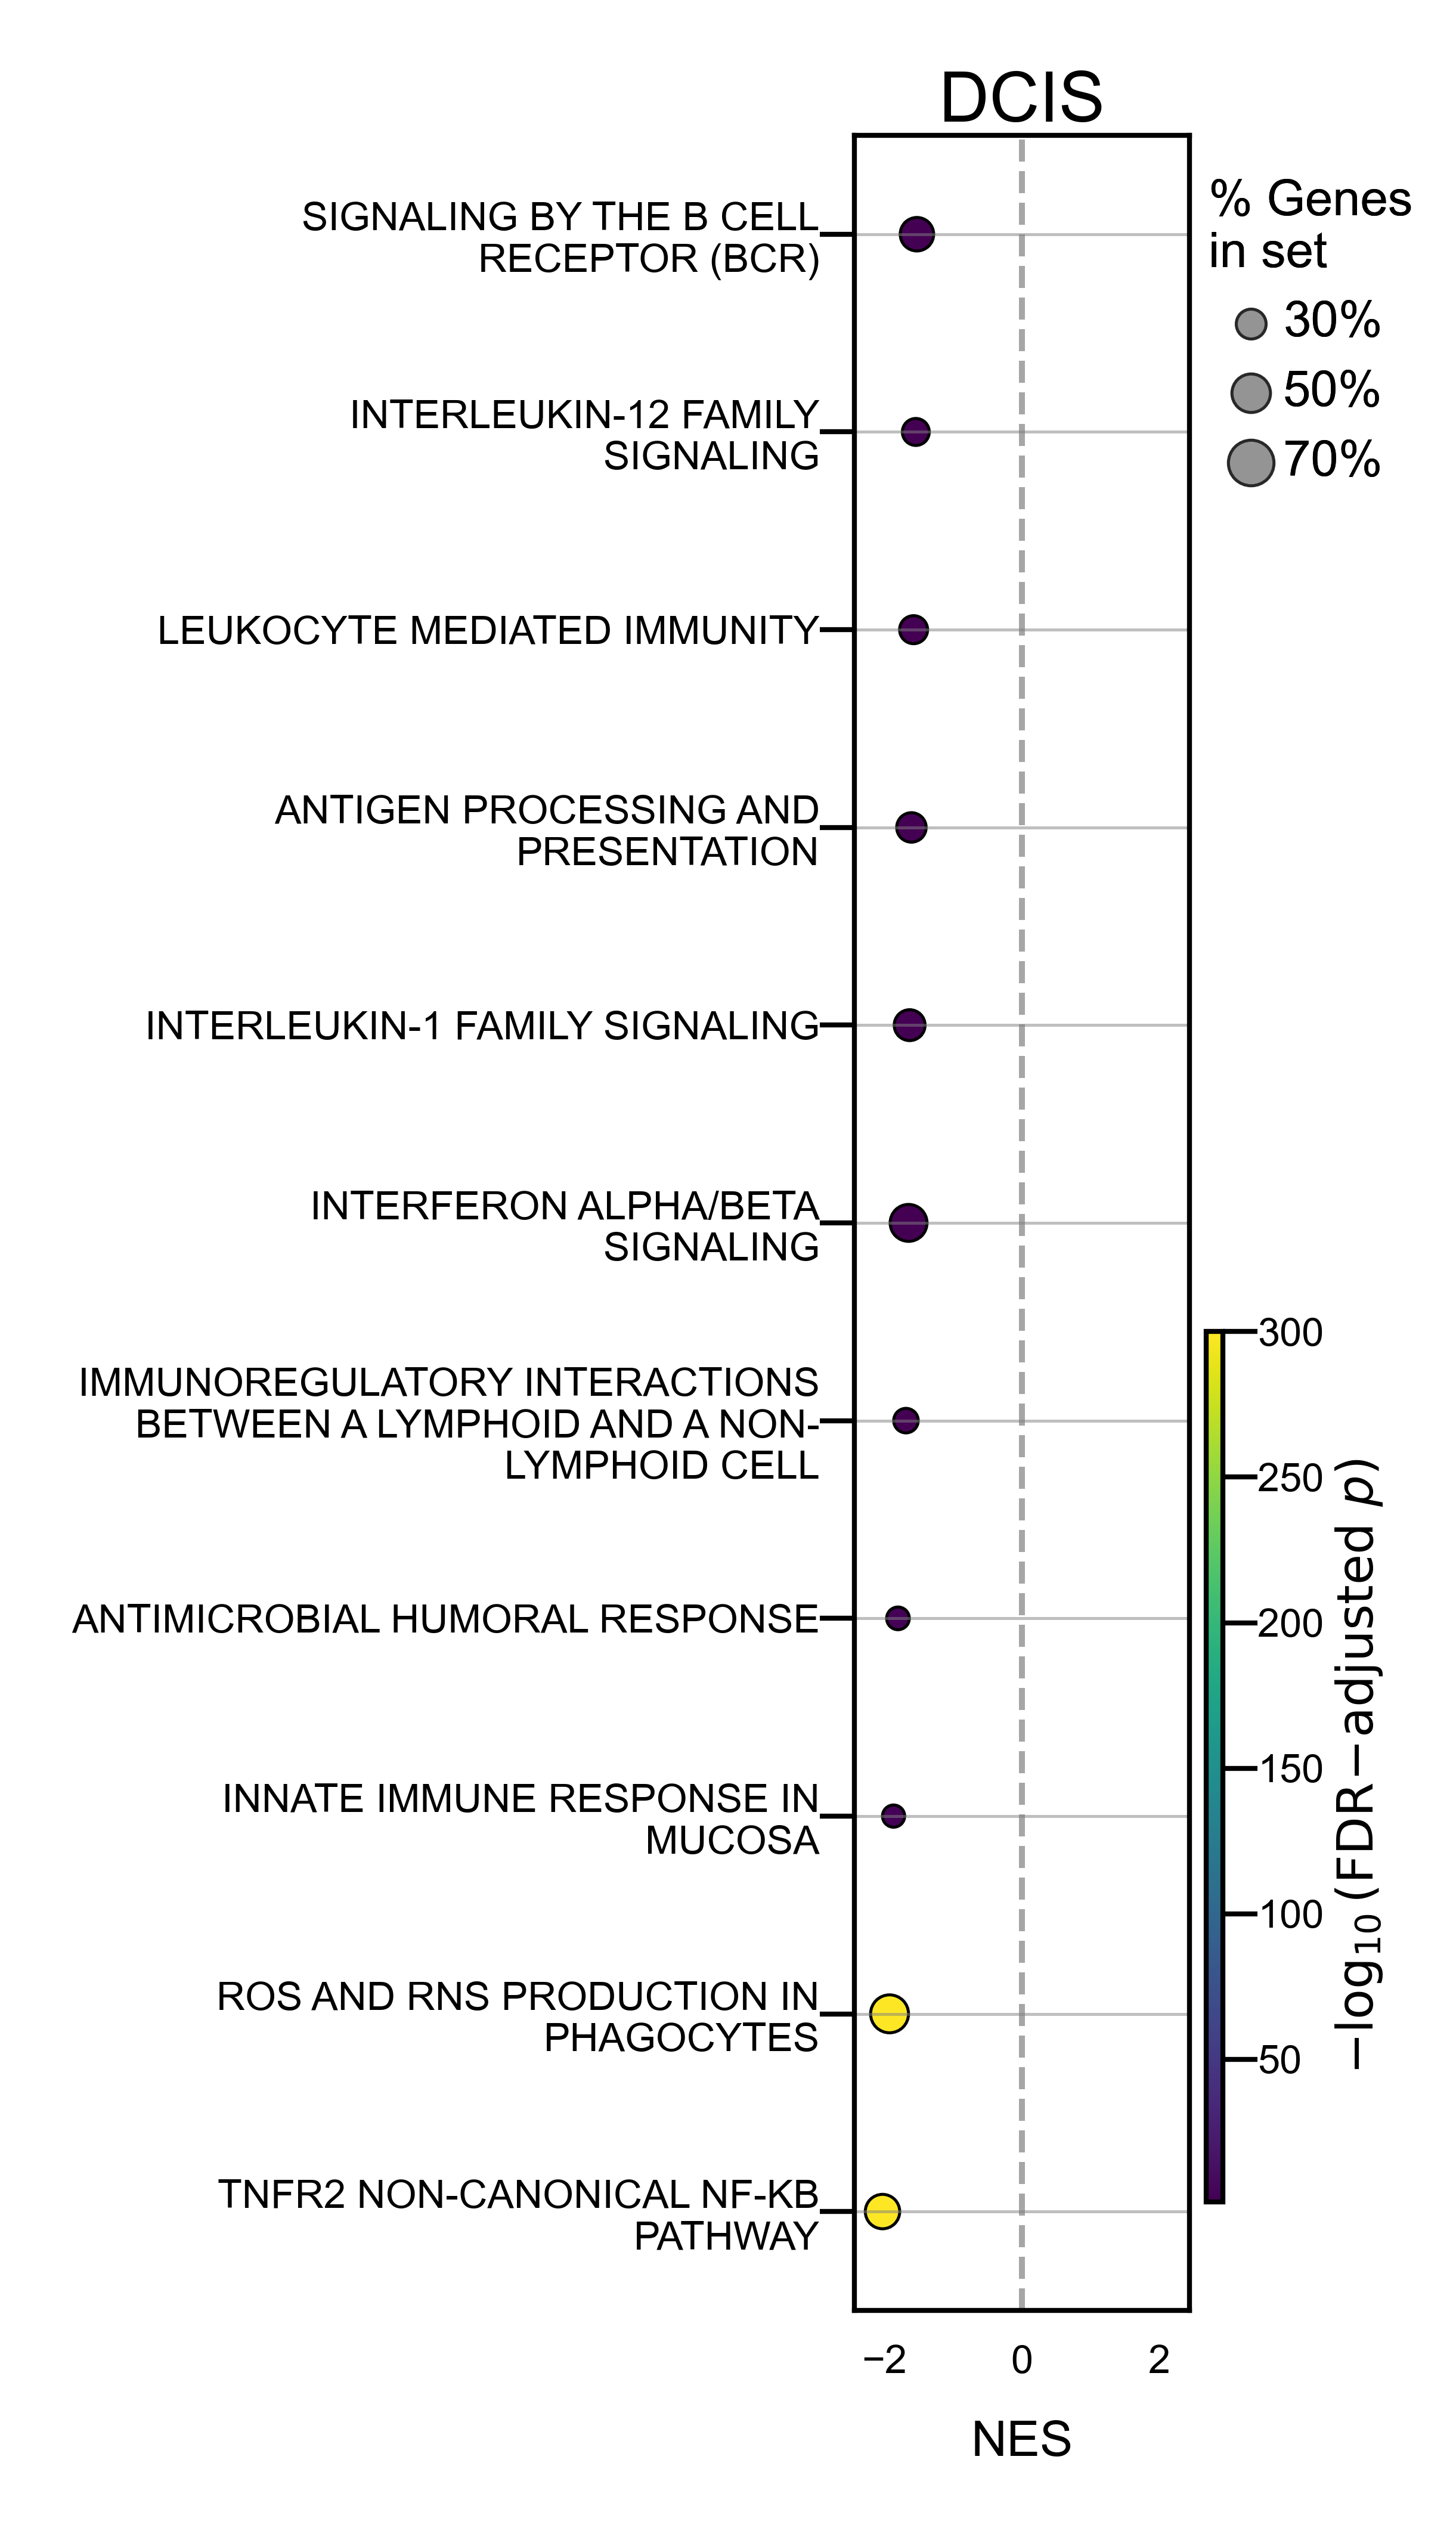

In [17]:
dfp2 = dfp[dfp['Term'].isin(paths_sel)].reset_index(drop=True)

wrap_width = 30
dfp2['Term'] = dfp2['Term'].apply(lambda x: fill(x, width=wrap_width))
# Parameters
dot_scale = .3   # smaller dot size multiplier
cmap = plt.cm.viridis


# Plot
fig, ax = plt.subplots(figsize=(.6
                                , 4))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=5)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=4)
ax.tick_params(axis='y', labelsize=4)
ax.set_title(DzState, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$-\log_{10}(\mathrm{FDR\!-\!adjusted\ }p)$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.8, 1)
)
ax.add_artist(leg1)
ax.axvline(
    x=0,
    linestyle='--',
    linewidth=0.6,
    color='gray',
    alpha=0.7,
    zorder=0
)
# plt.tight_layout()
plt.savefig(f"plots/S7_2/Bubble_B_{DzState}_{db}.jpg", 
            dpi=600, 
            bbox_inches='tight'
            )

In [18]:
DzState, db = 'BC', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['TOLERANCE INDUCTION', 'ALPHA-BETA T CELL ACTIVATION',
       'T CELL DIFFERENTIATION',
       'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
       'ANTIMICROBIAL PEPTIDES', 'INTERLEUKIN-12 FAMILY SIGNALING',
       'INTERFERON ALPHA/BETA SIGNALING',
       'C-TYPE LECTIN RECEPTORS (CLRS)', 'MYELOID CELL HOMEOSTASIS',
       'CYTOSOLIC SENSORS OF PATHOGEN-ASSOCIATED DNA ',
       'ANTIMICROBIAL HUMORAL RESPONSE',
       'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       'ALPHA-PROTEIN KINASE 1 SIGNALING PATHWAY',
       'MHC CLASS II ANTIGEN PRESENTATION',
       'SIGNALING BY THE B CELL RECEPTOR (BCR)', 'TCR SIGNALING',
       'INTERFERON GAMMA SIGNALING',
       'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       'INTERLEUKIN-1 FAMILY SIGNALING',
       'INNATE IMMUNE RESPONSE IN MUCOSA', 'NEUTROPHIL DEGRANULATION',
       'ANTIGEN PROCESSING AND PRESENTATION',
       'TNFR2 NON-CANONICAL NF-KB PATHWAY'], dtype=object)

In [19]:
paths_sel = [
'TOLERANCE INDUCTION', 
# 'ALPHA-BETA T CELL ACTIVATION',
# 'T CELL DIFFERENTIATION',
# 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
'ANTIMICROBIAL PEPTIDES', 
'INTERLEUKIN-12 FAMILY SIGNALING',
'INTERFERON ALPHA/BETA SIGNALING',
# 'C-TYPE LECTIN RECEPTORS (CLRS)', 
# 'MYELOID CELL HOMEOSTASIS',
# 'CYTOSOLIC SENSORS OF PATHOGEN-ASSOCIATED DNA ',
'ANTIMICROBIAL HUMORAL RESPONSE',
'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
# 'ALPHA-PROTEIN KINASE 1 SIGNALING PATHWAY',
'MHC CLASS II ANTIGEN PRESENTATION',
'SIGNALING BY THE B CELL RECEPTOR (BCR)', 
    # 'TCR SIGNALING',
'INTERFERON GAMMA SIGNALING',
'ROS AND RNS PRODUCTION IN PHAGOCYTES',
'INTERLEUKIN-1 FAMILY SIGNALING',
'INNATE IMMUNE RESPONSE IN MUCOSA', 
    # 'NEUTROPHIL DEGRANULATION',
'ANTIGEN PROCESSING AND PRESENTATION',
'TNFR2 NON-CANONICAL NF-KB PATHWAY'    
]

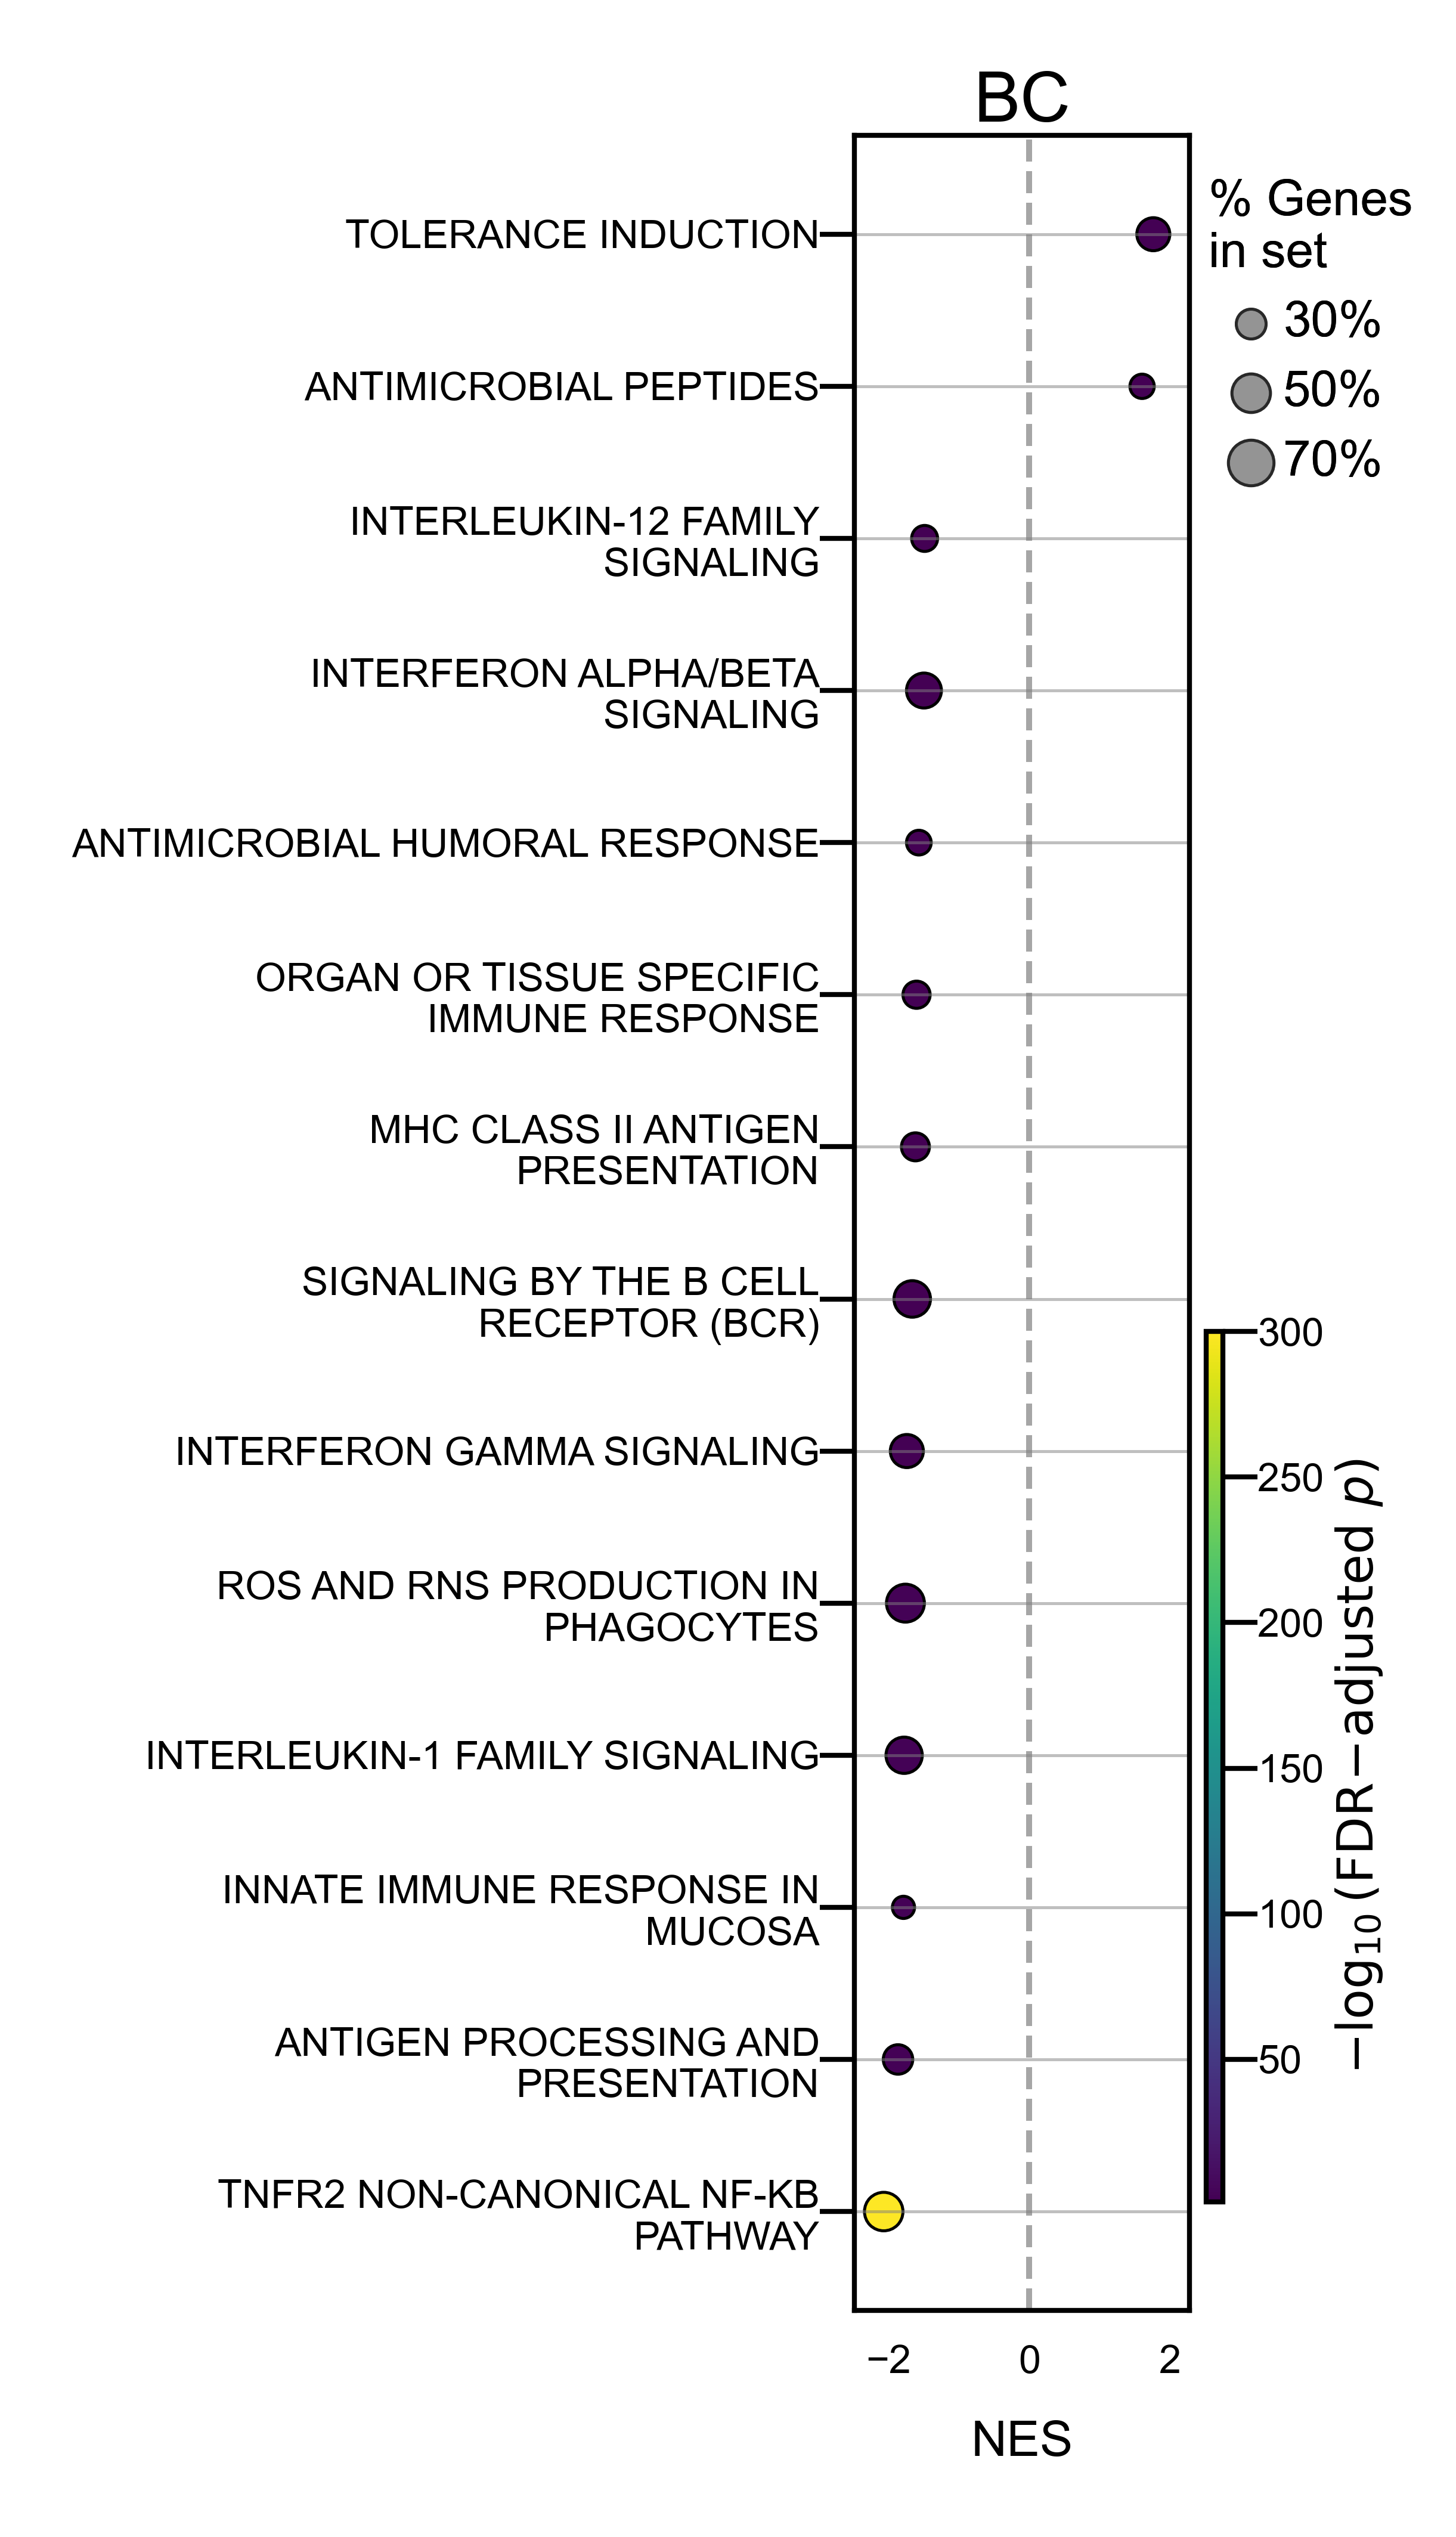

In [20]:
dfp2 = dfp[dfp['Term'].isin(paths_sel)].reset_index(drop=True)

wrap_width = 30
dfp2['Term'] = dfp2['Term'].apply(lambda x: fill(x, width=wrap_width))
# Parameters
dot_scale = .3   # smaller dot size multiplier
cmap = plt.cm.viridis


# Plot
fig, ax = plt.subplots(figsize=(.6
                                , 4))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.1])

ax.set_xlabel("NES", fontsize=5)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=4)
ax.tick_params(axis='y', labelsize=4)
ax.set_title(DzState, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$-\log_{10}(\mathrm{FDR\!-\!adjusted\ }p)$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.8, 1)
)
ax.add_artist(leg1)
ax.axvline(
    x=0,
    linestyle='--',
    linewidth=0.6,
    color='gray',
    alpha=0.7,
    zorder=0
)
# plt.tight_layout()
plt.savefig(f"plots/S7_2/Bubble_B_{DzState}_{db}.jpg", 
            dpi=600, 
            bbox_inches='tight'
            )